# Global disaster impact analysis using EM-DAT
## Revised analysis of event-country records from 2000 to 2025

The analysis profiles reports in the fixed 13 March 2026 EM-DAT snapshot and evaluates retrospective classification and regression. Use the configuration below or set the EMDAT_PROFILE, EMDAT_DATASET and EMDAT_OUTPUT_DIR environment variables. Run the notebook from top to bottom in a fresh Python kernel.

* Task A classifies eligible disaster types using country, subregion, region and season.
* Tasks S2 and S3 classify relative severity using recorded disaster descriptors. Their labels use separate 2000-2007 complete-case reference cohorts.
* The three Task C models estimate reported deaths, people affected and adjusted damage on the log1p scale. Adjusted damage is unavailable in 2025 in this snapshot.
* Expanding chronological validation supports model selection through 2017. Later identified records form a temporal benchmark. Country-held-out and event-grouped split comparisons use a common untuned LightGBM model.
* Outcome-derived features appear in named retrospective sensitivity analyses. History means use strictly earlier training records outside the same event and carry valid earlier totals across missing years.

Per-task manifests, predictions, calibration parameters, tables, models, figures and a run report are written to the configured output folder. The manuscript reports the full profile.

## 1 · Environment, configuration

In [1]:
import os, sys, warnings, json, datetime, time, re, hashlib, platform
from importlib import metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import joblib
from IPython.display import display

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.model_selection import GroupShuffleSplit, RandomizedSearchCV
from sklearn.linear_model import LogisticRegression, Ridge, LinearRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score, log_loss, confusion_matrix,
                             precision_recall_fscore_support, mean_absolute_error, mean_squared_error, r2_score,
                             median_absolute_error)
from xgboost import XGBClassifier, XGBRegressor
from lightgbm import LGBMClassifier, LGBMRegressor
from catboost import CatBoostClassifier, CatBoostRegressor
try:
    import shap; SHAP_OK = True
except ImportError:
    SHAP_OK = False; print('SHAP not installed - SHAP section skipped.')

# NOTE: warnings are deliberately NOT suppressed globally. Any recurring warning is reviewed in Section 18.
pd.set_option('display.max_columns', 80); pd.set_option('display.max_rows', 150)
sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 300, 'font.size': 11})
SEED = 42   # every stochastic component receives an explicit seed / RandomState (the NumPy global RNG is not used)

NOTEBOOK_VERSION = 'v5'
PROFILE = os.environ.get('EMDAT_PROFILE', 'full').strip().lower()
PROFILES = {
    'debug': dict(n_est=15,  cat_iter=15,  rf_trees=15,  tune_iter=2,  shap_n=50,  n_boot=40, protocol_repeats=2),
    'quick': dict(n_est=150, cat_iter=120, rf_trees=150, tune_iter=6,  shap_n=300, n_boot=500, protocol_repeats=3),
    'full':  dict(n_est=400, cat_iter=500, rf_trees=400, tune_iter=30, shap_n=600, n_boot=2000, protocol_repeats=10),
}
if PROFILE not in PROFILES:
    raise ValueError(f'EMDAT_PROFILE must be one of {tuple(PROFILES)}')
P = PROFILES[PROFILE]

# ---------------- chronological protocol ----------------
REF_END    = 2007            # severity calibration reference period 2000-2007 (used ONLY to calibrate labels)
TRAIN_END  = 2017            # development window ends
TEST_START = 2018            # final holdout 2018-2025
CV_FOLDS_ALL = [(2009, (2010, 2011)), (2011, (2012, 2013)), (2013, (2014, 2015)), (2015, (2016, 2017))]
CV_FOLDS_SEV = [(2011, (2012, 2013)), (2013, (2014, 2015)), (2015, (2016, 2017))]   # severity: training starts 2008
MIN_DEV_CLASS, MIN_FIRST_WINDOW = 50, 10
T0 = time.time()
def tick(msg=''): print(f'[{(time.time()-T0)/60:6.1f} min] {msg}')
print(f'Profile={PROFILE} | reference <= {REF_END} | development 2000-{TRAIN_END} | holdout >= {TEST_START}')

Profile=full | reference <= 2007 | development 2000-2017 | holdout >= 2018


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
OUTPUT_ROOT = os.environ.get('EMDAT_OUTPUT_DIR', f'outputs_{NOTEBOOK_VERSION}_{PROFILE}')
DIRS = {k: os.path.join(OUTPUT_ROOT, k) for k in ['tables','figures','models','reports','predictions','manifests','reproducibility']}
for d in DIRS.values(): os.makedirs(d, exist_ok=True)
_fig_n = [0]
def savefig(fig, name):
    _fig_n[0] += 1; fname = f'F{_fig_n[0]:02d}_{name}.png'
    fig.savefig(os.path.join(DIRS['figures'], fname), dpi=300, bbox_inches='tight', facecolor='white')
    plt.show(); plt.close(fig); print('  saved', fname)
def save_table(t, name, idx=True):
    t.to_csv(os.path.join(DIRS['tables'], name), index=idx); print('  saved', name)

## 2 · Data loading

In [3]:
override = os.environ.get('EMDAT_DATASET')
candidates = [override] if override else ['dataset.xlsx', os.path.join('..', 'dataset.xlsx')]
DATA_FILE = next((path for path in candidates if os.path.isfile(path)), None)
if DATA_FILE is None:
    raise FileNotFoundError('Specify the EM-DAT snapshot with EMDAT_DATASET or put dataset.xlsx beside the notebook.')
with open(DATA_FILE, 'rb') as workbook:
    DATA_SHA256 = hashlib.file_digest(workbook, 'sha256').hexdigest()
xl = pd.ExcelFile(DATA_FILE, engine='openpyxl')
sheet = 'EM-DAT Data'
if sheet not in xl.sheet_names:
    raise ValueError('Expected the EM-DAT Data worksheet in the analytical snapshot.')
df_raw = xl.parse(sheet)
print(f'{os.path.basename(DATA_FILE)} | sha256 {DATA_SHA256} | {len(df_raw):,} records by {df_raw.shape[1]} variables')
tick('loaded')

dataset.xlsx | sha256 d1e873e53071fffe9264f81a40b2673b0785c6b032601ca177426d27808ce1d6 | 16,697 records by 47 variables
[   0.2 min] loaded


## 3 · Cleaning

**Terminology.** One row is an *event-country record* (`DisNo.` is unique per record). Records sharing the first nine characters of `DisNo.` belong to the same *unique disaster event* (`event_id`) recorded in several countries. Nothing is imputed here; invalid values are flagged rather than silently repaired.

In [4]:
RENAME = {
 'DisNo.':'dis_no','Disaster Group':'disaster_group','Disaster Subgroup':'disaster_subgroup','Disaster Type':'disaster_type',
 'Disaster Subtype':'disaster_subtype','Country':'country','ISO':'iso','Subregion':'subregion','Region':'region',
 'OFDA/BHA Response':'ofda_response','Appeal':'appeal','Declaration':'declaration',"AID Contribution ('000 US$)":'aid_contribution',
 'Magnitude':'magnitude','Magnitude Scale':'magnitude_scale','Latitude':'latitude','Longitude':'longitude',
 'Start Year':'start_year','Start Month':'start_month','Start Day':'start_day','End Year':'end_year','End Month':'end_month',
 'End Day':'end_day','Total Deaths':'total_deaths','No. Injured':'no_injured','No. Affected':'no_affected','No. Homeless':'no_homeless',
 'Total Affected':'total_affected',"Total Damage ('000 US$)":'total_damage',"Total Damage, Adjusted ('000 US$)":'total_damage_adj',
 "Insured Damage ('000 US$)":'insured_damage',"Insured Damage, Adjusted ('000 US$)":'insured_damage_adj',
 "Reconstruction Costs ('000 US$)":'recon_cost',"Reconstruction Costs, Adjusted ('000 US$)":'recon_cost_adj','CPI':'cpi',
 'Entry Date':'entry_date','Last Update':'last_update','Classification Key':'classification_key',
}
df = df_raw.rename(columns=RENAME).copy()
assert df['dis_no'].is_unique and not df.duplicated().any()

IMPACT_NUM = ['total_deaths','no_injured','no_affected','no_homeless','total_affected','total_damage','total_damage_adj',
              'insured_damage','insured_damage_adj','recon_cost','recon_cost_adj','aid_contribution']
OTHER_NUM  = ['magnitude','latitude','longitude','cpi','start_year','start_month','start_day','end_year','end_month','end_day']
for c in IMPACT_NUM + OTHER_NUM: df[c] = pd.to_numeric(df[c], errors='coerce')

# ---- (2) invalid impact values: flagged and EXCLUDED from target construction, never clipped to zero ----
for c in IMPACT_NUM:
    df[f'{c}_raw'] = df[c]
    df[f'{c}_invalid'] = df[c] < 0
    df.loc[df[f'{c}_invalid'], c] = np.nan
inv_cols = [f'{c}_invalid' for c in IMPACT_NUM]
invalid_report = df.loc[df[inv_cols].any(axis=1), ['dis_no'] + [f'{c}_raw' for c in IMPACT_NUM] + inv_cols]
print(f'Records with at least one negative (invalid) impact value: {len(invalid_report)}')
invalid_report.to_csv(os.path.join(DIRS['tables'], 'T00_invalid_impact_values.csv'), index=False)

CATEGORICAL = ['disaster_group','disaster_subgroup','disaster_type','disaster_subtype','country','iso','subregion','region','magnitude_scale']
for c in CATEGORICAL: df[c] = df[c].fillna('Unknown').astype(str)       # 'Unknown' = category label, not a number

df['event_id'] = df['dis_no'].str[:9]
df = df.sort_values(['start_year', 'start_month', 'dis_no'], kind='stable').reset_index(drop=True)

# ---- (3) exact vs approximate dates; negative intervals preserved as diagnostics ----
_sd = pd.to_datetime(dict(year=df.start_year, month=df.start_month, day=df.start_day), errors='coerce')
_ed = pd.to_datetime(dict(year=df.end_year,   month=df.end_month,   day=df.end_day),   errors='coerce')
df['start_exact'] = _sd.notna()
df['end_exact'] = _ed.notna()
df['duration_days_exact'] = (_ed - _sd).dt.days                      # only when BOTH dates are exact; not clipped
_sa = pd.to_datetime(dict(year=df.start_year, month=df.start_month.fillna(1), day=df.start_day.fillna(1)), errors='coerce')
_ea = pd.to_datetime(dict(year=df.end_year,   month=df.end_month.fillna(1),   day=df.end_day.fillna(1)),   errors='coerce')
df['duration_days_approx'] = (_ea - _sa).dt.days                     # approximate (missing month/day -> 1); diagnostic only
df['duration_negative'] = (df['duration_days_exact'] < 0) | (df['duration_days_approx'] < 0)
print('Exact start dates: %.1f%% | exact end dates: %.1f%% | negative intervals (diagnostic): %d' %
      (100*df.start_exact.mean(), 100*df.end_exact.mean(), df.duration_negative.sum()))
print(f'{len(df):,} event-country records | {df.event_id.nunique():,} unique disaster events | years {df.start_year.min()}-{df.start_year.max()}')

Records with at least one negative (invalid) impact value: 0
Exact start dates: 90.5% | exact end dates: 91.0% | negative intervals (diagnostic): 93
16,697 event-country records | 14,877 unique disaster events | years 2000-2025


In [5]:
# ---------- derived columns (NaN-preserving) ----------
df['month_sin'] = np.sin(2*np.pi*df['start_month']/12); df['month_cos'] = np.cos(2*np.pi*df['start_month']/12)
for c in ['ofda_response', 'appeal', 'declaration']:
    df[f'has_{c}'] = (df[c].fillna('Unknown').astype(str).str.strip().str.lower() == 'yes').astype(int)
df['type_x_region'] = df['disaster_type'] + '|' + df['region']
# outcome transforms: unreported or invalid stays NaN, never 0
df['log_deaths']   = np.log1p(df['total_deaths'])
df['log_affected'] = np.log1p(df['total_affected'])
df['log_damage']   = np.log1p(df['total_damage_adj'])                # adjusted '000 US$
# label-component proxies: used ONLY in diagnostic sensitivity runs
df['log_no_injured'] = np.log1p(df['no_injured']); df['log_no_affected'] = np.log1p(df['no_affected'])
df['log_no_homeless'] = np.log1p(df['no_homeless']); df['log_total_damage'] = np.log1p(df['total_damage'])
LOGS = ['log_deaths', 'log_affected', 'log_damage']
yr = df.start_year.values
print('Outcome availability: deaths %.1f%% | affected %.1f%% | damage %.1f%%' % tuple(100*df[c].notna().mean() for c in ['total_deaths','total_affected','total_damage_adj']))

Outcome availability: deaths 80.5% | affected 74.7% | damage 19.4%


## 4 · Descriptive analysis and missingness (descriptive only — never feeds a model)

,n_records,n_events,n_deaths_obs,deaths_sum,n_affected_obs,affected_sum,n_damage_obs,damage_adj_sum_kUSD
start_year,,,,,,,,
2020,515,435,389,18195.0,394,103798797.0,142,231799108.0
2021,588,527,415,19192.0,476,119631851.0,145,298226554.0
2022,594,497,471,84368.0,441,185870293.0,102,242892954.0
2023,612,505,477,143196.0,444,119836533.0,93,212214324.0
2024,604,485,483,89030.0,445,167794196.0,125,254389117.0
2025,539,477,421,21682.0,435,110818406.0,0,NaN


  saved T01_yearly_summary_observed_counts.csv
Years where an annual total is undefined (no observed values): {'deaths_sum': [], 'affected_sum': [], 'damage_adj_sum_kUSD': [2025]}


,total_deaths,total_affected,total_damage_adj,n
region,,,,
Africa,0.842,0.766,0.046,4284
Americas,0.747,0.766,0.293,3325
Asia,0.851,0.769,0.221,6739
Europe,0.733,0.586,0.212,1938
Oceania,0.477,0.798,0.414,411


,total_deaths,total_affected,total_damage_adj,n
disaster_type,,,,
Flood,0.732,0.903,0.280,4244
Storm,0.747,0.747,0.476,2829
Road,0.998,0.742,0.000,2238
Water,0.996,0.433,0.000,1174
Epidemic,0.866,0.941,0.000,893
Earthquake,0.657,0.970,0.431,693
Extreme temperature,0.838,0.294,0.079,568
Mass movement (wet),0.970,0.666,0.107,494
Explosion (Industrial),0.981,0.596,0.019,470


  saved T02_outcome_availability_by_year.csv
  saved T03_outcome_availability_by_region.csv
  saved T04_outcome_availability_by_type.csv


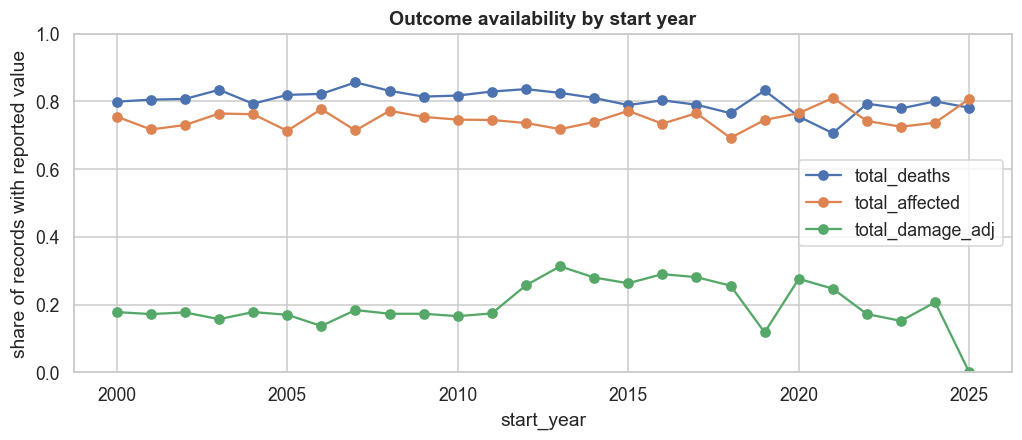

  saved F01_outcome_availability_by_year.png


In [6]:
# ---------- (1) annual sums with min_count=1 and observed counts ----------
yearly = df.groupby('start_year').agg(
    n_records=('dis_no', 'size'), n_events=('event_id', 'nunique'),
    n_deaths_obs=('total_deaths', 'count'), deaths_sum=('total_deaths', lambda s: s.sum(min_count=1)),
    n_affected_obs=('total_affected', 'count'), affected_sum=('total_affected', lambda s: s.sum(min_count=1)),
    n_damage_obs=('total_damage_adj', 'count'), damage_adj_sum_kUSD=('total_damage_adj', lambda s: s.sum(min_count=1)))
display(yearly.tail(6)); save_table(yearly, 'T01_yearly_summary_observed_counts.csv')
print('Years where an annual total is undefined (no observed values):',
      {c: yearly.index[yearly[c].isna()].tolist() for c in ['deaths_sum', 'affected_sum', 'damage_adj_sum_kUSD']})

# ---------- (4) outcome availability by year, region and hazard type ----------
OUT = ['total_deaths', 'total_affected', 'total_damage_adj']
av_year = df.groupby('start_year')[OUT].agg(lambda s: s.notna().mean()).round(3)
av_reg  = df.groupby('region')[OUT].agg(lambda s: s.notna().mean()).round(3).assign(n=df.groupby('region').size())
av_type = df.groupby('disaster_type')[OUT].agg(lambda s: s.notna().mean()).round(3).assign(n=df.groupby('disaster_type').size()).sort_values('n', ascending=False)
display(av_reg); display(av_type.head(12))
save_table(av_year, 'T02_outcome_availability_by_year.csv'); save_table(av_reg, 'T03_outcome_availability_by_region.csv')
save_table(av_type, 'T04_outcome_availability_by_type.csv')
fig, ax = plt.subplots(figsize=(11, 4)); av_year.plot(ax=ax, marker='o'); ax.set_ylim(0, 1)
ax.set_ylabel('share of records with reported value'); ax.set_title('Outcome availability by start year', fontweight='bold'); savefig(fig, 'outcome_availability_by_year')

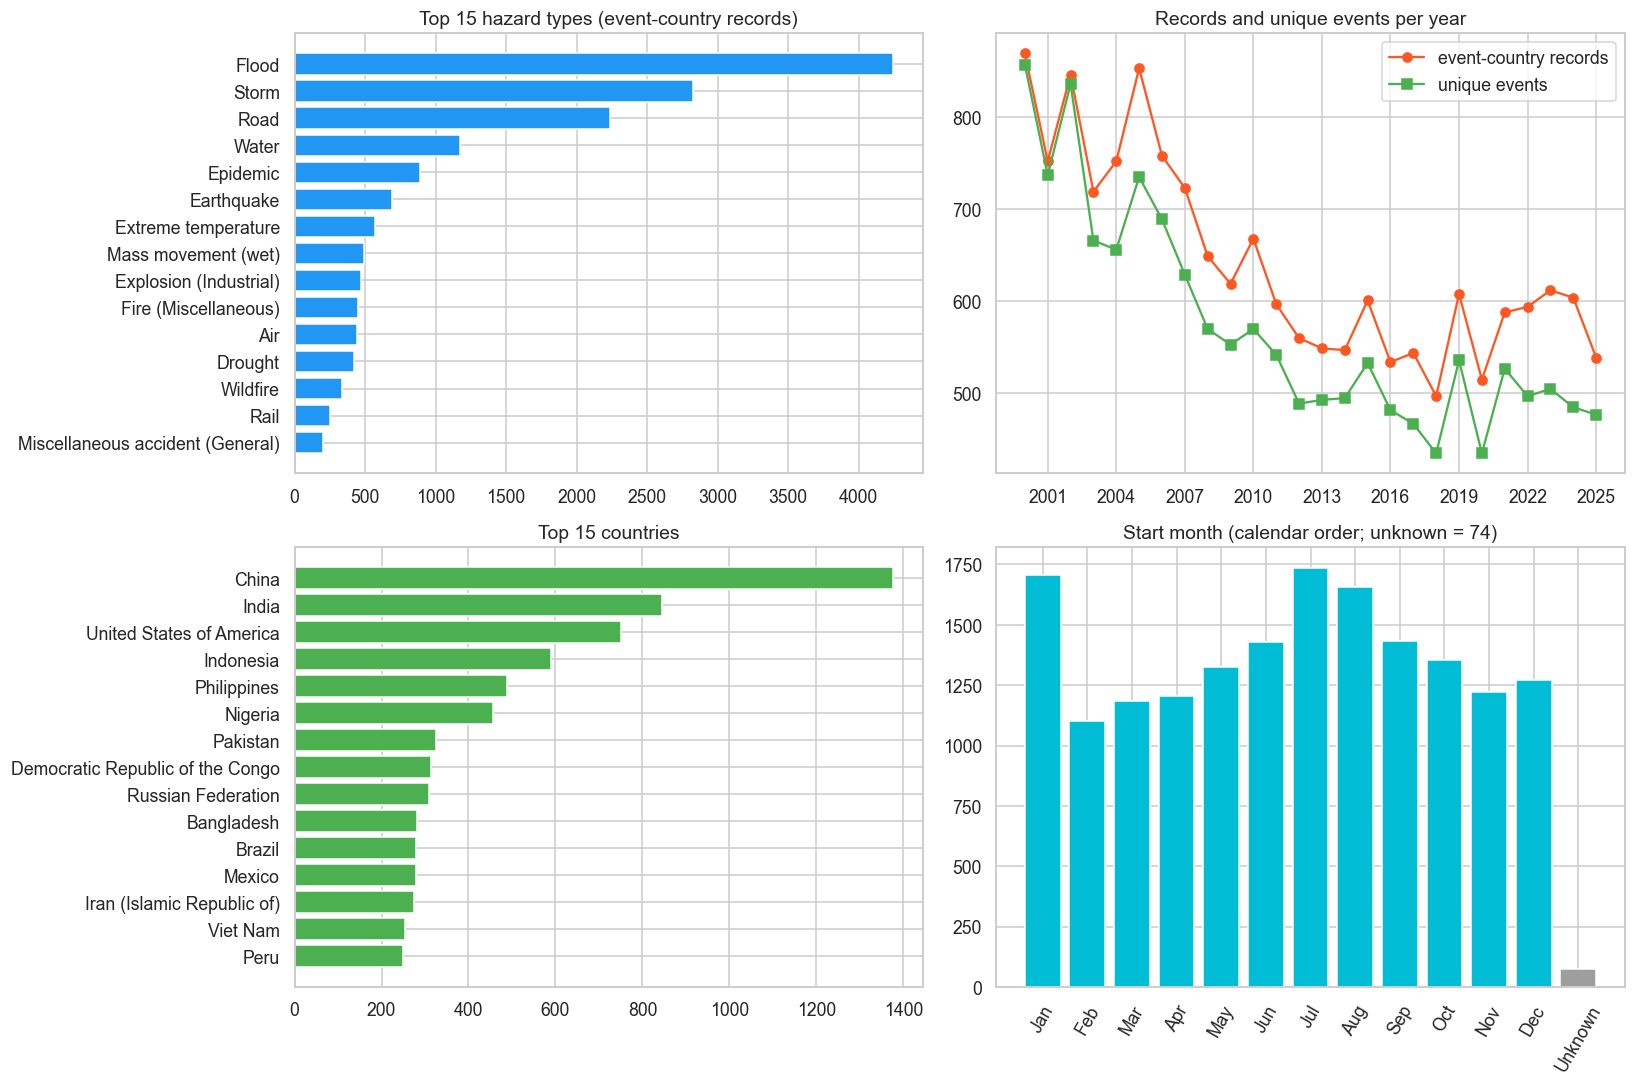

  saved F02_eda_overview.png


In [7]:
PAL = ['#2196F3','#FF5722','#4CAF50','#FFC107','#9C27B0','#00BCD4','#E91E63','#8BC34A','#FF9800','#607D8B']
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
top = df.disaster_type.value_counts().head(15); axes[0,0].barh(top.index[::-1], top.values[::-1], color=PAL[0]); axes[0,0].set_title('Top 15 hazard types (event-country records)')
ev_y = df.groupby('start_year').event_id.nunique(); rc_y = df.groupby('start_year').size()
axes[0,1].plot(rc_y.index, rc_y.values, 'o-', color=PAL[1], label='event-country records'); axes[0,1].plot(ev_y.index, ev_y.values, 's-', color=PAL[2], label='unique events')
axes[0,1].legend(); axes[0,1].set_title('Records and unique events per year'); axes[0,1].xaxis.set_major_locator(mticker.MultipleLocator(3))
t20 = df.country.value_counts().head(15); axes[1,0].barh(t20.index[::-1], t20.values[::-1], color=PAL[2]); axes[1,0].set_title('Top 15 countries')
# ---- (5) calendar-ordered months + explicit unknown ----
mo = df.start_month.value_counts().reindex(range(1, 13), fill_value=0); unk = int(df.start_month.isna().sum())
labels = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec','Unknown']
axes[1,1].bar(labels, list(mo.values) + [unk], color=[PAL[5]]*12 + ['#9E9E9E']); axes[1,1].tick_params(axis='x', rotation=60)
axes[1,1].set_title(f'Start month (calendar order; unknown = {unk})')
fig.tight_layout(); savefig(fig, 'eda_overview')

## 5 · Evaluation protocol, event purging and feature guards

* **Chronology.** Reference period (severity calibration only) 2000–2007 → development window → **holdout from 2018**. The last eligible year is 2024 for S3 and adjusted damage and 2025 for the other tasks. Inside the development window: expanding-window, year-block validation.
* **Event purging.** `purge()` removes from a *training* partition every record whose `event_id` also occurs in the evaluation partition. Applied to each CV block, the holdout, the calibration reference set and the stacker's meta-training rows. Every removal is logged and exported.
* **Allowlists + dependency checks.** A feature is accepted only if it is on the task's allowlist **and** none of its source columns (via `DERIVED_FROM`) is a source of the target.

In [8]:
EXCLUSIONS = []        # (task, stage, dis_no, reason)
def log_excl(task, stage, dis_nos, reason):
    EXCLUSIONS.extend((task, stage, d, reason) for d in dis_nos)

def purge(train_pos, eval_pos, eids, dis_no, task, stage, reason):
    # drop training positions whose event_id is present in the evaluation partition
    shared = np.isin(eids[train_pos], eids[eval_pos])
    log_excl(task, stage, dis_no[train_pos[shared]], reason)
    return train_pos[~shared]

# ---------------- dependency (derived-from) map ----------------
DERIVED_FROM = {
    'log_deaths': {'total_deaths'}, 'log_affected': {'total_affected', 'no_injured', 'no_affected', 'no_homeless'},
    'log_damage': {'total_damage_adj', 'total_damage'}, 'log_no_injured': {'no_injured'}, 'log_no_affected': {'no_affected'},
    'log_no_homeless': {'no_homeless'}, 'log_total_damage': {'total_damage', 'total_damage_adj'},
    'type_x_region': {'disaster_type', 'region'}, 'month_sin': {'start_month'}, 'month_cos': {'start_month'},
    'has_ofda_response': {'ofda_response'}, 'has_appeal': {'appeal'}, 'has_declaration': {'declaration'},
    'duration_days_exact': {'start_year', 'start_month', 'start_day', 'end_year', 'end_month', 'end_day'},
}
HISTORY_PREFIXES = ('hcA_', 'hsA_', 'hc_', 'hct_', 'ht_', 'hst_')
TARGET_SOURCES = {
    'A':   {'disaster_type'},
    'S2':  {'total_deaths', 'total_affected', 'no_injured', 'no_affected', 'no_homeless'},
    'S3':  {'total_deaths', 'total_affected', 'no_injured', 'no_affected', 'no_homeless', 'total_damage_adj', 'total_damage'},
    'C_log_deaths':   {'total_deaths'},
    'C_log_affected': {'total_affected', 'no_injured', 'no_affected', 'no_homeless'},
    'C_log_damage':   {'total_damage_adj', 'total_damage'},
}
def sources(f):
    return {'__HISTORY__'} if f.startswith(HISTORY_PREFIXES) else DERIVED_FROM.get(f, {f})

def guard(spec, task_key, allow, allow_history=False, label=''):
    feats = spec['num'] + spec['low'] + spec['high']
    assert len(feats) == len(set(feats)), 'duplicate feature names'
    not_allowed = set(feats) - set(allow)
    assert not not_allowed, f'GUARD[{label}] not on allowlist: {sorted(not_allowed)}'
    tgt = TARGET_SOURCES[task_key]
    clash = [f for f in feats if sources(f) & tgt]
    assert not clash, f'GUARD[{label}] feature depends on the target: {clash}'
    if not allow_history:
        h = [f for f in feats if f.startswith(HISTORY_PREFIXES)]
        assert not h, f'GUARD[{label}] outcome-based history not permitted in this feature set: {h}'
    print(f'  guard OK [{label}] {len(feats)} features')

def get_X(rows, spec, frame=None):
    frame = df if frame is None else frame
    cols = spec['num'] + spec['low'] + spec['high']
    X = frame.iloc[rows][cols].reset_index(drop=True)
    for c in spec['low'] + spec['high']: X[c] = X[c].astype(object)
    return X

## 6 · Cohorts, class eligibility and severity calibration

**Class eligibility (Task A)** uses development-period counts only. **Severity** is split into two separately defined tasks — **S2** (deaths + affected, both observed) and **S3** (deaths + affected + damage, all observed) — and is calibrated on the **2000–2007 reference records with all required components observed**. Reference records, and any record sharing an event ID with them, are excluded from classifier fitting and evaluation. Classifier fitting therefore starts in 2008.

In [9]:
# ---------------- (8) class eligibility from DEVELOPMENT data only ----------------
def class_eligibility(d):
    dev = d[d.start_year <= TRAIN_END]; first = dev[dev.start_year <= CV_FOLDS_ALL[0][0]]
    tab = pd.DataFrame({'n_development': dev.disaster_type.value_counts(), 'n_first_training_window': first.disaster_type.value_counts(),
                        'n_holdout': d[d.start_year >= TEST_START].disaster_type.value_counts()}).fillna(0).astype(int)
    tab['retained'] = ((tab.n_development >= MIN_DEV_CLASS) & (tab.n_first_training_window >= MIN_FIRST_WINDOW) & (tab.index != 'Unknown'))
    return tab.sort_values('n_development', ascending=False)
ELIG = class_eligibility(df)
CLASSES_A = sorted(ELIG.index[ELIG.retained])
N_CLASSES_A = len(CLASSES_A)
print(f'Task A: {N_CLASSES_A} retained hazard classes (rule: >= {MIN_DEV_CLASS} development records and >= {MIN_FIRST_WINDOW} in the first training window)')
display(ELIG); save_table(ELIG, 'T05_class_eligibility.csv')
log_excl('A', 'class_eligibility', df.dis_no[~df.disaster_type.isin(CLASSES_A)], 'class_not_eligible')

# ---------------- (4,5) severity calibration on an independent reference period ----------------
class SeverityCalibration:
    # min-max scaling + quartile thresholds fitted on reference records with ALL required components observed
    labels = ['Low', 'Moderate', 'High', 'Extreme']
    def __init__(self, comps): self.comps = list(comps)
    def fit(self, ref):
        r = ref[self.comps].dropna()
        self.n_ref_ = len(r)
        self.min_, self.max_ = r.min(), r.max()
        span = self.max_ - self.min_
        if len(r) == 0 or not np.isfinite(span).all() or not (span > 0).all():
            raise ValueError(f'Invalid reference range for {self.comps}')
        self.q_ = np.quantile(self.score(r), [.25, .5, .75])
        if not np.all(np.diff(self.q_) > 0):
            raise ValueError(f'Severity reference quartiles must be distinct for {self.comps}')
        return self
    def score(self, d):
        z = ((d[self.comps] - self.min_) / (self.max_ - self.min_)).clip(0, 1)
        return z.mean(axis=1, skipna=False).to_numpy()            # NaN unless ALL components observed
    def code(self, d):
        s = self.score(d); out = np.digitize(s, self.q_, right=True).astype(float); out[np.isnan(s)] = np.nan; return out
    def to_dict(self):
        return dict(components=self.comps, n_reference=int(self.n_ref_), reference_period=f'2000-{REF_END}',
                    min={k: float(v) for k, v in self.min_.items()}, max={k: float(v) for k, v in self.max_.items()},
                    quartile_thresholds=[float(x) for x in self.q_], class_order=self.labels)

SEV_SPECS = {'S2': ['log_deaths', 'log_affected'], 'S3': ['log_deaths', 'log_affected', 'log_damage']}
CAL, SEV_REF_EVENTS = {}, {}
for k, comps in SEV_SPECS.items():
    ref_mask = (df.start_year <= REF_END) & df[comps].notna().all(axis=1)
    CAL[k] = SeverityCalibration(comps).fit(df[ref_mask]); SEV_REF_EVENTS[k] = set(df.event_id[ref_mask])
    print(f'{k}: components {comps} | calibrated on {CAL[k].n_ref_} reference records (<= {REF_END}) | thresholds {np.round(CAL[k].q_, 3)}')
json.dump({k: c.to_dict() for k, c in CAL.items()}, open(os.path.join(DIRS['reproducibility'], 'severity_calibration.json'), 'w'), indent=2)

Task A: 21 retained hazard classes (rule: >= 50 development records and >= 10 in the first training window)


,n_development,n_first_training_window,n_holdout,retained
disaster_type,,,,
Flood,2899,1689,1345,True
Storm,1833,1023,996,True
Road,1815,1240,423,True
Water,873,528,301,True
Epidemic,760,559,133,True
Earthquake,492,284,201,True
Explosion (Industrial),412,326,58,True
Air,376,247,69,True
Extreme temperature,376,218,192,True


  saved T05_class_eligibility.csv
S2: components ['log_deaths', 'log_affected'] | calibrated on 3729 reference records (<= 2007) | thresholds [0.161 0.21  0.312]
S3: components ['log_deaths', 'log_affected', 'log_damage'] | calibrated on 737 reference records (<= 2007) | thresholds [0.32  0.392 0.495]


In [10]:
# ---------------- task registry ----------------
TASKS = {}
def register(key, kind, rows, y, class_names, train_start, folds_cfg, spec, allow, title):
    rows = np.asarray(rows)
    T = dict(key=key, kind=kind, rows=rows, y=np.asarray(y), years=df.start_year.values[rows], eids=df.event_id.values[rows],
             dis_no=df.dis_no.values[rows], class_names=class_names, train_start=train_start, folds_cfg=folds_cfg,
             spec=spec, allow=allow, title=title)
    T['X'] = get_X(rows, spec)
    assert (np.diff(T['years']) >= 0).all(), 'rows must be chronologically sorted'
    TASKS[key] = T; return T

# ---- feature specifications (PRIMARY = conservative event descriptors; no outcome history, magnitude, response, coordinates, year) ----
PRIM_A = dict(num=['month_sin', 'month_cos'], low=['region'], high=['subregion', 'country'])
PRIM_B = dict(num=['month_sin', 'month_cos'], low=['region', 'disaster_group', 'disaster_subgroup', 'disaster_type'],
              high=['country', 'subregion', 'disaster_subtype', 'type_x_region'])
ALLOW_PRIMARY_A = PRIM_A['num'] + PRIM_A['low'] + PRIM_A['high']
ALLOW_PRIMARY_B = PRIM_B['num'] + PRIM_B['low'] + PRIM_B['high']
guard(PRIM_A, 'A', ALLOW_PRIMARY_A, label='A primary')
for k in ['S2', 'S3', 'C_log_deaths', 'C_log_affected', 'C_log_damage']: guard(PRIM_B, k, ALLOW_PRIMARY_B, label=f'{k} primary')

# ---- Task A ----
rowsA = np.where(df.disaster_type.isin(CLASSES_A))[0]
leA = LabelEncoder().fit(CLASSES_A)
register('A', 'clf', rowsA, leA.transform(df.disaster_type.values[rowsA]), CLASSES_A, 2000, CV_FOLDS_ALL, PRIM_A, ALLOW_PRIMARY_A,
         f'Task A - hazard type ({N_CLASSES_A} classes)')

# ---- Tasks S2 / S3 (separate severity definitions, independent calibration) ----
for k in ['S2', 'S3']:
    comps = SEV_SPECS[k]; ok = df[comps].notna().all(axis=1) & (df.start_year > REF_END)
    sib = df.event_id.isin(SEV_REF_EVENTS[k]) & ok                       # shares an event with a calibration record
    log_excl(k, 'calibration_reference', df.dis_no[df.start_year <= REF_END], 'reference_period_(calibration_only)')
    log_excl(k, 'calibration_reference', df.dis_no[sib], 'shared_event_with_calibration_reference')
    rows = np.where(ok & ~sib)[0]
    y = CAL[k].code(df.iloc[rows]).astype(int)
    register(k, 'clf', rows, y, SeverityCalibration.labels, REF_END + 1, CV_FOLDS_SEV, PRIM_B, ALLOW_PRIMARY_B,
             f'Task {k} - severity from {" + ".join(c.replace("log_", "") for c in comps)}')
    print(f'{k}: {len(rows):,} records ({sib.sum()} removed: shared event with calibration set)')

# ---- Task C: regression on each observed log outcome ----
for t in LOGS:
    rows = np.where(df[t].notna())[0]
    register(f'C_{t}', 'reg', rows, df[t].values[rows], None, 2000, CV_FOLDS_ALL, PRIM_B, ALLOW_PRIMARY_B, f'Task C - {t}')

summ = pd.DataFrame([{'task': k, 'records': len(T['rows']), 'unique_events': len(set(T['eids'])),
                      'development': int((T['years'] <= TRAIN_END).sum()), 'holdout': int((T['years'] >= TEST_START).sum())} for k, T in TASKS.items()])
display(summ); save_table(summ, 'T06_task_cohorts.csv', idx=False)

  guard OK [A primary] 5 features
  guard OK [S2 primary] 10 features
  guard OK [S3 primary] 10 features
  guard OK [C_log_deaths primary] 10 features
  guard OK [C_log_affected primary] 10 features
  guard OK [C_log_damage primary] 10 features
S2: 6,062 records (0 removed: shared event with calibration set)
S3: 1,503 records (0 removed: shared event with calibration set)


,task,records,unique_events,development,holdout
0,A,16557,14756,12031,4526
1,S2,6062,5665,3480,2582
2,S3,1503,1408,965,538
3,C_log_deaths,13442,12344,9900,3542
4,C_log_affected,12473,11562,9041,3432
5,C_log_damage,3238,2881,2432,806


  saved T06_task_cohorts.csv


In [11]:
# ---------- (4) composition of the analysis cohorts vs all records ----------
def share(s, top): return s.value_counts(normalize=True).reindex(top).fillna(0)
TOP = df.disaster_type.value_counts().head(8).index
comp_tab = pd.DataFrame({'All records': share(df.disaster_type, TOP)} | {k: share(df.disaster_type.iloc[T['rows']], TOP) for k, T in TASKS.items() if k in ('A', 'S2', 'S3', 'C_log_deaths', 'C_log_damage')}).round(3)
reg_tab = pd.DataFrame({'All records': df.region.value_counts(normalize=True)} | {k: df.region.iloc[T['rows']].value_counts(normalize=True) for k, T in TASKS.items() if k in ('S2', 'S3', 'C_log_damage')}).round(3)
yr_tab = pd.DataFrame({'All records': pd.cut(df.start_year, [1999, 2007, 2017, 2025]).value_counts(normalize=True).sort_index()} |
                      {k: pd.cut(df.start_year.iloc[T['rows']], [1999, 2007, 2017, 2025]).value_counts(normalize=True).sort_index() for k, T in TASKS.items() if k in ('S2', 'S3', 'C_log_damage')}).round(3)
display(comp_tab); display(reg_tab); display(yr_tab)
for nm, t in [('T07_cohort_hazard_composition.csv', comp_tab), ('T08_cohort_region_composition.csv', reg_tab), ('T09_cohort_period_composition.csv', yr_tab)]: save_table(t, nm)
print('Interpretation: the S3 and damage-regression cohorts are small and differ in hazard/region/period composition from the full record set; '
      'conclusions from them describe records with reported damage, not all events.')

,All records,A,S2,S3,C_log_deaths,C_log_damage
disaster_type,,,,,,
Flood,0.254,0.256,0.312,0.420,0.231,0.367
Storm,0.169,0.171,0.186,0.399,0.157,0.416
Road,0.134,0.135,0.140,0.000,0.166,0.000
Water,0.070,0.071,0.057,0.000,0.087,0.000
Epidemic,0.053,0.054,0.057,0.000,0.058,0.000
Earthquake,0.042,0.042,0.048,0.099,0.034,0.092
Extreme temperature,0.034,0.034,0.013,0.004,0.035,0.014
Mass movement (wet),0.030,0.030,0.036,0.021,0.036,0.016


,All records,S2,S3,C_log_damage
region,,,,
Africa,0.257,0.255,0.071,0.061
Americas,0.199,0.212,0.267,0.301
Asia,0.404,0.437,0.526,0.459
Europe,0.116,0.079,0.090,0.127
Oceania,0.025,0.018,0.047,0.053


,All records,S2,S3,C_log_damage
start_year,,,,
"(1999, 2007]",0.376,0.000,0.000,0.328
"(2007, 2017]",0.351,0.574,0.642,0.423
"(2017, 2025]",0.273,0.426,0.358,0.249


  saved T07_cohort_hazard_composition.csv
  saved T08_cohort_region_composition.csv
  saved T09_cohort_period_composition.csv
Interpretation: the S3 and damage-regression cohorts are small and differ in hazard/region/period composition from the full record set; conclusions from them describe records with reported damage, not all events.


## 7. Historical predictors and regression checks

History is an explicitly retrospective sensitivity feature. Within each fit set, it uses records from strictly earlier start years and excludes the same disaster event. Evaluation histories are frozen from eligible training records. A group-year with no observations contributes zero to the cumulative sum and count. A mean is missing when its accumulated nonmissing count is zero.

In [12]:
# ============================================================
# HISTORICAL FEATURE CONSTRUCTION
# Corrected grouping, event exclusion and temporal safeguards
# ============================================================

# ------------------------------------------------------------
# 1. Helper: safely encode grouping keys
# ------------------------------------------------------------

def _history_group_codes(frame, key_cols):

    if not key_cols:
        raise ValueError("At least one historical grouping key is required.")

    codes_by_col = []

    for col in key_cols:

        codes, uniques = pd.factorize(
            frame[col].reset_index(drop=True),
            sort=False
        )

        # Treat missing key values as one identifiable category
        missing = codes == -1

        if missing.any():
            codes[missing] = len(uniques)

        codes_by_col.append(codes.astype(np.int64))

    if len(codes_by_col) == 1:
        return codes_by_col[0]

    # MultiIndex is a supported pandas Index input.
    # This avoids passing a Python list of tuples to factorize().
    key_index = pd.MultiIndex.from_arrays(codes_by_col)

    group_codes, _ = pd.factorize(
        key_index,
        sort=False
    )

    return group_codes.astype(np.int64)


# ------------------------------------------------------------
# 2. Helper: safely encode disaster events
# ------------------------------------------------------------

def _history_event_codes(values):

    values = pd.Series(values).reset_index(drop=True)

    codes, uniques = pd.factorize(
        values,
        sort=False
    )

    # Missing event IDs are treated as separate records.
    # They are never assumed to belong to the same disaster.
    missing = codes == -1

    if missing.any():

        codes[missing] = np.arange(
            len(uniques),
            len(uniques) + missing.sum()
        )

    return codes.astype(np.int64)


# ------------------------------------------------------------
# 3. Helper: calculate cumulative historical statistics
# ------------------------------------------------------------

def _history_cumulative(work, group_cols, value_cols):

    group_cols = list(group_cols)

    g = work.groupby(
        group_cols + ['start_year'],
        sort=True,
        dropna=False
    )

    parts = [
        g.size().rename('n__')
    ]

    for v in value_cols:

        parts.append(
            g[v].sum(min_count=0).rename(f'{v}__sum')
        )

        parts.append(
            g[v].count().rename(f'{v}__cnt')
        )

    agg = pd.concat(
        parts,
        axis=1
    ).reset_index()

    stat_cols = [
        c for c in agg.columns
        if c == 'n__'
        or c.endswith('__sum')
        or c.endswith('__cnt')
    ]

    agg = agg.sort_values(
        'start_year',
        kind='stable'
    )

    agg[stat_cols] = (
        agg.groupby(
            group_cols,
            sort=False,
            dropna=False
        )[stat_cols].cumsum()
    )

    return agg


# ------------------------------------------------------------
# 4. Helper: calculate historical means from cumulative totals
# ------------------------------------------------------------

def _history_output(total_hist, event_hist, index, value_cols, prefix):

    total_n = (
        total_hist['n__']
        .fillna(0)
        .to_numpy()
    )

    event_n = (
        event_hist['n__']
        .fillna(0)
        .to_numpy()
    )

    eligible_n = np.maximum(
        total_n - event_n,
        0
    )

    out = pd.DataFrame(index=index)

    out[f'{prefix}_n'] = eligible_n.astype(int)

    for v in value_cols:

        total_cnt = (
            total_hist[f'{v}__cnt']
            .fillna(0)
            .to_numpy()
        )

        event_cnt = (
            event_hist[f'{v}__cnt']
            .fillna(0)
            .to_numpy()
        )

        total_sum = (
            total_hist[f'{v}__sum']
            .fillna(0)
            .to_numpy()
        )

        event_sum = (
            event_hist[f'{v}__sum']
            .fillna(0)
            .to_numpy()
        )

        eligible_cnt = np.maximum(
            total_cnt - event_cnt,
            0
        )

        eligible_sum = total_sum - event_sum

        out[f'{prefix}_{v}'] = np.divide(
            eligible_sum,
            eligible_cnt,
            out=np.full(len(index), np.nan, dtype=float),
            where=eligible_cnt > 0
        )

    return out


# ------------------------------------------------------------
# 5. Historical features within a fitting dataset
# ------------------------------------------------------------

def add_history(d, key_cols, value_cols, prefix, event_col='event_id'):

    required = (
        list(key_cols)
        + ['start_year', event_col]
        + list(value_cols)
    )

    missing = [
        c for c in required
        if c not in d.columns
    ]

    if missing:
        raise ValueError(
            f"Historical feature construction missing columns: {missing}"
        )

    if d['start_year'].isna().any():
        raise ValueError(
            "Missing start_year values in historical feature calculation."
        )

    if len(d) == 0:

        out = pd.DataFrame(index=d.index)

        out[f'{prefix}_n'] = pd.Series(
            dtype=int,
            index=d.index
        )

        for v in value_cols:
            out[f'{prefix}_{v}'] = pd.Series(
                dtype=float,
                index=d.index
            )

        return out

    # Create stable integer grouping identifiers
    key_codes = _history_group_codes(
        d,
        key_cols
    )

    event_codes = _history_event_codes(
        d[event_col]
    )

    work = d[
        ['start_year'] + list(value_cols)
    ].copy()

    work['_key'] = key_codes
    work['_event'] = event_codes

    # All earlier records for each grouping key
    total_agg = _history_cumulative(
        work,
        ['_key'],
        value_cols
    )

    # Earlier records belonging to the same event
    event_agg = _history_cumulative(
        work,
        ['_key', '_event'],
        value_cols
    )

    # Prepare current records
    query = pd.DataFrame({

        'start_year': d['start_year'].to_numpy(),

        '_key': key_codes,

        '_event': event_codes,

        '_i': np.arange(len(d))

    })

    query = query.sort_values(
        'start_year',
        kind='stable'
    )

    # Retrieve strictly earlier records
    total_hist = pd.merge_asof(

        query,

        total_agg.sort_values(
            'start_year',
            kind='stable'
        ),

        on='start_year',

        by='_key',

        allow_exact_matches=False,

        direction='backward'

    ).sort_values('_i')

    same_event_hist = pd.merge_asof(

        query,

        event_agg.sort_values(
            'start_year',
            kind='stable'
        ),

        on='start_year',

        by=['_key', '_event'],

        allow_exact_matches=False,

        direction='backward'

    ).sort_values('_i')

    return _history_output(
        total_hist,
        same_event_hist,
        d.index,
        value_cols,
        prefix
    )


# ------------------------------------------------------------
# 6. Frozen training history applied to new records
# ------------------------------------------------------------

def frozen_history(
    dfit,
    dapp,
    key_cols,
    value_cols,
    prefix,
    event_col='event_id'
):

    required = (
        list(key_cols)
        + ['start_year', event_col]
        + list(value_cols)
    )

    for name, frame in [
        ('dfit', dfit),
        ('dapp', dapp)
    ]:

        missing = [
            c for c in required
            if c not in frame.columns
        ]

        if missing:
            raise ValueError(
                f"{name} missing historical columns: {missing}"
            )

        if frame['start_year'].isna().any():
            raise ValueError(
                f"{name} contains missing start_year values."
            )

    # Empty application partition
    if len(dapp) == 0:

        out = pd.DataFrame(index=dapp.index)

        out[f'{prefix}_n'] = pd.Series(
            dtype=int,
            index=dapp.index
        )

        for v in value_cols:
            out[f'{prefix}_{v}'] = pd.Series(
                dtype=float,
                index=dapp.index
            )

        return out

    # No available training history
    if len(dfit) == 0:

        out = pd.DataFrame(index=dapp.index)

        out[f'{prefix}_n'] = 0

        for v in value_cols:
            out[f'{prefix}_{v}'] = np.nan

        return out

    # Combine keys only for consistent code assignment.
    # IMPORTANT: use MultiIndex-based encoding, not list-of-tuples factorization.
    combined_keys = pd.concat(

        [
            dfit[key_cols],
            dapp[key_cols]
        ],

        ignore_index=True

    )

    all_key_codes = _history_group_codes(
        combined_keys,
        key_cols
    )

    fit_key = all_key_codes[:len(dfit)]
    app_key = all_key_codes[len(dfit):]

    # Encode event identifiers across both partitions.
    # Missing event IDs remain unique to individual records.
    combined_events = pd.concat(

        [
            dfit[event_col],
            dapp[event_col]
        ],

        ignore_index=True

    )

    all_event_codes = _history_event_codes(
        combined_events
    )

    fit_event = all_event_codes[:len(dfit)]
    app_event = all_event_codes[len(dfit):]

    # Training records are the only historical source.
    work = dfit[
        ['start_year'] + list(value_cols)
    ].copy()

    work['_key'] = fit_key
    work['_event'] = fit_event

    # Cumulative training statistics
    total_agg = _history_cumulative(
        work,
        ['_key'],
        value_cols
    )

    # Cumulative statistics from the same event
    event_agg = _history_cumulative(
        work,
        ['_key', '_event'],
        value_cols
    )

    # Application queries
    query = pd.DataFrame({

        'start_year': dapp['start_year'].to_numpy(),

        '_key': app_key,

        '_event': app_event,

        '_i': np.arange(len(dapp))

    })

    query = query.sort_values(
        'start_year',
        kind='stable'
    )

    # Only strictly earlier training years are eligible
    total_hist = pd.merge_asof(

        query,

        total_agg.sort_values(
            'start_year',
            kind='stable'
        ),

        on='start_year',

        by='_key',

        allow_exact_matches=False,

        direction='backward'

    ).sort_values('_i')

    # Remove earlier records belonging to the same disaster event
    same_event_hist = pd.merge_asof(

        query,

        event_agg.sort_values(
            'start_year',
            kind='stable'
        ),

        on='start_year',

        by=['_key', '_event'],

        allow_exact_matches=False,

        direction='backward'

    ).sort_values('_i')

    return _history_output(
        total_hist,
        same_event_hist,
        dapp.index,
        value_cols,
        prefix
    )


# ------------------------------------------------------------
# 7. Task A historical hazard indicators
# ------------------------------------------------------------

TOP_TYPES = (

    df.loc[
        df.start_year <= TRAIN_END,
        'disaster_type'
    ]

    .value_counts()

    .head(8)

    .index.tolist()

)

IND_COLS = []

for i, t in enumerate(TOP_TYPES):

    col = f'is_t{i}'

    df[col] = (
        df.disaster_type == t
    ).astype(float)

    IND_COLS.append(col)


# ------------------------------------------------------------
# 8. Unified historical feature construction
# ------------------------------------------------------------

def hist_frames(d, fit_rows, app_rows, kind):

    fit_rows = np.asarray(
        fit_rows,
        dtype=int
    )

    app_rows = np.asarray(
        app_rows,
        dtype=int
    )

    if fit_rows.ndim != 1 or app_rows.ndim != 1:
        raise ValueError(
            "Training and application rows must be one-dimensional."
        )

    if len(np.unique(fit_rows)) != len(fit_rows):
        raise ValueError(
            "Duplicate training row positions detected."
        )

    if len(np.unique(app_rows)) != len(app_rows):
        raise ValueError(
            "Duplicate application row positions detected."
        )

    if np.intersect1d(fit_rows, app_rows).size:
        raise ValueError(
            "Training and application row positions overlap."
        )

    if (
        np.any(fit_rows < 0)
        or np.any(app_rows < 0)
        or np.any(fit_rows >= len(d))
        or np.any(app_rows >= len(d))
    ):

        raise IndexError(
            "Invalid row positions supplied to hist_frames."
        )

    if kind not in ('A', 'B'):
        raise ValueError(
            "kind must be 'A' or 'B'."
        )

    dfit = d.iloc[fit_rows].copy()
    dapp = d.iloc[app_rows].copy()

    # Define task-specific historical features
    if kind == 'A':

        specs = [

            (['country'], IND_COLS, 'hcA'),

            (['subregion'], IND_COLS, 'hsA')

        ]

    else:

        specs = [

            (['country'], LOGS, 'hc'),

            (
                ['country', 'disaster_type'],
                LOGS,
                'hct'
            ),

            (['disaster_type'], LOGS, 'ht'),

            (
                ['subregion', 'disaster_type'],
                LOGS,
                'hst'
            )

        ]

    # Verify feature availability
    for keys, values, prefix in specs:

        required = (
            keys
            + ['start_year', 'event_id']
            + list(values)
        )

        for frame_name, frame in [
            ('training', dfit),
            ('application', dapp)
        ]:

            missing = [
                c for c in required
                if c not in frame.columns
            ]

            if missing:
                raise ValueError(
                    f"{frame_name} data missing columns: {missing}"
                )

    # Training historical features
    Hf = pd.concat(

        [
            add_history(
                dfit,
                keys,
                values,
                prefix
            )

            for keys, values, prefix in specs
        ],

        axis=1

    )

    # Application historical features:
    # training source only, strictly earlier years,
    # same disaster event excluded.
    Ha = pd.concat(

        [
            frozen_history(
                dfit,
                dapp,
                keys,
                values,
                prefix
            )

            for keys, values, prefix in specs
        ],

        axis=1

    )

    if len(Hf) != len(dfit) or len(Ha) != len(dapp):
        raise AssertionError(
            "Historical feature row count mismatch."
        )

    if not Hf.index.equals(dfit.index):
        raise AssertionError(
            "Training historical feature row alignment failed."
        )

    if not Ha.index.equals(dapp.index):
        raise AssertionError(
            "Application historical feature row alignment failed."
        )

    if list(Hf.columns) != list(Ha.columns):
        raise AssertionError(
            "Training and application historical columns differ."
        )

    if Hf.columns.duplicated().any():
        raise AssertionError(
            "Duplicate historical feature names detected."
        )

    return Hf, Ha


print("Historical feature functions successfully defined.")
print("Grouping keys use safe pandas index-based encoding.")
print("Missing event IDs are treated as separate records.")
print("Historical features exclude same-event records.")
print("Application history uses training records only.")

# This example has an entirely unreported year after valid observations.
# The expected history in 2002 retains both valid 2000 observations.
history_fixture = pd.DataFrame({
    'country': ['Example'] * 5,
    'start_year': [2000, 2000, 2001, 2002, 2003],
    'event_id': ['a', 'b', 'c', 'a', 'd'],
    'outcome': [2.0, 4.0, np.nan, 100.0, 400.0],
})
fit_history = add_history(history_fixture, ['country'], ['outcome'], 'probe')
# Same-year observations are skipped. A missing year does not reset the sum.
np.testing.assert_allclose(fit_history['probe_outcome'], [np.nan, np.nan, 3.0, 4.0, 106 / 3],
                           equal_nan=True)
np.testing.assert_array_equal(fit_history['probe_n'], [0, 0, 2, 2, 4])

apply_fixture = pd.DataFrame({
    'country': ['Example', 'Example', 'Example', 'Other'],
    'start_year': [2002, 2002, 2000, 2004],
    'event_id': ['new', 'a', 'new2', 'new3'],
    'outcome': [1e9, 1e9, 1e9, 1e9],
})
held_history = frozen_history(history_fixture, apply_fixture, ['country'], ['outcome'], 'probe')
np.testing.assert_allclose(held_history['probe_outcome'], [3.0, 4.0, np.nan, np.nan], equal_nan=True)
np.testing.assert_array_equal(held_history['probe_n'], [3, 2, 0, 0])
perturbed_application = apply_fixture.assign(outcome=-1e9)
pd.testing.assert_frame_equal(
    held_history,
    frozen_history(history_fixture, perturbed_application, ['country'], ['outcome'], 'probe'),
)

unreported = history_fixture.assign(outcome=np.nan)
nan_history = frozen_history(unreported, apply_fixture, ['country'], ['outcome'], 'probe')
assert nan_history['probe_outcome'].isna().all()
np.testing.assert_array_equal(nan_history['probe_n'], [3, 2, 0, 0])
print('History checks passed: missing year, missing outcomes, strict chronology, same event and application outcome isolation.')

Historical feature functions successfully defined.

Grouping keys use safe pandas index-based encoding.
Missing event IDs are treated as separate records.
Historical features exclude same-event records.
Application history uses training records only.


History checks passed: missing year, missing outcomes, strict chronology, same event and application outcome isolation.


## 8. Modelling and chronological selection

Each training partition fits numeric median imputation, missing indicators, standardization and categorical one-hot encoding. Infrequent categories are grouped, with a category cap for high-cardinality fields. Randomized search tunes LightGBM on chronological development blocks. The main comparison also includes untuned models, averaging and stacking. The meta-learner receives out-of-fold predictions and block-specific fits use predictions from earlier blocks. Scores from development guide selection and can be optimistic because they also guide tuning and ensemble membership.

The full tuning CSVs retain all 30 candidates and are verified against the original top-ranked exports.


In [13]:
# ============================================================
# CELL: MODELLING INFRASTRUCTURE
# Leakage-safe preprocessing, model libraries, metrics,
# ensemble objects, chronological CV and hyperparameter tuning
# ============================================================

# ------------------------------------------------------------
# 1. PREPROCESSING PIPELINE
# ------------------------------------------------------------

def make_prep(spec, target_type='auto'):

    """
    Leakage-safe preprocessing.

    Numeric:
        Median imputation + missingness indicators + scaling.

    Low-cardinality categorical:
        Constant imputation + one-hot encoding.

    High-cardinality categorical:
        Constant imputation + infrequent-category grouping
        + capped one-hot encoding.

    Target encoding is deliberately excluded because
    random internal target encoding can violate temporal
    ordering within chronological development data.

    target_type is retained for compatibility with existing
    calls, but is not used.
    """

    tf = []

    num_cols = list(spec.get('num', []))
    low_cols = list(spec.get('low', []))
    high_cols = list(spec.get('high', []))

    all_cols = num_cols + low_cols + high_cols

    if not all_cols:
        raise ValueError("No predictor columns supplied.")

    if len(all_cols) != len(set(all_cols)):
        raise ValueError(
            "Duplicate columns found across preprocessing groups."
        )

    # --------------------------------------------------------
    # Numeric features
    # --------------------------------------------------------

    if num_cols:

        numeric_pipeline = Pipeline([

            (
                'imp',
                SimpleImputer(
                    strategy='median',
                    add_indicator=True,
                    keep_empty_features=True
                )
            ),

            (
                'sc',
                StandardScaler()
            )

        ])

        tf.append(
            ('num', numeric_pipeline, num_cols)
        )

    # --------------------------------------------------------
    # Low-cardinality categorical features
    # --------------------------------------------------------

    if low_cols:

        low_pipeline = Pipeline([

            (
                'imp',
                SimpleImputer(
                    strategy='constant',
                    fill_value='Unknown',
                    keep_empty_features=True
                )
            ),

            (
                'enc',
                OneHotEncoder(
                    handle_unknown='infrequent_if_exist',
                    min_frequency=15,
                    sparse_output=False,
                    dtype=np.float32
                )
            )

        ])

        tf.append(
            ('ohe', low_pipeline, low_cols)
        )

    # --------------------------------------------------------
    # High-cardinality categorical features
    # --------------------------------------------------------

    if high_cols:

        high_pipeline = Pipeline([

            (
                'imp',
                SimpleImputer(
                    strategy='constant',
                    fill_value='Unknown',
                    keep_empty_features=True
                )
            ),

            (
                'enc',
                OneHotEncoder(
                    handle_unknown='infrequent_if_exist',
                    min_frequency=15,
                    max_categories=50,
                    sparse_output=False,
                    dtype=np.float32
                )
            )

        ])

        tf.append(
            ('high_ohe', high_pipeline, high_cols)
        )

    # --------------------------------------------------------
    # Assemble preprocessing
    # --------------------------------------------------------

    prep = ColumnTransformer(
        transformers=tf,
        remainder='drop',
        sparse_threshold=0.0,
        verbose_feature_names_out=True
    )

    return prep


# ------------------------------------------------------------
# 2. CLASSIFICATION MODEL LIBRARY
# ------------------------------------------------------------

def clf_zoo():

    return {

        'Logistic Regression': LogisticRegression(
            C=0.5,
            max_iter=500
        ),

        'Random Forest': RandomForestClassifier(
            n_estimators=P['rf_trees'],
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=SEED
        ),

        'XGBoost': XGBClassifier(
            n_estimators=P['n_est'],
            max_depth=5,
            learning_rate=0.08,
            subsample=0.85,
            colsample_bytree=0.8,
            min_child_weight=2,
            reg_lambda=1.5,
            tree_method='hist',
            n_jobs=-1,
            random_state=SEED,
            verbosity=0
        ),

        'LightGBM': LGBMClassifier(
            n_estimators=P['n_est'],
            learning_rate=0.06,
            num_leaves=31,
            min_child_samples=15,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            reg_lambda=1.0,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1
        ),

        'CatBoost': CatBoostClassifier(
            iterations=P['cat_iter'],
            depth=6,
            learning_rate=0.1,
            random_seed=SEED,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1
        )

    }


# ------------------------------------------------------------
# 3. REGRESSION MODEL LIBRARY
# ------------------------------------------------------------

def reg_zoo():

    return {

        'Ridge': Ridge(
            alpha=5.0
        ),

        'Random Forest': RandomForestRegressor(
            n_estimators=P['rf_trees'],
            min_samples_leaf=3,
            n_jobs=-1,
            random_state=SEED
        ),

        'XGBoost': XGBRegressor(
            n_estimators=P['n_est'],
            max_depth=5,
            learning_rate=0.06,
            subsample=0.85,
            colsample_bytree=0.8,
            min_child_weight=3,
            tree_method='hist',
            n_jobs=-1,
            random_state=SEED,
            verbosity=0
        ),

        'LightGBM': LGBMRegressor(
            n_estimators=P['n_est'],
            learning_rate=0.05,
            num_leaves=31,
            min_child_samples=15,
            subsample=0.8,
            subsample_freq=1,
            colsample_bytree=0.8,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1
        ),

        'CatBoost': CatBoostRegressor(
            iterations=P['cat_iter'],
            depth=6,
            learning_rate=0.08,
            random_seed=SEED,
            verbose=0,
            allow_writing_files=False,
            thread_count=-1
        )

    }


# ------------------------------------------------------------
# 4. LIGHTGBM HYPERPARAMETER SEARCH SPACE
# ------------------------------------------------------------

LGBM_DIST = {

    'clf__n_estimators': [100, 150, 250, 400],

    'clf__learning_rate': [0.02, 0.04, 0.06, 0.1],

    'clf__num_leaves': [7, 15, 31, 63],

    'clf__min_child_samples': [5, 10, 20, 40],

    'clf__subsample': [0.6, 0.8, 1.0],

    'clf__colsample_bytree': [0.5, 0.7, 0.9],

    'clf__reg_lambda': [0, 1, 5, 10]

}


# ------------------------------------------------------------
# 5. CLASSIFICATION METRICS
# Explicit class order: 0 to K-1
# ------------------------------------------------------------

def clf_fast(y, p, K):

    cm = np.bincount(
        y * K + p,
        minlength=K * K
    ).reshape(K, K)

    tp = np.diag(cm).astype(float)

    sup = cm.sum(1)

    prd = cm.sum(0)

    den = sup + prd

    f1 = np.divide(
        2 * tp,
        den,
        out=np.zeros(K),
        where=den > 0
    )

    rec = np.divide(
        tp,
        sup,
        out=np.zeros(K),
        where=sup > 0
    )

    return (
        tp.sum() / cm.sum(),
        f1.mean(),
        rec[sup > 0].mean()
    )


def cls_metrics(y, proba, K, ordinal=False):

    pr = proba.argmax(1)

    proba = np.clip(
        proba / proba.sum(1, keepdims=True),
        1e-7,
        1
    )

    proba = proba / proba.sum(1, keepdims=True)

    m = {

        'Accuracy': accuracy_score(y, pr),

        'Balanced Acc': balanced_accuracy_score(y, pr),

        'Macro F1': f1_score(
            y,
            pr,
            average='macro',
            labels=np.arange(K),
            zero_division=0
        ),

        'Log loss': log_loss(
            y,
            proba,
            labels=np.arange(K)
        )

    }

    if ordinal:
        m['Ordinal MAE'] = np.abs(pr - y).mean()

    return m


# ------------------------------------------------------------
# 6. REGRESSION METRICS
# ------------------------------------------------------------

def inv(z):

    return np.expm1(
        np.clip(z, 0, None)
    )


def reg_metrics(y, p):

    return {

        'RMSE': float(
            np.sqrt(mean_squared_error(y, p))
        ),

        'MAE': mean_absolute_error(y, p),

        'R2': r2_score(y, p)

    }


# ------------------------------------------------------------
# 7. EVENT-CLUSTERED BOOTSTRAP
# ------------------------------------------------------------

def boot_indices(eids_te, B, seed):

    codes, uniq = pd.factorize(eids_te)

    if np.any(codes < 0):
        raise ValueError(
            "Missing event IDs in bootstrap evaluation records."
        )

    nc = len(uniq)

    if nc == 0:
        raise ValueError(
            "No event clusters available for bootstrap."
        )

    order = np.argsort(
        codes,
        kind='stable'
    )

    counts = np.bincount(codes)

    starts = np.r_[
        0,
        np.cumsum(counts)[:-1]
    ]

    groups = [

        order[s:s + c]

        for s, c in zip(starts, counts)

    ]

    rng = np.random.default_rng(seed)

    return [

        np.concatenate(
            [groups[i] for i in rng.integers(0, nc, nc)]
        )

        for _ in range(B)

    ]


def ci_str(pt, vals):

    lo, hi = np.percentile(
        vals,
        [2.5, 97.5]
    )

    return f'{pt:.3f} [{lo:.3f}, {hi:.3f}]'


# ------------------------------------------------------------
# 8. VOTING ENSEMBLE
# ------------------------------------------------------------

class VotingEnsemble:

    def __init__(self, members, kind):

        self.members = members

        self.kind = kind

    def predict_proba(self, X):

        return np.mean(
            [
                m.predict_proba(X)
                for m in self.members.values()
            ],
            0
        )

    def predict(self, X):

        if self.kind == 'clf':

            return self.predict_proba(X).argmax(1)

        return np.mean(
            [
                m.predict(X)
                for m in self.members.values()
            ],
            0
        )


# ------------------------------------------------------------
# 9. STACKING ENSEMBLE
# ------------------------------------------------------------

class StackingEnsemble:

    def __init__(self, members, meta, kind, K=None):

        self.members = members

        self.meta = meta

        self.kind = kind

        self.K = K

    def _Z(self, X):

        if self.kind == 'clf':

            return np.hstack([

                np.log(
                    np.clip(
                        m.predict_proba(X),
                        1e-6,
                        1
                    )
                )

                for m in self.members.values()

            ])

        return np.column_stack([

            m.predict(X)

            for m in self.members.values()

        ])

    def predict_proba(self, X):

        out = np.full(
            (len(X), self.K),
            1e-9
        )

        out[:, self.meta.classes_] = (
            self.meta.predict_proba(
                self._Z(X)
            )
        )

        return out

    def predict(self, X):

        if self.kind == 'clf':

            return self.predict_proba(X).argmax(1)

        return self.meta.predict(
            self._Z(X)
        )


# ------------------------------------------------------------
# 10. CHRONOLOGICAL DEVELOPMENT BLOCKS
# ------------------------------------------------------------

def make_blocks(T, log=True):

    folds = []

    for b, (end, val) in enumerate(T['folds_cfg']):

        tr = np.where(

            (T['years'] >= T['train_start'])
            &
            (T['years'] <= end)

        )[0]

        va = np.where(
            np.isin(T['years'], val)
        )[0]

        if log:

            tr = purge(

                tr,

                va,

                T['eids'],

                T['dis_no'],

                T['key'],

                f'dev_block{b}',

                'shared_event_with_validation_block'

            )

        else:

            tr = tr[
                ~np.isin(
                    T['eids'][tr],
                    T['eids'][va]
                )
            ]

        if len(tr) == 0 or len(va) == 0:

            raise ValueError(
                f"Empty chronological fold detected: {b}"
            )

        folds.append(
            (tr, va)
        )

    return folds


# ------------------------------------------------------------
# 11. LIGHTGBM DEVELOPMENT-ONLY TUNING
# ------------------------------------------------------------

def tune_lgbm(T):

    """
    Hyperparameter tuning uses development data only.

    The final temporal holdout is never indexed.

    Chronological validation blocks are supplied explicitly.
    """

    kind = T['kind']

    n_dev = int(
        (T['years'] <= TRAIN_END).sum()
    )

    folds = make_blocks(
        T,
        log=False
    )

    est = (

        LGBMClassifier(
            subsample_freq=1,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1
        )

        if kind == 'clf'

        else

        LGBMRegressor(
            subsample_freq=1,
            random_state=SEED,
            verbose=-1,
            n_jobs=-1
        )

    )

    pipe = Pipeline([

        (
            'prep',
            make_prep(
                T['spec'],
                'multiclass' if kind == 'clf' else 'continuous'
            )
        ),

        ('clf', est)

    ])

    rs = RandomizedSearchCV(

        pipe,

        LGBM_DIST,

        n_iter=P['tune_iter'],

        cv=folds,

        random_state=SEED,

        n_jobs=1,

        refit=False,

        scoring=(
            'f1_macro'
            if kind == 'clf'
            else 'neg_root_mean_squared_error'
        )

    )

    rs.fit(
        T['X'].iloc[:n_dev],
        T['y'][:n_dev]
    )

    res = pd.DataFrame(
        rs.cv_results_
    ).sort_values(
        'rank_test_score'
    )

    save_table(

        res[
            [
                'rank_test_score',
                'mean_test_score',
                'std_test_score',
                'params'
            ]
        ],

        f'T_tuning_{T["key"]}.csv',

        idx=False

    )

    best = {

        k.replace('clf__', ''): v

        for k, v in rs.best_params_.items()

    }

    print(

        f'  tuned LightGBM [{T["key"]}] '

        f'development score {rs.best_score_:.4f} '

        f'(selection score, potentially optimistic) | {best}'

    )

    return best


# ------------------------------------------------------------
# 12. PREPROCESSING CONFIGURATION CHECK
# ------------------------------------------------------------

print("=" * 75)
print("MODELLING INFRASTRUCTURE INITIALISED")
print("=" * 75)

print("Classification models: 5")
print("Regression models: 5")

print("Numeric preprocessing: median imputation + scaling")
print("Categorical preprocessing: one-hot encoding")
print("High-cardinality cap: 50 categories per feature")

print("Target encoding: DISABLED")
print("Random target-based cross-validation: DISABLED")

print("Chronological validation: ENABLED")
print("Event-level purging: ENABLED")

print("Voting ensemble: AVAILABLE")
print("Stacking ensemble: AVAILABLE")

print("=" * 75)

MODELLING INFRASTRUCTURE INITIALISED
Classification models: 5
Regression models: 5
Numeric preprocessing: median imputation + scaling
Categorical preprocessing: one-hot encoding
High-cardinality cap: 50 categories per feature
Target encoding: DISABLED
Random target-based cross-validation: DISABLED
Chronological validation: ENABLED
Event-level purging: ENABLED
Voting ensemble: AVAILABLE
Stacking ensemble: AVAILABLE


In [14]:
def run_task(T, zoo, top_k=3, top_stack=4, meta_C=0.1):
    kind, key = T['kind'], T['key']; X, y, yrs, eids, dno = T['X'], T['y'], T['years'], T['eids'], T['dis_no']
    K = len(T['class_names']) if kind == 'clf' else None; ordinal = key in ('S2', 'S3')
    folds = make_blocks(T); nb = len(folds)
    val_idx = np.concatenate([v for _, v in folds]); block = np.concatenate([np.full(len(v), b) for b, (_, v) in enumerate(folds)]); ev = block >= 1
    te = np.where(yrs >= TEST_START)[0]
    tr0 = np.where((yrs >= T['train_start']) & (yrs <= TRAIN_END))[0]
    tr = purge(tr0, te, eids, dno, key, 'holdout', 'shared_event_with_holdout')
    if kind == 'clf':
        for b, (a, _) in enumerate(folds): assert len(np.unique(y[a])) == K, f'{key} block {b}: class missing from training window'
        assert len(np.unique(y[tr])) == K
    R = dict(key=key, kind=kind, K=K, tr=tr, te=te, val_idx=val_idx, block=block, ev=ev, oof={}, test={}, fitted={}, times={}, models={})
    for name, est in zoo.items():
        t0 = time.time(); pipe = Pipeline([('prep', make_prep(T['spec'], 'multiclass' if kind == 'clf' else 'continuous')), ('clf', est)])
        oof = np.zeros((len(val_idx), K)) if kind == 'clf' else np.zeros(len(val_idx)); pos = 0
        for a, v in folds:
            m = clone(pipe).fit(X.iloc[a], y[a]); oof[pos:pos + len(v)] = m.predict_proba(X.iloc[v]) if kind == 'clf' else m.predict(X.iloc[v]); pos += len(v)
        final = clone(pipe).fit(X.iloc[tr], y[tr])
        R['oof'][name] = oof; R['test'][name] = final.predict_proba(X.iloc[te]) if kind == 'clf' else final.predict(X.iloc[te])
        R['fitted'][name] = R['models'][name] = final; R['times'][name] = time.time() - t0
        print(f'  [{key}] {name:22s} {time.time()-t0:6.1f}s')
    yv = y[val_idx]
    # ---------- development ranking (blocks >= 1) ----------
    if kind == 'clf': score = {n: clf_fast(yv[ev], p[ev].argmax(1), K)[1] for n, p in R['oof'].items()}; ranked = sorted(score, key=score.get, reverse=True)
    else:             score = {n: np.sqrt(mean_squared_error(yv[ev], p[ev])) for n, p in R['oof'].items()}; ranked = sorted(score, key=score.get)
    vote, stack = ranked[:top_k], ranked[:top_stack]; R['vote_members'], R['stack_members'] = vote, stack
    Z = lambda D: (np.hstack([np.log(np.clip(D[n], 1e-6, 1)) for n in stack]) if kind == 'clf' else np.column_stack([D[n] for n in stack]))
    Zo, Zt = Z(R['oof']), Z(R['test'])
    def fit_meta(Ztr, ytr):
        return (Pipeline([('sc', StandardScaler()), ('lr', LogisticRegression(C=meta_C, max_iter=5000))]).fit(Ztr, ytr) if kind == 'clf' else LinearRegression(positive=True).fit(Ztr, ytr))
    def apply_meta(mm, Zap):
        if kind == 'reg': return mm.predict(Zap)
        out = np.full((len(Zap), K), 1e-9); out[:, mm.classes_] = mm.predict_proba(Zap); return out
    vn, sn = f'Soft Voting (top-{top_k})', 'Stacking (chronological meta-learner)'
    R['oof'][vn] = np.mean([R['oof'][n] for n in vote], 0); R['test'][vn] = np.mean([R['test'][n] for n in vote], 0)
    st_oof = np.full_like(R['oof'][ranked[0]], np.nan, dtype=float)
    for b in range(1, nb):                       # CHRONOLOGICAL: meta trained on OOF of blocks < b only, purged of events shared with block b
        mtr, mev = np.where(block < b)[0], np.where(block == b)[0]
        keep = ~np.isin(eids[val_idx[mtr]], eids[val_idx[mev]]); log_excl(key, f'stack_meta_block{b}', dno[val_idx[mtr[~keep]]], 'shared_event_with_stacking_evaluation_block')
        st_oof[mev] = apply_meta(fit_meta(Zo[mtr[keep]], yv[mtr[keep]]), Zo[mev])
    allm = np.arange(len(val_idx)); keep = ~np.isin(eids[val_idx], eids[te]); log_excl(key, 'stack_meta_final', dno[val_idx[~keep]], 'shared_event_with_holdout')
    meta = fit_meta(Zo[keep], yv[keep]); R['oof'][sn] = st_oof; R['test'][sn] = apply_meta(meta, Zt)
    R['models'][vn] = VotingEnsemble({n: R['fitted'][n] for n in vote}, kind)
    R['models'][sn] = StackingEnsemble({n: R['fitted'][n] for n in stack}, meta, kind, K)
    for n in (vn, sn):                           # the saved ensemble objects must reproduce the stored holdout predictions
        got = R['models'][n].predict_proba(X.iloc[te]) if kind == 'clf' else R['models'][n].predict(X.iloc[te])
        assert np.allclose(got, R['test'][n], atol=1e-8), f'saved {n} does not reproduce stored predictions'
    if kind == 'reg': R['stack_weights'] = dict(zip(stack, np.round(meta.coef_, 3).tolist()))
    # ---------- tables with event-clustered bootstrap CIs ----------
    bidx = boot_indices(eids[te], P['n_boot'], SEED); yt = y[te]; rows = []
    prior = np.bincount(y[tr], minlength=K) / len(tr) if kind == 'clf' else None
    base_preds = ({'Majority-class baseline': np.tile(prior, (len(te), 1))} if kind == 'clf' else
                  {'Median baseline': np.full(len(te), np.median(y[tr])), 'Mean baseline': np.full(len(te), np.mean(y[tr]))})
    for n in list(R['oof']) + list(base_preds):
        is_base = n in base_preds; tp = base_preds[n] if is_base else R['test'][n]; r = {'Model': n}
        if kind == 'clf':
            pr = tp.argmax(1); a, f, b_ = clf_fast(yt, pr, K); m = cls_metrics(yt, tp, K, ordinal)
            assert np.allclose([a, f, b_], [m['Accuracy'], m['Macro F1'], m['Balanced Acc']]), 'fast and sklearn metrics disagree'
            bs = np.array([clf_fast(yt[i], pr[i], K) for i in bidx])
            if not is_base:
                d = clf_fast(yv[ev], R['oof'][n][ev].argmax(1), K); r.update({'Dev Acc': d[0], 'Dev Macro F1': d[1], 'Dev Bal Acc': d[2]})
            r.update({'Test Acc': a, 'Test Acc 95% CI': ci_str(a, bs[:, 0]), 'Test Macro F1': f, 'Test Macro F1 95% CI': ci_str(f, bs[:, 1]),
                      'Test Bal Acc': b_, 'Test Bal Acc 95% CI': ci_str(b_, bs[:, 2]), 'Test Log loss': m['Log loss']})
            if ordinal: r['Test Ordinal MAE'] = m['Ordinal MAE']
        else:
            m = reg_metrics(yt, tp); bs = np.array([reg_metrics(yt[i], tp[i]) for i in bidx]); o = reg_metrics(inv(yt), inv(tp))
            if not is_base: r['Dev RMSE (log)'] = float(np.sqrt(mean_squared_error(yv[ev], R['oof'][n][ev]))); r['Dev R2 (log)'] = r2_score(yv[ev], R['oof'][n][ev])
            r.update({'Test RMSE (log)': m['RMSE'], 'Test RMSE (log) 95% CI': ci_str(m['RMSE'], [b['RMSE'] for b in bs]), 'Test MAE (log)': m['MAE'],
                      'Test R2 (log)': m['R2'], 'Test R2 (log) 95% CI': ci_str(m['R2'], [b['R2'] for b in bs]),
                      'Test MAE (orig)': o['MAE'], 'Test RMSE (orig)': o['RMSE'], 'Test MedAE (orig)': median_absolute_error(inv(yt), inv(tp))})
        r['Fit time (s)'] = R['times'].get(n, np.nan); rows.append(r)
    T_ = pd.DataFrame(rows); key_col, asc = ('Dev Macro F1', False) if kind == 'clf' else ('Dev RMSE (log)', True)
    R['table'] = T_.sort_values(key_col, ascending=asc, na_position='last').reset_index(drop=True)
    R['best'] = R['table'].loc[R['table'][key_col].notna(), 'Model'].iloc[0]          # winner chosen from DEVELOPMENT results only
    return R

def export_predictions(T, R):
    key, kind = T['key'], T['kind']; te, vi = R['te'], R['val_idx']
    base = pd.DataFrame({'dis_no': T['dis_no'][te], 'event_id': T['eids'][te], 'start_year': T['years'][te]})
    oof = pd.DataFrame({'dis_no': T['dis_no'][vi], 'event_id': T['eids'][vi], 'start_year': T['years'][vi], 'dev_block': R['block']})
    if kind == 'clf':
        names = np.array(T['class_names']); base['y_true'] = names[T['y'][te]]; oof['y_true'] = names[T['y'][vi]]
        for n in R['test']: base[f'pred__{n}'] = names[R['test'][n].argmax(1)]
        for n in R['oof']: oof[f'pred__{n}'] = np.where(R['block'] >= 1, names[np.nan_to_num(R['oof'][n]).argmax(1)], '')
        for j, c in enumerate(names): base[f'proba__{R["best"]}__{c}'] = R['test'][R['best']][:, j]
    else:
        base['y_true'] = T['y'][te]; oof['y_true'] = T['y'][vi]
        for n in R['test']: base[f'pred__{n}'] = R['test'][n]
        for n in R['oof']: oof[f'pred__{n}'] = R['oof'][n]
    base.to_csv(os.path.join(DIRS['predictions'], f'holdout_predictions_{key}.csv'), index=False)
    oof.to_csv(os.path.join(DIRS['predictions'], f'dev_oof_predictions_{key}.csv'), index=False)
    joblib.dump(R['models'][R['best']], os.path.join(DIRS['models'], f'best_model_{key}__{re.sub(r"[^A-Za-z0-9]+", "_", R["best"])}.pkl'))
    joblib.dump({n: R['models'][n] for n in R['models'] if n.startswith(('Soft', 'Stacking'))}, os.path.join(DIRS['models'], f'ensembles_{key}.pkl'))

def class_report(T, R):
    K, y, te = R['K'], T['y'], R['te']; pr = R['test'][R['best']].argmax(1)
    p, r, f, s = precision_recall_fscore_support(y[te], pr, labels=np.arange(K), zero_division=0)
    tab = pd.DataFrame({'class': T['class_names'], 'precision': p, 'recall': r, 'f1': f, 'support': s, 'n_predicted': np.bincount(pr, minlength=K)})
    save_table(tab.round(4), f'T_per_class_{T["key"]}.csv', idx=False)
    a, mf, _ = clf_fast(y[te], pr, K); zero = tab.loc[(tab.recall == 0) & (tab.support > 0), 'class'].tolist()
    print(f'[{T["key"]}] accuracy {a:.3f} vs macro-F1 {mf:.3f} (gap {a-mf:.3f}). Classes with support but ZERO recall: {zero if zero else "none"}')
    return tab

def plot_cls(T, R):
    key, K, names = T['key'], R['K'], T['class_names']; te = R['te']; y = T['y']; tb = R['table']
    fig, axes = plt.subplots(1, 2, figsize=(16, 5.5)); t = tb[tb['Dev Macro F1'].notna()]; yy = np.arange(len(t)); h = .38
    last_test_year = T['years'][te].max()
    axes[0].barh(yy - h/2, t['Dev Macro F1'], h, label='Development (selection)', color=PAL[0]); axes[0].barh(yy + h/2, t['Test Macro F1'], h, label=f'Holdout {TEST_START}-{last_test_year}', color=PAL[1])
    axes[0].set_yticks(yy); axes[0].set_yticklabels(t.Model); axes[0].invert_yaxis(); axes[0].set_xlabel('macro-F1'); axes[0].legend(); axes[0].set_title('Model comparison')
    pr = R['test'][R['best']].argmax(1); acc_y = pd.Series(pr == y[te], index=T['years'][te]).groupby(level=0).mean()
    axes[1].plot(acc_y.index, acc_y.values, 'o-', color=PAL[2]); axes[1].set_ylim(0, 1); axes[1].set_xlabel('holdout year'); axes[1].set_ylabel('accuracy')
    axes[1].set_title(f'Per-year accuracy - {R["best"]}'); fig.suptitle(T['title'], fontweight='bold'); fig.tight_layout(); savefig(fig, f'{key}_comparison')
    R['cm'] = confusion_matrix(y[te], pr, labels=np.arange(K)); cmn = R['cm'] / R['cm'].sum(1, keepdims=True).clip(1)
    fig, ax = plt.subplots(figsize=(max(6, .55*K + 3), max(5, .5*K + 2)))
    sns.heatmap(cmn, annot=K <= 8, fmt='.2f', cmap='Blues', xticklabels=names, yticklabels=names, ax=ax, vmin=0, vmax=1)
    ax.set_xlabel('predicted'); ax.set_ylabel('actual (row-normalised)'); plt.xticks(rotation=45, ha='right'); ax.set_title(f'{T["title"]} - holdout confusion ({R["best"]})', fontweight='bold')
    savefig(fig, f'{key}_confusion')

RES = {}
def run_and_report(key):
    T = TASKS[key]; tick(f'start {key}'); zoo = clf_zoo() if T['kind'] == 'clf' else reg_zoo()
    best = tune_lgbm(T); cls = LGBMClassifier if T['kind'] == 'clf' else LGBMRegressor
    zoo['LightGBM (tuned)'] = cls(**{**dict(subsample_freq=1, random_state=SEED, verbose=-1, n_jobs=-1), **best})
    R = run_task(T, zoo); RES[key] = R
    print(f'\n=== {T["title"]} | train {len(R["tr"]):,} (after purge) | holdout {len(R["te"]):,} | winner by DEVELOPMENT score: {R["best"]} ==='); display(R['table'])
    save_table(R['table'], f'T10_results_{key}.csv', idx=False); export_predictions(T, R)
    if T['kind'] == 'clf': plot_cls(T, R); R['per_class'] = class_report(T, R)
    else: print('Stacking weights:', R['stack_weights'])
    tick(f'done {key}')

In [15]:
# ============================================================
# HELPER: PERTURB HOLDOUT OUTCOMES
# row_positions must be integer dataframe POSITIONS, not labels.
# The original dataframe is never modified.
# ============================================================

def perturb_outcomes(frame, row_positions, include_type=False):

    if include_type:
        raise ValueError(
            "This helper tests impact outcomes only. "
            "Keep include_type=False for S2."
        )

    rows = np.asarray(row_positions)

    if rows.ndim != 1 or rows.size == 0:
        raise ValueError("Provide a non-empty, one-dimensional row array.")

    if not np.issubdtype(rows.dtype, np.integer):
        raise TypeError("row_positions must contain integer positions.")

    rows = np.unique(rows)

    if rows.min() < 0 or rows.max() >= len(frame):
        raise IndexError("A holdout row position is outside the dataframe.")

    if not frame.columns.is_unique:
        raise ValueError("Dataframe column names must be unique.")

    outcome_columns = [
        'total_deaths',
        'no_injured',
        'no_affected',
        'no_homeless',
        'total_affected',
        'recon_cost',
        'recon_cost_adj',
        'insured_damage',
        'insured_damage_adj',
        'total_damage',
        'total_damage_adj',
    ]

    # Perturb stored derived outcomes too, so cached log columns
    # cannot silently retain their original holdout values.
    log_columns = [
        'log_deaths',
        'log_affected',
        'log_damage',
        'log_no_injured',
        'log_no_affected',
        'log_no_homeless',
        'log_total_damage',
    ]

    columns = outcome_columns + log_columns

    missing = [c for c in columns if c not in frame.columns]
    if missing:
        raise ValueError(f"Missing expected outcome columns: {missing}")

    result = frame.copy(deep=True)

    for col in columns:
        original = pd.to_numeric(frame[col], errors='raise')
        values = original.to_numpy(
    dtype=float,
    na_value=np.nan,
    copy=True
)

        # Deterministic stress values. Missing outcomes become
        # finite values, testing dependence on missingness too.
        old = values[rows]
        replacement = np.where(old == 0.0, 1_000_000.0, 0.0)

        if col in log_columns:
            replacement = np.log1p(replacement)

        values[rows] = replacement
        result[col] = values

    # Verify that all non-outcome columns remain exactly unchanged.
    untouched_columns = [c for c in frame.columns if c not in columns]

    pd.testing.assert_frame_equal(
        frame[untouched_columns],
        result[untouched_columns],
        check_exact=True,
        check_dtype=True,
    )

    # Verify that outcome values outside the selected rows are unchanged.
    outside = np.ones(len(frame), dtype=bool)
    outside[rows] = False

    pd.testing.assert_frame_equal(
        frame.loc[outside, columns],
        result.loc[outside, columns],
        check_exact=True,
        check_dtype=False,  # Numeric outcome columns may become float64.
    )

    if result.iloc[rows][columns].equals(frame.iloc[rows][columns]):
        raise AssertionError("No holdout outcome values changed.")

    print(
        f"Perturbed {len(columns)} outcome columns "
        f"across {len(rows)} holdout rows."
    )

    return result

In [16]:

# ============================================================
# CELL 24: HOLDOUT OUTCOME PERTURBATION TEST
# Purpose:
# Verify that changing holdout outcomes cannot alter:
# 1. Training predictors
# 2. Training-fitted preprocessing
# 3. Transformed training data
#
# This test specifically checks the S2 experiment.
# ============================================================

print("=" * 75)
print("HOLDOUT OUTCOME PERTURBATION TEST")
print("=" * 75)

# ------------------------------------------------------------
# 1. Identify the S2 task and its partitions
# ------------------------------------------------------------

T = TASKS['S2']

trp = np.where(T['years'] <= TRAIN_END)[0]
tep = np.where(T['years'] >= TEST_START)[0]

assert len(trp) > 0, "No S2 training records found."
assert len(tep) > 0, "No S2 holdout records found."

assert not np.intersect1d(trp, tep).size, (
    "Training and holdout positions overlap."
)

# Map task positions to original dataframe positions
train_global_rows = T['rows'][trp]
holdout_global_rows = T['rows'][tep]

# ------------------------------------------------------------
# 2. Construct original training predictors
# ------------------------------------------------------------

X_original = get_X(
    T['rows'],
    T['spec'],
    frame=df
)

X_train_original = X_original.iloc[trp].copy()

# ------------------------------------------------------------
# 3. Perturb holdout outcomes only
# ------------------------------------------------------------

frame_p = perturb_outcomes(
    df,
    holdout_global_rows,
    include_type=False
)

assert not frame_p.equals(df), (
    "Perturbation did not change the dataframe."
)

# ------------------------------------------------------------
# 4. Reconstruct predictors after perturbation
# ------------------------------------------------------------

X_perturbed = get_X(
    T['rows'],
    T['spec'],
    frame=frame_p
)

X_train_perturbed = X_perturbed.iloc[trp].copy()

# Training predictors must remain unchanged
pd.testing.assert_frame_equal(
    X_train_original,
    X_train_perturbed,
    check_dtype=True,
    check_exact=True
)

print("PASSED: Training predictors remain unchanged.")

# ------------------------------------------------------------
# 5. Fit preprocessing independently on both versions
# ------------------------------------------------------------

prep_original = make_prep(
    T['spec'],
    'multiclass'
)

prep_perturbed = make_prep(
    T['spec'],
    'multiclass'
)

prep_original.fit(
    X_train_original,
    T['y'][trp]
)

prep_perturbed.fit(
    X_train_perturbed,
    T['y'][trp]
)

# ------------------------------------------------------------
# 6. Compare transformed training data
# ------------------------------------------------------------

Z_original = prep_original.transform(
    X_train_original
)

Z_perturbed = prep_perturbed.transform(
    X_train_perturbed
)

np.testing.assert_allclose(
    Z_original,
    Z_perturbed,
    rtol=1e-10,
    atol=1e-10,
    equal_nan=True,
    err_msg=(
        "Training preprocessing changed after "
        "holdout outcome perturbation."
    )
)

# ------------------------------------------------------------
# 7. Compare fitted preprocessing output
# ------------------------------------------------------------

print("PASSED: Training-fitted preprocessing is unchanged.")

print("Original training records:", len(trp))
print("Holdout records:", len(tep))
print("Training predictor columns:", X_train_original.shape[1])
print("Transformed training shape:", Z_original.shape)

# ------------------------------------------------------------
# 8. Final result
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PERTURBATION TEST PASSED")
print("Changing holdout outcomes did not change:")
print("- Training predictors")
print("- Training-fitted preprocessing")
print("- Transformed training data")
print("=" * 75)


HOLDOUT OUTCOME PERTURBATION TEST


Perturbed 18 outcome columns across 2582 holdout rows.
PASSED: Training predictors remain unchanged.
PASSED: Training-fitted preprocessing is unchanged.
Original training records: 3480
Holdout records: 2582
Training predictor columns: 10
Transformed training shape: (3480, 176)

PERTURBATION TEST PASSED
Changing holdout outcomes did not change:
- Training predictors
- Training-fitted preprocessing
- Transformed training data


## 9 · Task A — hazard type (conservative context only)

[   0.2 min] start A


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (135 outputs left out)

C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== Task A - hazard type (21 classes) | train 12,031 (after purge) | holdout 4,526 | winner by DEVELOPMENT score: LightGBM (tuned) ===


,Model,Dev Acc,Dev Macro F1,Dev Bal Acc,Test Acc,Test Acc 95% CI,Test Macro F1,Test Macro F1 95% CI,Test Bal Acc,Test Bal Acc 95% CI,Test Log loss,Fit time (s)
0,LightGBM (tuned),0.351147,0.147564,0.149639,0.366107,"0.366 [0.349, 0.385]",0.132052,"0.132 [0.120, 0.144]",0.131369,"0.131 [0.121, 0.143]",2.350633,22.868437
1,LightGBM,0.360205,0.138509,0.144090,0.366549,"0.367 [0.349, 0.385]",0.126178,"0.126 [0.115, 0.138]",0.127277,"0.127 [0.117, 0.138]",2.168642,21.705362
2,XGBoost,0.368961,0.136740,0.142408,0.374945,"0.375 [0.357, 0.393]",0.134640,"0.135 [0.122, 0.147]",0.133507,"0.134 [0.123, 0.145]",2.045549,25.134745
3,Soft Voting (top-3),0.357790,0.135440,0.141262,0.368537,"0.369 [0.352, 0.387]",0.128919,"0.129 [0.117, 0.141]",0.128998,"0.129 [0.119, 0.140]",2.117652,NaN
4,CatBoost,0.362319,0.126599,0.135317,0.378038,"0.378 [0.360, 0.396]",0.129242,"0.129 [0.116, 0.141]",0.130056,"0.130 [0.120, 0.141]",2.028323,29.492952
5,Random Forest,0.356884,0.126437,0.134289,0.367212,"0.367 [0.350, 0.385]",0.127080,"0.127 [0.115, 0.139]",0.126579,"0.127 [0.116, 0.137]",2.296431,4.267250
6,Stacking (chronological meta-learner),0.355978,0.125442,0.126335,0.374724,"0.375 [0.357, 0.393]",0.118656,"0.119 [0.109, 0.129]",0.116954,"0.117 [0.109, 0.126]",2.058332,NaN
7,Logistic Regression,0.327899,0.099783,0.120242,0.351745,"0.352 [0.334, 0.369]",0.102337,"0.102 [0.095, 0.111]",0.109897,"0.110 [0.103, 0.118]",2.067740,2.459631
8,Majority-class baseline,NaN,NaN,NaN,0.297172,"0.297 [0.280, 0.314]",0.021818,"0.022 [0.021, 0.023]",0.047619,"0.048 [0.048, 0.048]",2.368442,NaN


  saved T10_results_A.csv


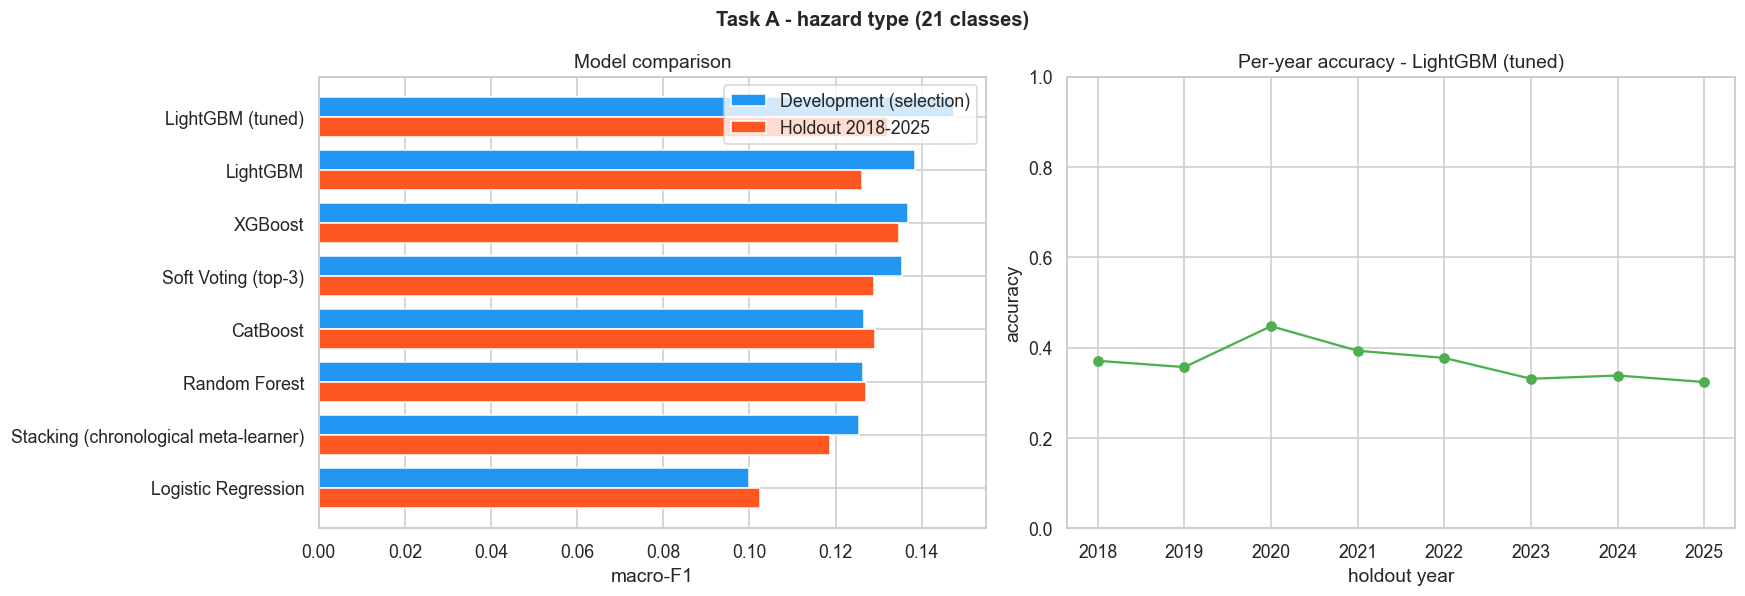

  saved F03_A_comparison.png


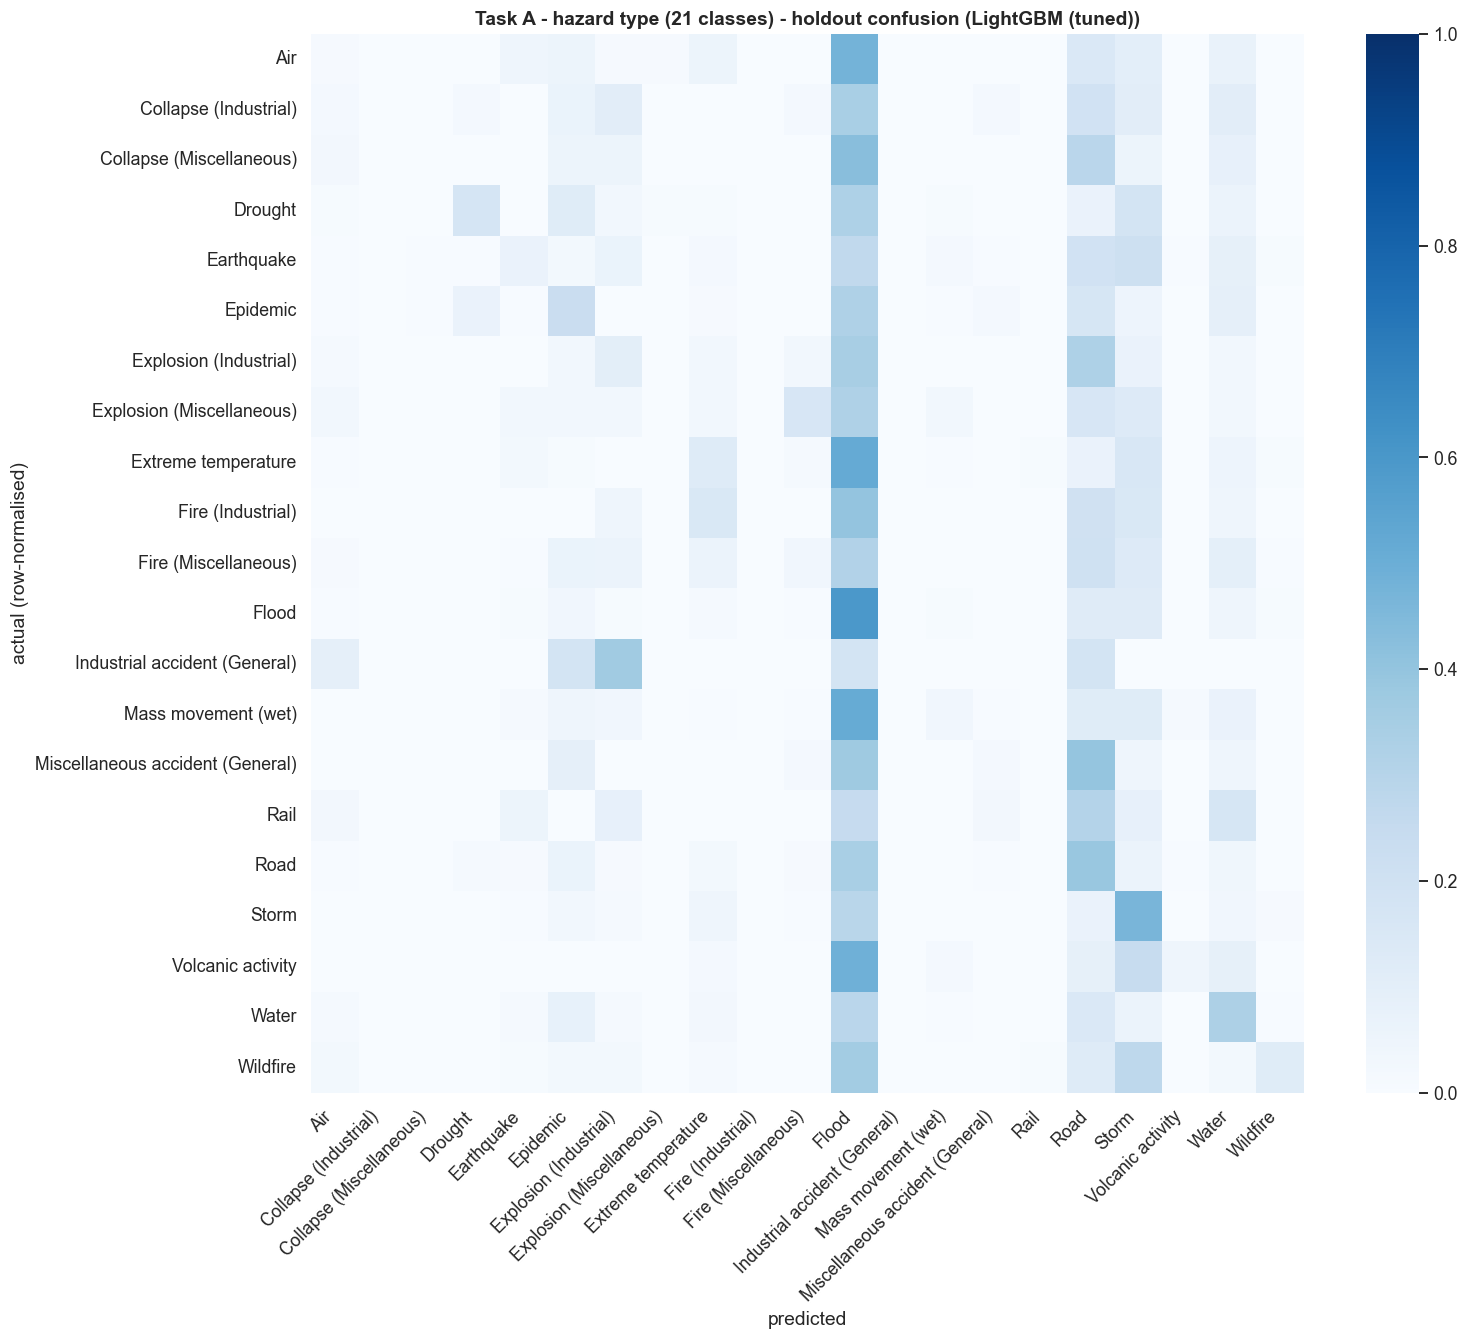

  saved F04_A_confusion.png
  saved T_per_class_A.csv
[A] accuracy 0.366 vs macro-F1 0.132 (gap 0.234). Classes with support but ZERO recall: ['Collapse (Industrial)', 'Collapse (Miscellaneous)', 'Explosion (Miscellaneous)', 'Fire (Industrial)', 'Industrial accident (General)', 'Rail']
[   5.7 min] done A


In [17]:
run_and_report('A')

## 10 · Task S2 — severity from deaths + affected

[   5.7 min] start S2


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (77 outputs left out)

C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(



=== Task S2 - severity from deaths + affected | train 3,480 (after purge) | holdout 2,582 | winner by DEVELOPMENT score: LightGBM (tuned) ===


,Model,Dev Acc,Dev Macro F1,Dev Bal Acc,Test Acc,Test Acc 95% CI,Test Macro F1,Test Macro F1 95% CI,Test Bal Acc,Test Bal Acc 95% CI,Test Log loss,Test Ordinal MAE,Fit time (s)
0,LightGBM (tuned),0.487578,0.455979,0.461592,0.467080,"0.467 [0.447, 0.487]",0.435892,"0.436 [0.416, 0.455]",0.436306,"0.436 [0.418, 0.455]",1.154367,0.725019,1.945024
1,Stacking (chronological meta-learner),0.486801,0.448177,0.448923,0.462045,"0.462 [0.443, 0.482]",0.409658,"0.410 [0.391, 0.429]",0.424222,"0.424 [0.407, 0.442]",1.132519,0.695972,NaN
2,Soft Voting (top-3),0.479037,0.446081,0.451561,0.471727,"0.472 [0.452, 0.491]",0.439031,"0.439 [0.418, 0.459]",0.440020,"0.440 [0.422, 0.459]",1.155861,0.718048,NaN
3,CatBoost,0.478261,0.444908,0.450256,0.470953,"0.471 [0.450, 0.491]",0.439293,"0.439 [0.418, 0.459]",0.439839,"0.440 [0.420, 0.458]",1.156614,0.717661,3.704858
4,XGBoost,0.469720,0.436059,0.442470,0.463594,"0.464 [0.444, 0.483]",0.432862,"0.433 [0.413, 0.452]",0.433380,"0.433 [0.415, 0.452]",1.180647,0.722308,2.999128
5,Logistic Regression,0.475155,0.434925,0.444638,0.462820,"0.463 [0.443, 0.482]",0.430111,"0.430 [0.410, 0.450]",0.431427,"0.431 [0.413, 0.451]",1.145790,0.728505,0.324253
6,LightGBM,0.450311,0.426561,0.429986,0.453137,"0.453 [0.434, 0.473]",0.424559,"0.425 [0.405, 0.444]",0.424372,"0.424 [0.406, 0.443]",1.309334,0.746321,2.964004
7,Random Forest,0.469720,0.425767,0.440339,0.472502,"0.473 [0.453, 0.491]",0.431755,"0.432 [0.413, 0.451]",0.436346,"0.436 [0.419, 0.454]",1.150523,0.723470,2.399566
8,Majority-class baseline,NaN,NaN,NaN,0.328428,"0.328 [0.310, 0.347]",0.123615,"0.124 [0.118, 0.129]",0.250000,"0.250 [0.250, 0.250]",1.363744,1.269558,NaN


  saved T10_results_S2.csv


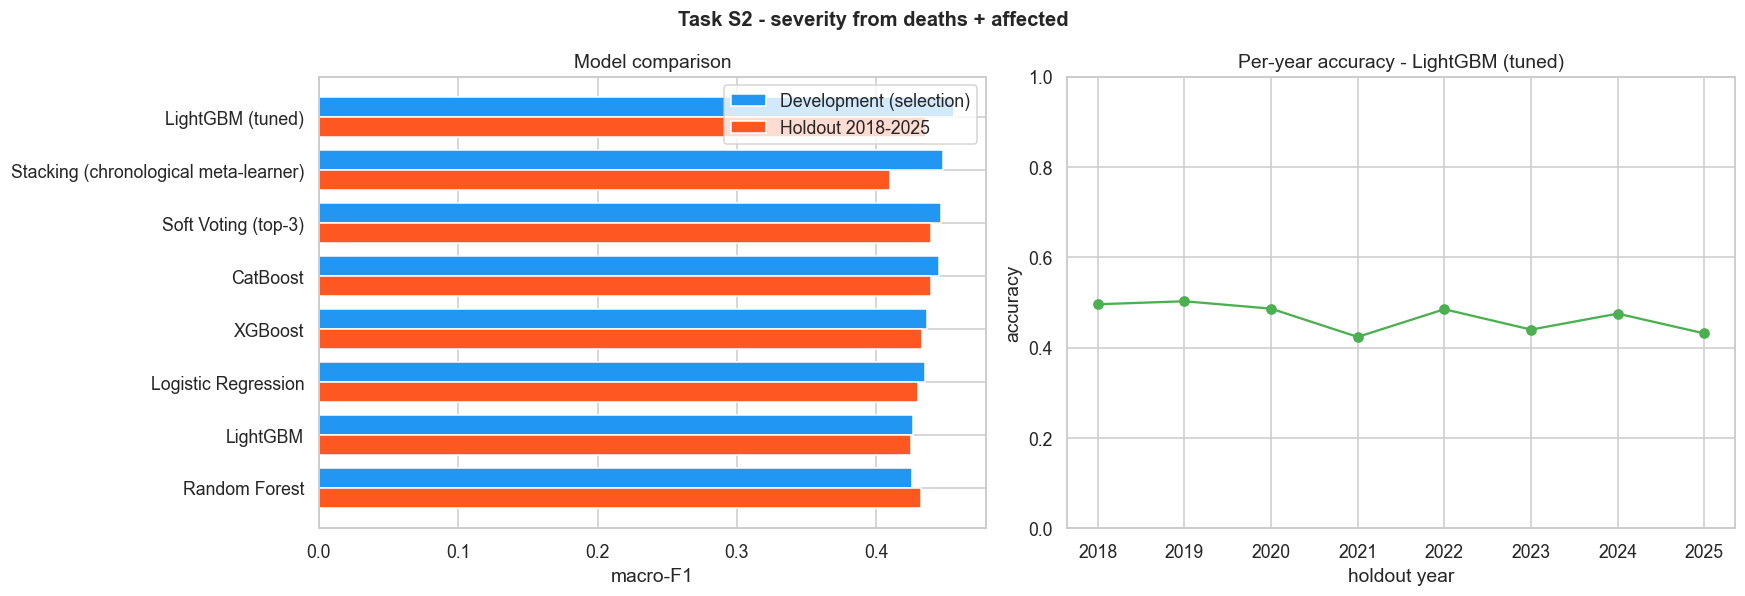

  saved F05_S2_comparison.png


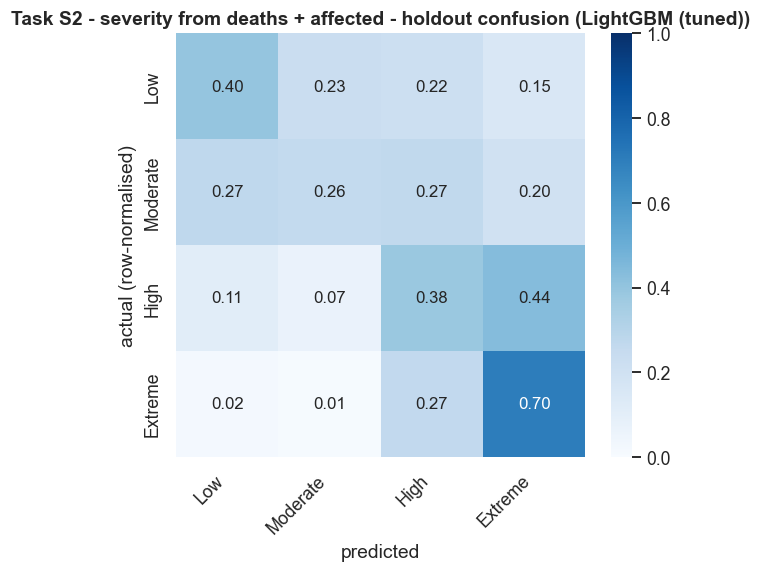

  saved F06_S2_confusion.png
  saved T_per_class_S2.csv
[S2] accuracy 0.467 vs macro-F1 0.436 (gap 0.031). Classes with support but ZERO recall: none
[   6.5 min] done S2


In [18]:
run_and_report('S2')

## 11 · Task S3 — severity from deaths + affected + damage (all three observed)

[   6.5 min] start S3


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (55 outputs left out)

  [S3] LightGBM (tuned)          1.3s



=== Task S3 - severity from deaths + affected + damage | train 965 (after purge) | holdout 538 | winner by DEVELOPMENT score: LightGBM (tuned) ===


,Model,Dev Acc,Dev Macro F1,Dev Bal Acc,Test Acc,Test Acc 95% CI,Test Macro F1,Test Macro F1 95% CI,Test Bal Acc,Test Bal Acc 95% CI,Test Log loss,Test Ordinal MAE,Fit time (s)
0,LightGBM (tuned),0.389549,0.379840,0.377065,0.321561,"0.322 [0.281, 0.363]",0.313019,"0.313 [0.274, 0.352]",0.310661,"0.311 [0.272, 0.350]",1.390713,0.923792,1.303622
1,CatBoost,0.365796,0.364975,0.364056,0.312268,"0.312 [0.273, 0.353]",0.310456,"0.310 [0.271, 0.350]",0.305693,"0.306 [0.267, 0.347]",1.611554,0.968401,1.954366
2,Soft Voting (top-3),0.358670,0.355211,0.356545,0.315985,"0.316 [0.276, 0.357]",0.314278,"0.314 [0.273, 0.354]",0.309544,"0.310 [0.270, 0.350]",1.527116,0.946097,NaN
3,LightGBM,0.353919,0.349996,0.353674,0.304833,"0.305 [0.265, 0.345]",0.302654,"0.303 [0.263, 0.343]",0.299400,"0.299 [0.261, 0.340]",1.845750,0.977695,1.509107
4,XGBoost,0.327791,0.322529,0.325184,0.308550,"0.309 [0.270, 0.348]",0.304959,"0.305 [0.266, 0.344]",0.302549,"0.303 [0.265, 0.344]",1.698685,0.985130,1.614750
5,Random Forest,0.332542,0.322491,0.329510,0.336431,"0.336 [0.296, 0.375]",0.334631,"0.335 [0.294, 0.374]",0.331970,"0.332 [0.292, 0.372]",1.430601,0.953532,2.063324
6,Stacking (chronological meta-learner),0.313539,0.305142,0.304270,0.347584,"0.348 [0.309, 0.390]",0.347537,"0.348 [0.307, 0.389]",0.347541,"0.348 [0.308, 0.390]",1.363460,0.944238,NaN
7,Logistic Regression,0.330166,0.301191,0.310187,0.308550,"0.309 [0.272, 0.350]",0.299767,"0.300 [0.261, 0.340]",0.296122,"0.296 [0.260, 0.336]",1.377098,0.957249,0.155206
8,Majority-class baseline,NaN,NaN,NaN,0.304833,"0.305 [0.266, 0.348]",0.116809,"0.117 [0.105, 0.129]",0.250000,"0.250 [0.250, 0.250]",1.372368,0.882900,NaN


  saved T10_results_S3.csv


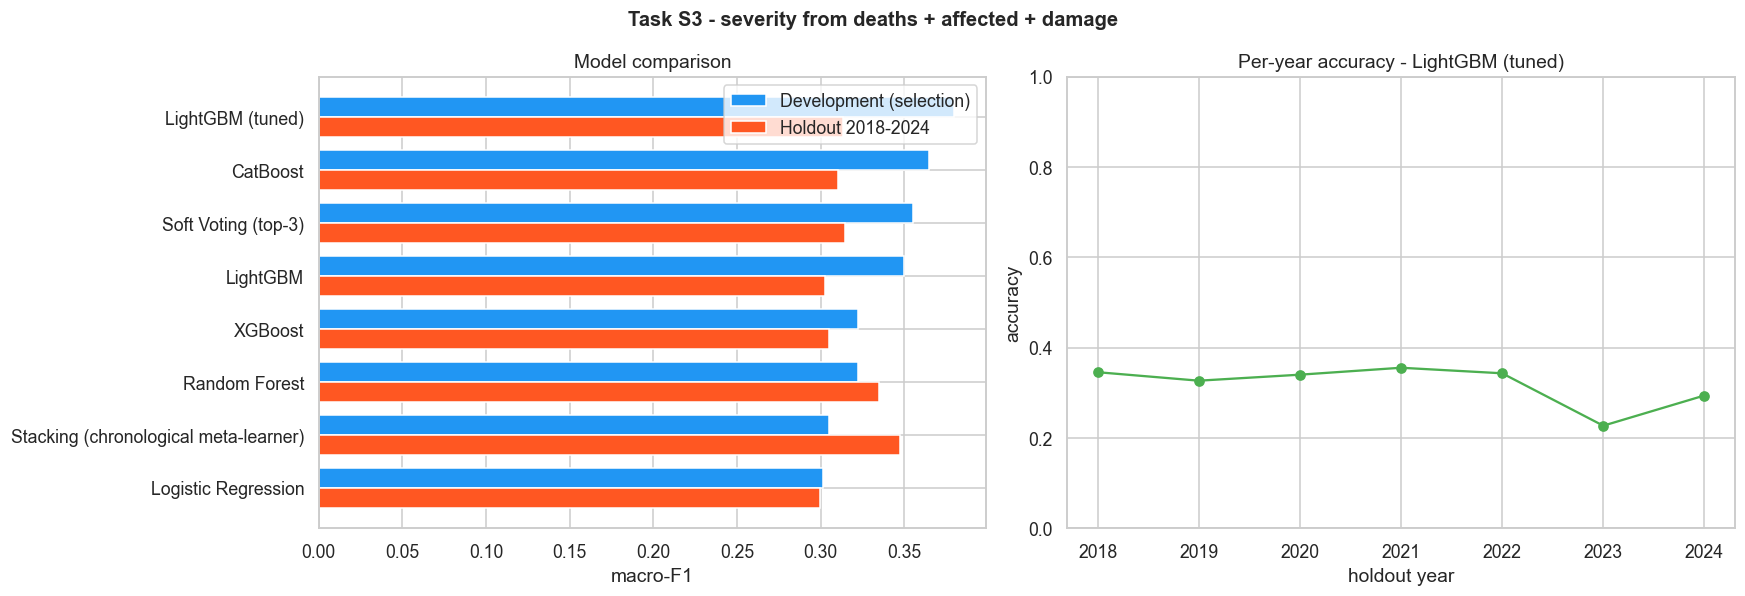

  saved F07_S3_comparison.png


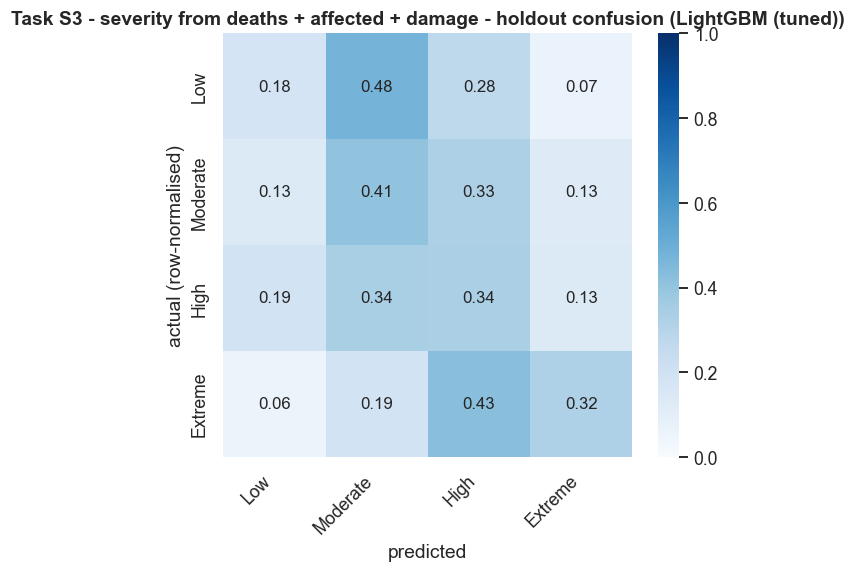

  saved F08_S3_confusion.png
  saved T_per_class_S3.csv
[S3] accuracy 0.322 vs macro-F1 0.313 (gap 0.009). Classes with support but ZERO recall: none
[   6.9 min] done S3


In [19]:
run_and_report('S3')

## 12 · Task C — regression of observed outcomes

Targets are `log1p(deaths)`, `log1p(total affected)` and `log1p(adjusted damage, 000 US$)`. **Metrics labelled "(log)" are on the log1p scale; "(orig)" columns are persons (deaths, affected) or thousand US$ (damage) after `expm1`.** The back-transformation of a log-scale mean prediction yields a conditional-median-like quantity, not the conditional mean (no smearing correction), so original-scale RMSE is expected to be dominated by a few extreme events. Both a median and a mean baseline are reported.

In [20]:
for k in ['C_log_deaths', 'C_log_affected', 'C_log_damage']: run_and_report(k)

[   6.9 min] start C_log_deaths


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


... (281 outputs left out)

  [C_log_damage] LightGBM (tuned)          0.4s



=== Task C - log_damage | train 2,432 (after purge) | holdout 806 | winner by DEVELOPMENT score: Soft Voting (top-3) ===


,Model,Dev RMSE (log),Dev R2 (log),Test RMSE (log),Test RMSE (log) 95% CI,Test MAE (log),Test R2 (log),Test R2 (log) 95% CI,Test MAE (orig),Test RMSE (orig),Test MedAE (orig),Fit time (s)
0,Soft Voting (top-3),2.165847,0.232541,2.011218,"2.011 [1.909, 2.112]",1.579173,0.245792,"0.246 [0.175, 0.311]",1.719630e+06,6.476297e+06,172738.894282,NaN
1,LightGBM (tuned),2.169427,0.230002,2.005035,"2.005 [1.903, 2.104]",1.573494,0.250423,"0.250 [0.183, 0.311]",1.735907e+06,6.518632e+06,158524.244828,0.435644
2,Ridge,2.180377,0.222209,2.034596,"2.035 [1.932, 2.137]",1.610993,0.228157,"0.228 [0.153, 0.298]",1.732444e+06,6.475485e+06,182253.638809,0.153104
3,Stacking (chronological meta-learner),2.205347,0.204292,1.895208,"1.895 [1.793, 1.993]",1.487740,0.330291,"0.330 [0.276, 0.379]",1.694313e+06,6.427534e+06,208344.935586,NaN
4,CatBoost,2.240530,0.178701,2.085152,"2.085 [1.982, 2.188]",1.624843,0.189322,"0.189 [0.104, 0.262]",1.691729e+06,6.415904e+06,195738.191732,2.296275
5,Random Forest,2.249409,0.172179,2.054110,"2.054 [1.951, 2.152]",1.600172,0.213280,"0.213 [0.128, 0.287]",1.667343e+06,6.334450e+06,186646.131244,2.609101
6,XGBoost,2.249984,0.171756,2.076096,"2.076 [1.971, 2.179]",1.616394,0.196349,"0.196 [0.107, 0.273]",1.663870e+06,6.336971e+06,194337.601563,0.935644
7,LightGBM,2.269521,0.157310,2.120135,"2.120 [2.017, 2.218]",1.662777,0.161893,"0.162 [0.068, 0.241]",1.673188e+06,6.319609e+06,203643.821513,1.153709
8,Median baseline,NaN,NaN,2.375334,"2.375 [2.261, 2.483]",1.922516,-0.052015,"-0.052 [-0.091, -0.024]",1.839453e+06,6.640360e+06,129852.564183,NaN
9,Mean baseline,NaN,NaN,2.462431,"2.462 [2.349, 2.569]",1.992729,-0.130578,"-0.131 [-0.191, -0.081]",1.847345e+06,6.649817e+06,125266.310247,NaN


  saved T10_results_C_log_damage.csv
Stacking weights: {'LightGBM (tuned)': 0.307, 'Ridge': 0.413, 'CatBoost': 0.18, 'Random Forest': 0.022}
[   9.6 min] done C_log_damage


## 13. Retrospective predictor sensitivity

Each variant uses the same outer split and untuned LightGBM. The named feature groups examine data availability and dependence on reported outcomes. Variants that use label components, concurrent outcomes or hazard-derived proxies are diagnostic. Their performance is unsuitable as evidence of operational prediction.


Running sensitivity analysis: Task A - hazard type (21 classes)


  guard OK [A variant primary] 5 features


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  guard OK [A variant hist] 23 features


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


  guard OK [A variant geo] 7 features


... (93 outputs left out)


=== Task C - log_damage (LightGBM defaults; same cohort / target / split) ===


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Variant,Valid predictor set,RMSE (log),R2 (log),Delta RMSE (log) vs primary
0,primary,yes,2.1201,0.1619,0.0000
1,+ outcome history (retrospective),yes,1.9940,0.2587,-0.1261
2,+ magnitude/scale (retrospective),yes,2.0804,0.1930,-0.0398
3,+ response flags (retrospective),yes,2.1455,0.1417,0.0253
4,+ coordinates,yes,2.1729,0.1196,0.0528
5,+ start_year,yes,1.9994,0.2546,-0.1207
6,+ all retrospective groups,yes,1.9710,0.2757,-0.1492
7,DIAG + other concurrent outcomes,no (diagnostic),1.8390,0.3694,-0.2811


  saved T11_sensitivity_C_log_damage.csv
[  10.9 min] sensitivity C_log_damage


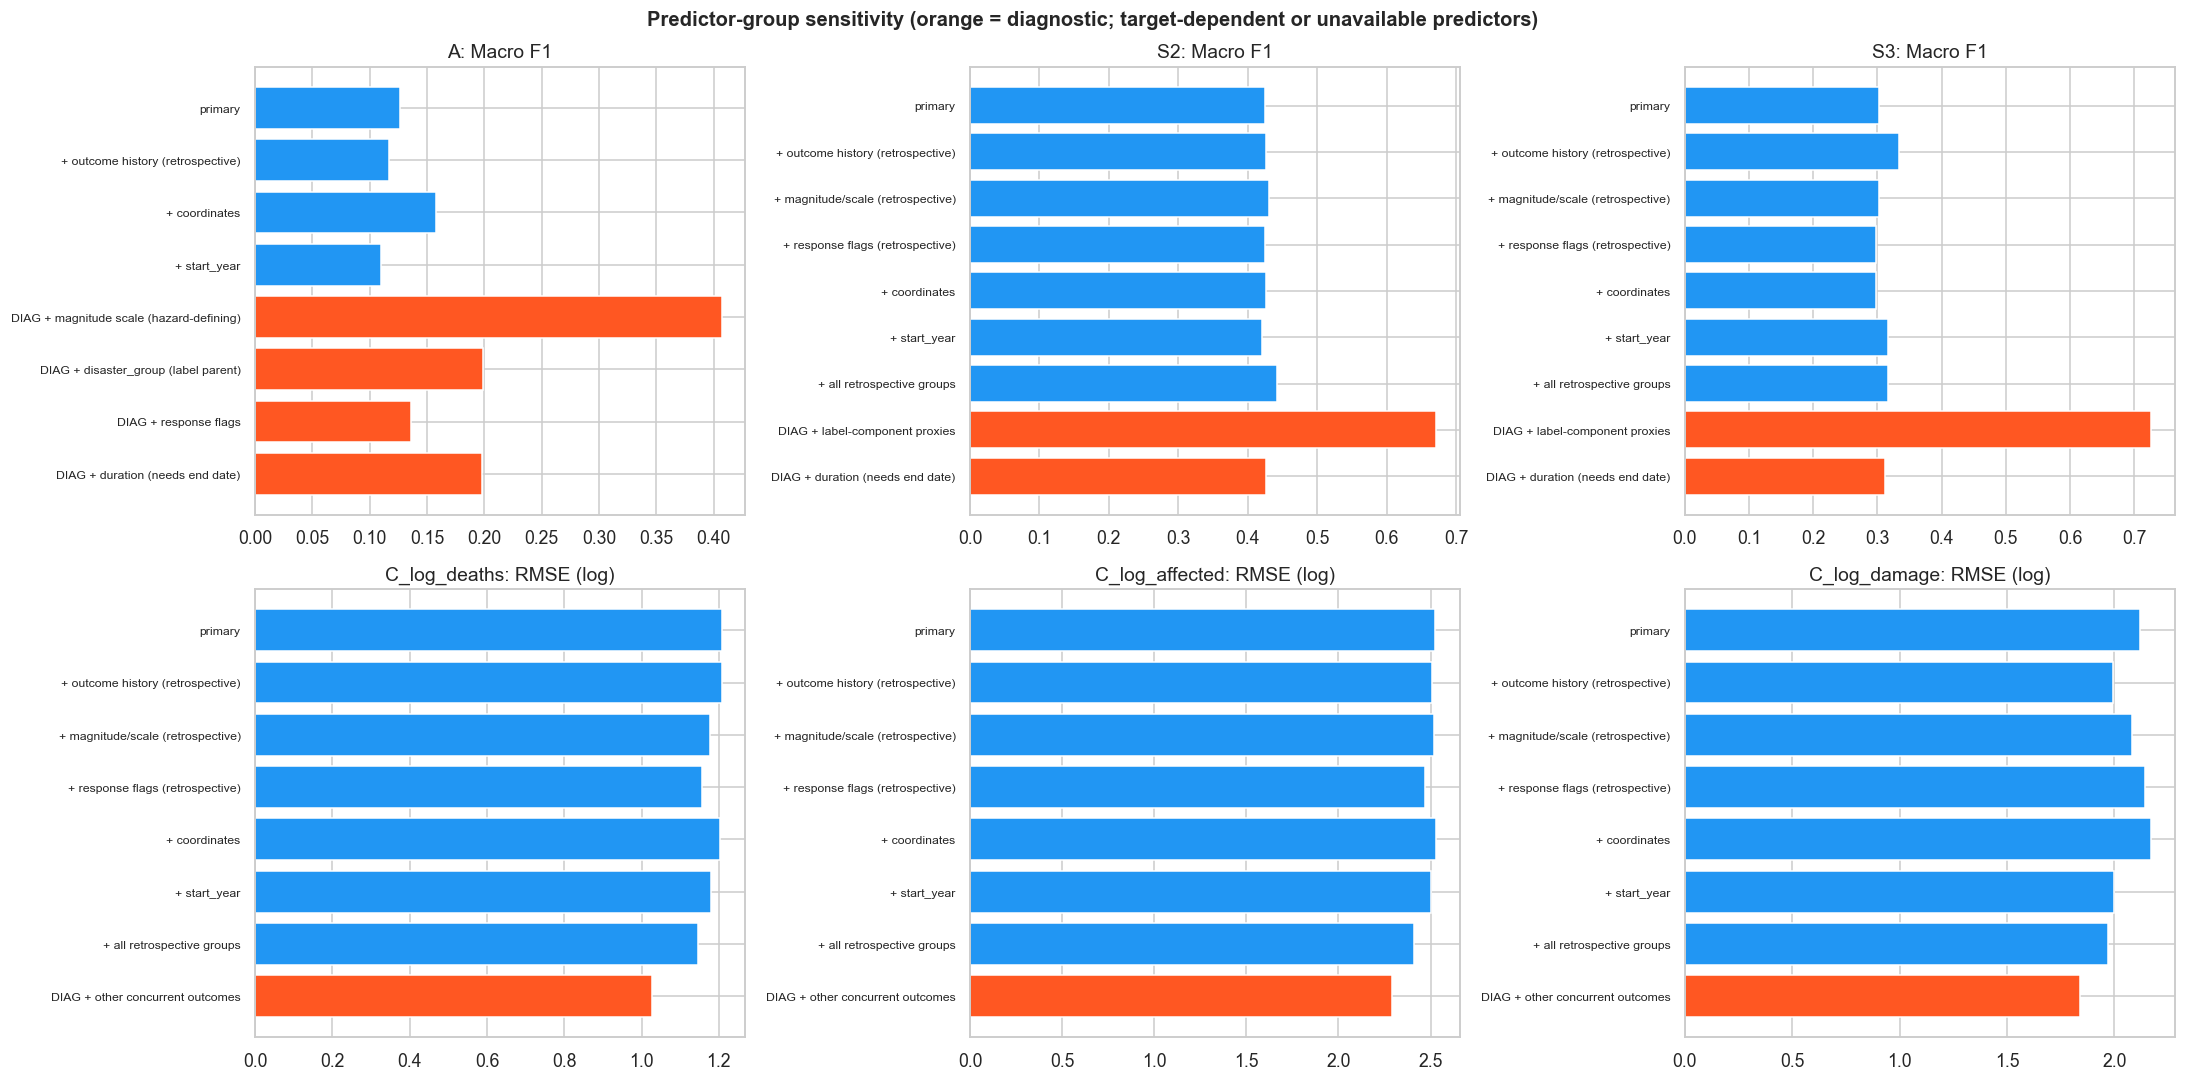

  saved F09_sensitivity_analysis.png

Sensitivity analysis completed.


In [21]:

# ============================================================
# CELL 35: PREDICTOR-GROUP SENSITIVITY ANALYSIS
# Corrected historical features and event-level separation
# ============================================================

# ------------------------------------------------------------
# 1. Define additional predictor groups
# ------------------------------------------------------------

GROUP_COLS = {
    'mag': dict(
        num=['magnitude'],
        low=['magnitude_scale']
    ),

    'resp': dict(
        num=[
            'has_ofda_response',
            'has_appeal',
            'has_declaration'
        ]
    ),

    'geo': dict(
        num=['latitude', 'longitude']
    ),

    'year': dict(
        num=['start_year']
    ),

    'dur': dict(
        num=['duration_days_exact']
    ),

    'comp': dict(
        num=[
            'log_no_injured',
            'log_no_affected',
            'log_no_homeless',
            'log_total_damage'
        ]
    ),

    'group': dict(
        low=['disaster_group']
    )
}


# ------------------------------------------------------------
# 2. Define sensitivity variants
# ------------------------------------------------------------

VARIANTS = {

    'A': [
        ('primary', [], False),

        ('+ outcome history (retrospective)',
         ['hist'], False),

        ('+ coordinates',
         ['geo'], False),

        ('+ start_year',
         ['year'], False),

        ('DIAG + magnitude scale (hazard-defining)',
         ['mag'], True),

        ('DIAG + disaster_group (label parent)',
         ['group'], True),

        ('DIAG + response flags',
         ['resp'], True),

        ('DIAG + duration (needs end date)',
         ['dur'], True)
    ],

    'sev': [
        ('primary', [], False),

        ('+ outcome history (retrospective)',
         ['hist'], False),

        ('+ magnitude/scale (retrospective)',
         ['mag'], False),

        ('+ response flags (retrospective)',
         ['resp'], False),

        ('+ coordinates',
         ['geo'], False),

        ('+ start_year',
         ['year'], False),

        ('+ all retrospective groups',
         ['hist', 'mag', 'resp', 'geo'], False),

        ('DIAG + label-component proxies',
         ['comp'], True),

        ('DIAG + duration (needs end date)',
         ['dur'], True)
    ],

    'reg': [
        ('primary', [], False),

        ('+ outcome history (retrospective)',
         ['hist'], False),

        ('+ magnitude/scale (retrospective)',
         ['mag'], False),

        ('+ response flags (retrospective)',
         ['resp'], False),

        ('+ coordinates',
         ['geo'], False),

        ('+ start_year',
         ['year'], False),

        ('+ all retrospective groups',
         ['hist', 'mag', 'resp', 'geo'], False),

        ('DIAG + other concurrent outcomes',
         ['otherout'], True)
    ]
}


# ------------------------------------------------------------
# 3. Run one sensitivity experiment
# ------------------------------------------------------------

def run_variant(T, R, groups, diag):

    key = T['key']
    kind = T['kind']

    # Copy the original feature specification
    spec = {
        k: list(v)
        for k, v in T['spec'].items()
    }

    # --------------------------------------------------------
    # Add requested predictor groups
    # --------------------------------------------------------

    for g in groups:

        if g == 'hist':
            continue

        if g == 'otherout':

            current_target = key.replace('C_', '')

            gc = dict(
                num=[
                    col for col in LOGS
                    if col != current_target
                ]
            )

        else:
            gc = GROUP_COLS[g]

        for feature_type in ('num', 'low', 'high'):

            spec.setdefault(feature_type, [])

            spec[feature_type] += gc.get(
                feature_type, []
            )

    # Remove duplicated feature names
    for feature_type in ('num', 'low', 'high'):

        spec[feature_type] = list(
            dict.fromkeys(spec[feature_type])
        )

    # --------------------------------------------------------
    # Obtain global row positions
    # --------------------------------------------------------

    trr = np.asarray(
        T['rows'][R['tr']],
        dtype=int
    )

    ter = np.asarray(
        T['rows'][R['te']],
        dtype=int
    )

    if len(trr) == 0 or len(ter) == 0:
        raise ValueError(
            f"Empty partition in {key} sensitivity experiment."
        )

    if np.intersect1d(trr, ter).size:
        raise ValueError(
            f"Record overlap detected in {key}."
        )

    # --------------------------------------------------------
    # Verify event-level separation
    # --------------------------------------------------------

    dfit = df.iloc[trr]
    dapp = df.iloc[ter]

    if dfit.event_id.isna().any() or dapp.event_id.isna().any():
        raise ValueError(
            f"Missing event IDs in {key} sensitivity experiment."
        )

    shared_events = set(
        dfit.event_id
    ).intersection(
        set(dapp.event_id)
    )

    if shared_events:
        raise ValueError(
            f"{key}: {len(shared_events)} shared events "
            "between training and evaluation."
        )

    # --------------------------------------------------------
    # Construct predictor matrices
    # --------------------------------------------------------

    Xf = get_X(
        trr,
        spec,
        frame=df
    ).reset_index(drop=True)

    Xa = get_X(
        ter,
        spec,
        frame=df
    ).reset_index(drop=True)

    # --------------------------------------------------------
    # Add corrected historical features when requested
    # --------------------------------------------------------

    if 'hist' in groups:

        Hf, Ha = hist_frames(
            df,
            trr,
            ter,
            'A' if key == 'A' else 'B'
        )

        Hf = Hf.reset_index(drop=True)
        Ha = Ha.reset_index(drop=True)

        if len(Hf) != len(Xf) or len(Ha) != len(Xa):
            raise AssertionError(
                "Historical feature alignment failed."
            )

        Xf = pd.concat(
            [Xf, Hf],
            axis=1
        )

        Xa = pd.concat(
            [Xa, Ha],
            axis=1
        )

        spec['num'] += list(Hf.columns)

    # --------------------------------------------------------
    # Verify feature consistency
    # --------------------------------------------------------

    if Xf.columns.duplicated().any():
        raise ValueError(
            f"Duplicate training features in {key}."
        )

    if Xa.columns.duplicated().any():
        raise ValueError(
            f"Duplicate evaluation features in {key}."
        )

    if list(Xf.columns) != list(Xa.columns):
        raise AssertionError(
            "Training and evaluation feature columns differ."
        )

    if not diag:

        guard(
            spec,
            key,
            spec['num'] + spec['low'] + spec['high'],
            allow_history=('hist' in groups),
            label=(
                f"{key} variant "
                f"{'+'.join(groups) or 'primary'}"
            )
        )

    # --------------------------------------------------------
    # Fit model
    # --------------------------------------------------------

    zoo = (
        clf_zoo()
        if kind == 'clf'
        else reg_zoo()
    )

    est = clone(zoo['LightGBM'])

    pipe = Pipeline([
        (
            'prep',
            make_prep(
                spec,
                'multiclass' if kind == 'clf'
                else 'continuous'
            )
        ),
        ('clf', est)
    ])

    pipe.fit(
        Xf,
        T['y'][R['tr']]
    )

    # --------------------------------------------------------
    # Evaluate on the identical outer evaluation records
    # --------------------------------------------------------

    yt = T['y'][R['te']]

    if kind == 'clf':

        probabilities = pipe.predict_proba(Xa)

        model_classes = pipe.named_steps['clf'].classes_

        predictions = model_classes[
            probabilities.argmax(axis=1)
        ]

        accuracy, macro_f1, balanced_acc = clf_fast(
            yt,
            predictions,
            R['K']
        )

        return {
            'Accuracy': accuracy,
            'Macro F1': macro_f1,
            'Balanced Acc': balanced_acc
        }

    else:

        predictions = pipe.predict(Xa)

        metrics = reg_metrics(
            yt,
            predictions
        )

        return {
            'RMSE (log)': metrics['RMSE'],
            'R2 (log)': metrics['R2']
        }


# ------------------------------------------------------------
# 4. Execute sensitivity experiments
# ------------------------------------------------------------

SENS = {}

for key, T in TASKS.items():

    fam = (
        'A' if key == 'A'
        else 'sev' if key in ('S2', 'S3')
        else 'reg'
    )

    R = RES[key]

    rows = []

    print(
        f"\nRunning sensitivity analysis: {T['title']}"
    )

    for label, groups, diag in VARIANTS[fam]:

        result = run_variant(
            T,
            R,
            groups,
            diag
        )

        rows.append({

            'Variant': label,

            'Valid predictor set': (
                'no (diagnostic)'
                if diag
                else 'yes'
            ),

            **result

        })

    tab = pd.DataFrame(rows)

    metric_col = (
        'Macro F1'
        if T['kind'] == 'clf'
        else 'RMSE (log)'
    )

    tab[
        f'Delta {metric_col} vs primary'
    ] = (
        tab[metric_col] - tab[metric_col].iloc[0]
    ).round(4)

    SENS[key] = tab

    print(
        f"\n=== {T['title']} "
        "(LightGBM defaults; same cohort / target / split) ==="
    )

    display(tab.round(4))

    save_table(
        tab.round(4),
        f'T11_sensitivity_{key}.csv',
        idx=False
    )

    tick(
        f'sensitivity {key}'
    )


# ------------------------------------------------------------
# 5. Generate sensitivity comparison figure
# ------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    3,
    figsize=(20, 10)
)

for ax, (key, tab) in zip(
    axes.ravel(),
    SENS.items()
):

    metric_col = (
        'Macro F1'
        if TASKS[key]['kind'] == 'clf'
        else 'RMSE (log)'
    )

    colors = [
        PAL[1] if value.startswith('no')
        else PAL[0]
        for value in tab['Valid predictor set']
    ]

    ax.barh(
        tab['Variant'][::-1],
        tab[metric_col][::-1],
        color=colors[::-1]
    )

    ax.set_title(
        f'{key}: {metric_col}'
    )

    ax.tick_params(
        axis='y',
        labelsize=8
    )

fig.suptitle(
    'Predictor-group sensitivity '
    '(orange = diagnostic; target-dependent or unavailable predictors)',
    fontweight='bold'
)

fig.tight_layout()

savefig(
    fig,
    'sensitivity_analysis'
)

print("\nSensitivity analysis completed.")


## 14. Evaluation protocol comparison

The temporal benchmark is compared with seeded random event-grouped splits of the same eligible task cohort. Target definitions, feature specifications and untuned LightGBM are fixed. Random draws target the temporal test share of distinct events. Row counts can vary because entire events are assigned together. The reported standard deviation describes variability across the random splits.

C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (57 outputs left out)

C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


[  12.2 min] protocol comparison C_log_damage
  saved T12_protocol_sensitivity.csv
  saved T12_protocol_summary.csv


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


,Task,Design,Metric,Runs,Mean score,SD across splits,Min holdout records,Max holdout records
0,A,Temporal,Macro F1,1,0.126178,NaN,4526,4526
1,A,Random event-grouped,Macro F1,10,0.144506,0.006443,4265,4415
2,S2,Temporal,Macro F1,1,0.424559,NaN,2582,2582
3,S2,Random event-grouped,Macro F1,10,0.442350,0.007911,2567,2592
4,S3,Temporal,Macro F1,1,0.302654,NaN,538,538
5,S3,Random event-grouped,Macro F1,10,0.327662,0.019660,533,554
6,C_log_deaths,Temporal,RMSE (log),1,1.207093,NaN,3542,3542
7,C_log_deaths,Random event-grouped,RMSE (log),10,1.117448,0.027501,3338,3464
8,C_log_affected,Temporal,RMSE (log),1,2.525808,NaN,3432,3432
9,C_log_affected,Random event-grouped,RMSE (log),10,2.261584,0.016803,3346,3404


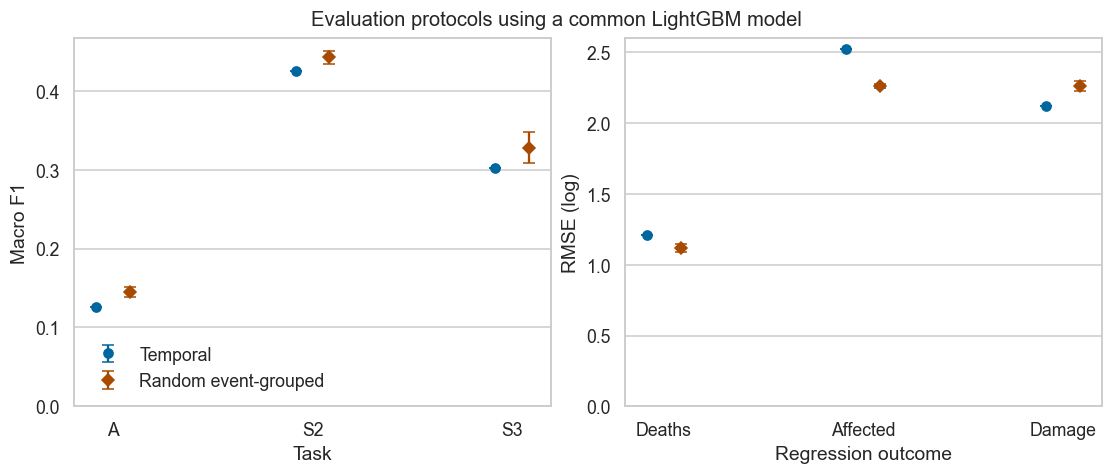

  saved F10_protocol_comparison.png


In [22]:
# The same task cohort, reference labels, preprocessing and untuned LightGBM
# are used for both protocols. The randomized test share targets the temporal
# share of unique events, so record counts can differ across draws.
PROTOCOL_DESIGNS = ('Temporal', 'Random event-grouped')
protocol_rows = []
for key, task in TASKS.items():
    result = RES[key]
    y, event_ids = task['y'], task['eids']
    classification = task['kind'] == 'clf'
    classes = np.asarray(task['class_names']) if classification else None
    chrono_tr, chrono_te = result['tr'], result['te']
    heldout_event_share = len(np.unique(event_ids[chrono_te])) / len(np.unique(event_ids))
    splitter = GroupShuffleSplit(
        n_splits=P['protocol_repeats'],
        test_size=heldout_event_share,
        random_state=SEED,
    )
    partitions = [('Temporal', 0, chrono_tr, chrono_te)]
    partitions.extend(
        ('Random event-grouped', repeat, tr, te)
        for repeat, (tr, te) in enumerate(
            splitter.split(task['X'], y, groups=event_ids), start=1
        )
    )
    prediction_frames = []
    for design, repeat, train, test in partitions:
        n_shared = len(set(event_ids[train]).intersection(event_ids[test]))
        if n_shared:
            raise AssertionError(f'{key} {design} run {repeat}: shared events')
        row = {
            'Task': key,
            'Design': design,
            'Repeat': repeat,
            'Training records': len(train),
            'Evaluation records': len(test),
            'Training events': len(np.unique(event_ids[train])),
            'Evaluation events': len(np.unique(event_ids[test])),
            'Shared events': n_shared,
            'Train start year': int(task['years'][train].min()),
            'Train end year': int(task['years'][train].max()),
            'Evaluation start year': int(task['years'][test].min()),
            'Evaluation end year': int(task['years'][test].max()),
        }
        if design == 'Temporal':
            raw_predictions = result['test']['LightGBM']
            predictions = raw_predictions.argmax(1) if classification else raw_predictions
        else:
            baseline = (clf_zoo() if classification else reg_zoo())['LightGBM']
            pipeline = Pipeline([('prep', make_prep(task['spec'])), ('clf', baseline)])
            pipeline.fit(task['X'].iloc[train], y[train])
            predictions = pipeline.predict(task['X'].iloc[test])
        if classification:
            row.update({
                'Accuracy': accuracy_score(y[test], predictions),
                'Macro F1': f1_score(y[test], predictions, labels=np.arange(result['K']),
                                     average='macro', zero_division=0),
                'Balanced accuracy': balanced_accuracy_score(y[test], predictions),
            })
            observed, predicted = classes[y[test]], classes[predictions]
        else:
            row.update({'RMSE (log)': np.sqrt(mean_squared_error(y[test], predictions)),
                        'R2 (log)': r2_score(y[test], predictions)})
            observed, predicted = y[test], predictions
        protocol_rows.append(row)
        prediction_frames.append(pd.DataFrame({
            'design': design, 'repeat': repeat,
            'dis_no': task['dis_no'][test], 'event_id': event_ids[test],
            'start_year': task['years'][test], 'y_true': observed, 'prediction': predicted,
        }))
    pd.concat(prediction_frames, ignore_index=True).to_csv(
        os.path.join(DIRS['predictions'], f'protocol_predictions_{key}.csv'), index=False
    )
    tick(f'protocol comparison {key}')

protocol_table = pd.DataFrame(protocol_rows)
save_table(protocol_table, 'T12_protocol_sensitivity.csv', idx=False)
protocol_summary = []
for (key, design), frame in protocol_table.groupby(['Task', 'Design'], sort=False):
    score = 'Macro F1' if TASKS[key]['kind'] == 'clf' else 'RMSE (log)'
    protocol_summary.append({
        'Task': key, 'Design': design, 'Metric': score, 'Runs': len(frame),
        'Mean score': frame[score].mean(), 'SD across splits': frame[score].std(),
        'Min holdout records': frame['Evaluation records'].min(),
        'Max holdout records': frame['Evaluation records'].max(),
    })
protocol_summary = pd.DataFrame(protocol_summary)
save_table(protocol_summary, 'T12_protocol_summary.csv', idx=False)
display(protocol_summary)

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), layout='constrained')
for ax, metric in zip(axes, ['Macro F1', 'RMSE (log)']):
    subset = protocol_summary.loc[protocol_summary['Metric'].eq(metric)]
    order = subset['Task'].drop_duplicates().tolist()
    labels = [key.replace('C_log_', '').replace('_', ' ').capitalize() if key.startswith('C_') else key for key in order]
    for j, design in enumerate(PROTOCOL_DESIGNS):
        ordered = subset.set_index(['Design', 'Task']).loc[[(design, key) for key in order]]
        error = ordered['SD across splits'].fillna(0).to_numpy()
        ax.errorbar(np.arange(len(order)) + (j - .5) * .17, ordered['Mean score'], yerr=error,
                    marker=['o', 'D'][j], linestyle='none', capsize=4,
                    color=['#00669E', '#A84B00'][j], label=design)
    ax.set_xticks(np.arange(len(order)), labels)
    ax.set_ylabel(metric)
    ax.set_xlabel('Task' if metric == 'Macro F1' else 'Regression outcome')
    ax.set_ylim(bottom=0)
    ax.xaxis.grid(False)
axes[0].legend(frameon=False)
fig.suptitle('Evaluation protocols using a common LightGBM model')
savefig(fig, 'protocol_comparison')

## 15 · Geographic validation (country-held-out, chronological, event-purged)

Holdout-period (2018–2025) records are split into 5 groups of **countries**. For each group, a LightGBM with the primary features is trained on development-window records of **all other countries**, purging training records whose `event_id` also occurs in the held-out records, and predicts the held-out countries. Every holdout record is thus predicted by a model that never saw its country. Region/sub-region remain available, so this measures transfer to unseen countries *within known regions*, not to unseen regions.

In [23]:
# ============================================================
# CELL 38: GEOGRAPHIC VALIDATION
# Country-held-out, event-purged evaluation
# Fold-specific severity calibration for S2 and S3
# ============================================================
GEO_RESULTS = {}
GEO_CALIBRATION = []
def geo_validate(T, R, n_groups=5):
    kind = T['kind']
    key = T['key']
    K = R['K']
    y = T['y']
    yrs = T['years']
    ctry = df.country.values[T['rows']]
    te = R['te']
    dev = np.where(
        (yrs >= T['train_start']) &
        (yrs <= TRAIN_END)
    )[0]
    # --------------------------------------------------------
    # Country grouping
    # --------------------------------------------------------
    if pd.isna(ctry[te]).any():
        raise ValueError(
            f"{key}: missing country in geographic evaluation."
        )
    uc = np.array(sorted(set(ctry[te])))
    if len(uc) < 2:
        raise ValueError(
            f"{key}: insufficient countries for geographic validation."
        )
    n_groups = min(n_groups, len(uc))
    perm = np.random.RandomState(SEED).permutation(len(uc))
    grp = {
        c: i % n_groups
        for i, c in enumerate(uc[perm])
    }
    g_te = np.array([
        grp[c] for c in ctry[te]
    ])
    # --------------------------------------------------------
    # Output containers
    # --------------------------------------------------------
    pred = (
        np.full((len(te), K), 1e-9)
        if kind == 'clf'
        else np.full(len(te), np.nan)
    )
    geo_y = y[te].copy()
    baseline_class = np.full(len(te), -1, dtype=int) if kind == 'clf' else None
    baseline_mean = np.full(len(te), np.nan) if kind == 'reg' else None
    fold_details = []
    # --------------------------------------------------------
    # Country-held-out folds
    # --------------------------------------------------------
    for g in range(n_groups):
        m = g_te == g
        if not m.any():
            continue
        held = sorted(set(ctry[te[m]]))
        eval_pos = te[m]
        eval_global = T['rows'][eval_pos]
        eval_events = set(
            T['eids'][eval_pos]
        )
        # ----------------------------------------------------
        # Development training countries
        # ----------------------------------------------------
        tr = dev[
            ~np.isin(ctry[dev], held)
        ]
        tr = purge(
            tr,
            eval_pos,
            T['eids'],
            T['dis_no'],
            key,
            f'country_holdout_fold{g}',
            'shared_event_with_country_holdout'
        )
        # ----------------------------------------------------
        # Fold-specific severity calibration
        # ----------------------------------------------------
        if key in ('S2', 'S3'):
            comps = SEV_SPECS[key]
            ref_mask = (
                (df.start_year <= REF_END) &
                df[comps].notna().all(axis=1) &
                (~df.country.isin(held)) &
                (~df.event_id.isin(eval_events))
            )
            ref = df.loc[ref_mask].copy()
            if len(ref) == 0:
                raise ValueError(
                    f"{key}, fold {g}: no eligible calibration records."
                )
            cal = SeverityCalibration(comps).fit(ref)
            # Calibration quality checks
            span = cal.max_ - cal.min_
            if not np.isfinite(span).all() or (span <= 0).any():
                raise ValueError(
                    f"{key}, fold {g}: invalid calibration range."
                )
            if (
                not np.isfinite(cal.q_).all() or
                len(np.unique(np.round(cal.q_, 10))) != 3
            ):
                raise ValueError(
                    f"{key}, fold {g}: severity thresholds are not distinct."
                )
            ref_events = set(ref.event_id)
            # Ensure reference events do not overlap evaluation events
            if ref_events.intersection(eval_events):
                raise AssertionError(
                    f"{key}, fold {g}: calibration/evaluation event overlap."
                )
            # Remove any training events appearing in reference data
            shared_ref = np.isin(
                T['eids'][tr],
                list(ref_events)
            )
            if shared_ref.any():
                log_excl(
                    key,
                    f'country_holdout_fold{g}',
                    T['dis_no'][tr[shared_ref]],
                    'shared_event_with_fold_calibration_reference'
                )
                tr = tr[~shared_ref]
            # Recalculate training labels using fold calibration
            train_global = T['rows'][tr]
            y_train = cal.code(
                df.iloc[train_global]
            )
            # Recalculate evaluation labels using SAME calibration
            y_eval = cal.code(
                df.iloc[eval_global]
            )
            if (
                not np.isfinite(y_train).all() or
                not np.isfinite(y_eval).all()
            ):
                raise ValueError(
                    f"{key}, fold {g}: missing recalibrated severity labels."
                )
            y_train = y_train.astype(int)
            y_eval = y_eval.astype(int)
            geo_y[m] = y_eval
            GEO_CALIBRATION.append({
                'Task': key,
                'Fold': g,
                'Held-out countries': '; '.join(held),
                'Reference records': len(ref),
                'Reference events': len(ref_events),
                'Training records': len(tr),
                'Evaluation records': len(eval_pos),
                'Components': '; '.join(comps),
                'Threshold 25%': float(cal.q_[0]),
                'Threshold 50%': float(cal.q_[1]),
                'Threshold 75%': float(cal.q_[2])
            })
            target_definition = (
                'Fold-specific calibration using non-held-out countries'
            )
        else:
            y_train = y[tr]
            y_eval = y[eval_pos]
            target_definition = (
                'Original target definition'
            )
        if len(tr) == 0:
            raise ValueError(
                f"{key}, fold {g}: no training records remain."
            )
        # ----------------------------------------------------
        # Fit LightGBM on the geographic training partition
        # ----------------------------------------------------
        est = clone(
            (clf_zoo() if kind == 'clf' else reg_zoo())['LightGBM']
        )
        pipe = Pipeline([
            (
                'prep',
                make_prep(
                    T['spec'],
                    'multiclass' if kind == 'clf'
                    else 'continuous'
                )
            ),
            ('clf', est)
        ])
        pipe.fit(
            T['X'].iloc[tr],
            y_train
        )
        # ----------------------------------------------------
        # Geographic predictions
        # ----------------------------------------------------
        if kind == 'clf':
            model_classes = pipe.named_steps['clf'].classes_
            out = np.full(
                (m.sum(), K),
                1e-9
            )
            out[:, model_classes] = pipe.predict_proba(
                T['X'].iloc[eval_pos]
            )
            pred[m] = out
            # Fold-specific majority-class baseline
            prior = np.bincount(
                y_train,
                minlength=K
            ) / len(y_train)
            baseline_class[m] = np.argmax(prior)
        else:
            pred[m] = pipe.predict(T['X'].iloc[eval_pos])
            baseline_mean[m] = y_train.mean()
        # ----------------------------------------------------
        # Record fold details
        # ----------------------------------------------------
        fold_details.append({
            'fold': g,
            'countries': held,
            'training_records': len(tr),
            'evaluation_records': len(eval_pos),
            'target_definition': target_definition
        })
        print(
            f'{key} | Fold {g + 1}/{n_groups} | '
            f'Countries: {len(held)} | '
            f'Train: {len(tr):,} | '
            f'Evaluation: {len(eval_pos):,}'
        )
    # --------------------------------------------------------
    # Final validation checks
    # --------------------------------------------------------
    if not np.isfinite(pred).all():
        raise AssertionError(
            f"{key}: non-finite geographic predictions."
        )
    if kind == 'clf':
        if np.any(baseline_class < 0):
            raise AssertionError(
                f"{key}: incomplete geographic baseline predictions."
            )
        if not np.isfinite(geo_y).all():
            raise AssertionError(
                f"{key}: invalid geographic evaluation labels."
            )
    return {
        'pred': pred,
        'y_true': geo_y,
        'event_ids': T['eids'][te],
        'baseline_class': baseline_class,
        'baseline_mean': baseline_mean,
        'fold': g_te,
        'fold_details': fold_details
    }
# ============================================================
# RUN GEOGRAPHIC VALIDATION FOR ALL TASKS
# ============================================================
geo_rows = []
for key, T in TASKS.items():
    R = RES[key]
    print(f'\nGEOGRAPHIC VALIDATION: {key}')
    G = geo_validate(
        T,
        R,
        n_groups=5
    )
    GEO_RESULTS[key] = G
    pg = G['pred']
    yt_geo = G['y_true']
    # Standard holdout labels retain the original global definition
    yt_std = T['y'][R['te']]
    std = R['test']['LightGBM']
    te = R['te']
    classification = T['kind'] == 'clf'
    class_names = np.asarray(T['class_names']) if classification else None
    exported_geo = pd.DataFrame({
        'dis_no': T['dis_no'][te],
        'event_id': T['eids'][te],
        'start_year': T['years'][te],
        'country': df['country'].iloc[T['rows'][te]].to_numpy(),
        'fold': G['fold'],
        'y_true': class_names[yt_geo] if classification else yt_geo,
        'prediction': class_names[pg.argmax(1)] if classification else pg,
        'training_baseline': class_names[G['baseline_class']] if classification else G['baseline_mean'],
    })
    exported_geo.to_csv(os.path.join(DIRS['predictions'], f'geographic_predictions_{key}.csv'), index=False)

    # Separate event-cluster bootstrap indices
    bi_geo = boot_indices(
        G['event_ids'],
        P['n_boot'],
        SEED
    )
    bi_std = boot_indices(
        T['eids'][R['te']],
        P['n_boot'],
        SEED
    )
    if T['kind'] == 'clf':
        # ----------------------------------------------------
        # Geographic LightGBM
        # ----------------------------------------------------
        pr_geo = pg.argmax(axis=1)
        a, f, b = clf_fast(
            yt_geo,
            pr_geo,
            R['K']
        )
        bs = np.array([
            clf_fast(yt_geo[i], pr_geo[i], R['K'])
            for i in bi_geo
        ])
        geo_rows.append({
            'Task': key,
            'Setting': 'Country-held-out LightGBM',
            'Target definition': (
                'Fold-specific reference calibration'
                if key in ('S2', 'S3')
                else 'Original task definition'
            ),
            'Acc [95% CI]': ci_str(a, bs[:, 0]),
            'Macro-F1 [95% CI]': ci_str(f, bs[:, 1]),
            'Balanced Acc': b
        })
        # ----------------------------------------------------
        # Country-fold majority baseline
        # ----------------------------------------------------
        base_geo = G['baseline_class']
        ba, bf, bb = clf_fast(
            yt_geo,
            base_geo,
            R['K']
        )
        geo_rows.append({
            'Task': key,
            'Setting': 'Country-fold majority baseline',
            'Target definition': (
                'Fold-specific reference calibration'
                if key in ('S2', 'S3')
                else 'Original task definition'
            ),
            'Acc [95% CI]': f'{ba:.3f}',
            'Macro-F1 [95% CI]': f'{bf:.3f}',
            'Balanced Acc': bb
        })
        # ----------------------------------------------------
        # Standard holdout LightGBM
        # ----------------------------------------------------
        pr_std = std.argmax(axis=1)
        sa, sf, sb = clf_fast(
            yt_std,
            pr_std,
            R['K']
        )
        bs_std = np.array([
            clf_fast(yt_std[i], pr_std[i], R['K'])
            for i in bi_std
        ])
        geo_rows.append({
            'Task': key,
            'Setting': 'Standard holdout LightGBM',
            'Target definition': (
                'Global reference calibration'
                if key in ('S2', 'S3')
                else 'Original task definition'
            ),
            'Acc [95% CI]': ci_str(sa, bs_std[:, 0]),
            'Macro-F1 [95% CI]': ci_str(sf, bs_std[:, 1]),
            'Balanced Acc': sb
        })
    else:
        # ----------------------------------------------------
        # Geographic regression
        # ----------------------------------------------------
        m_geo = reg_metrics(
            yt_geo,
            pg
        )
        bs_geo = [
            reg_metrics(yt_geo[i], pg[i])
            for i in bi_geo
        ]
        geo_rows.append({
            'Task': key,
            'Setting': 'Country-held-out LightGBM',
            'Target definition': 'Observed outcome',
            'RMSE (log) [95% CI]': ci_str(
                m_geo['RMSE'],
                [b['RMSE'] for b in bs_geo]
            ),
            'R2 (log) [95% CI]': ci_str(
                m_geo['R2'],
                [b['R2'] for b in bs_geo]
            )
        })
        baseline = reg_metrics(yt_geo, G['baseline_mean'])
        geo_rows.append({
            'Task': key,
            'Setting': 'Country-fold mean baseline',
            'Target definition': 'Observed outcome',
            'RMSE (log) [95% CI]': f"{baseline['RMSE']:.3f}",
            'R2 (log) [95% CI]': f"{baseline['R2']:.3f}",
        })

        # Standard holdout
        m_std = reg_metrics(
            yt_std,
            std
        )
        bs_std = [
            reg_metrics(yt_std[i], std[i])
            for i in bi_std
        ]
        geo_rows.append({
            'Task': key,
            'Setting': 'Standard holdout LightGBM',
            'Target definition': 'Observed outcome',
            'RMSE (log) [95% CI]': ci_str(
                m_std['RMSE'],
                [b['RMSE'] for b in bs_std]
            ),
            'R2 (log) [95% CI]': ci_str(
                m_std['R2'],
                [b['R2'] for b in bs_std]
            )
        })
    tick(f'geographic validation {key}')
# ============================================================
# EXPORT GEOGRAPHIC VALIDATION RESULTS
# ============================================================
geo_fold_table = pd.DataFrame([
    {'Task': key, 'Fold': entry['fold'], 'Training records': entry['training_records'],
     'Evaluation records': entry['evaluation_records'],
     'Held-out countries': '; '.join(entry['countries']),
     'Target definition': entry['target_definition']}
    for key, result in GEO_RESULTS.items() for entry in result['fold_details']
])
save_table(geo_fold_table, 'T13_geographic_folds.csv', idx=False)
geo_tab = pd.DataFrame(geo_rows)
display(geo_tab)
save_table(
    geo_tab,
    'T13_geographic_validation.csv',
    idx=False
)
if GEO_CALIBRATION:
    geo_cal_tab = pd.DataFrame(GEO_CALIBRATION)
    display(geo_cal_tab)
    save_table(
        geo_cal_tab,
        'T13_geographic_severity_calibration.csv',
        idx=False
    )
print("\nGeographic validation completed.")
print("Fold-specific severity calibration records exported.")
print("Interpret S2/S3 results as fold-specific relative severity.")


GEOGRAPHIC VALIDATION: A


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


A | Fold 1/5 | Countries: 40 | Train: 9,476 | Evaluation: 1,030


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


A | Fold 2/5 | Countries: 40 | Train: 9,133 | Evaluation: 1,161


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (61 outputs left out)

,Task,Setting,Target definition,Acc [95% CI],Macro-F1 [95% CI],Balanced Acc,RMSE (log) [95% CI],R2 (log) [95% CI]
0,A,Country-held-out LightGBM,Original task definition,"0.270 [0.254, 0.286]","0.087 [0.076, 0.098]",0.099567,NaN,NaN
1,A,Country-fold majority baseline,Original task definition,0.297,0.022,0.047619,NaN,NaN
2,A,Standard holdout LightGBM,Original task definition,"0.367 [0.349, 0.385]","0.126 [0.115, 0.138]",0.127277,NaN,NaN
3,S2,Country-held-out LightGBM,Fold-specific reference calibration,"0.396 [0.377, 0.416]","0.384 [0.365, 0.404]",0.380056,NaN,NaN
4,S2,Country-fold majority baseline,Fold-specific reference calibration,0.328,0.124,0.250000,NaN,NaN
5,S2,Standard holdout LightGBM,Global reference calibration,"0.453 [0.434, 0.473]","0.425 [0.405, 0.444]",0.424372,NaN,NaN
6,S3,Country-held-out LightGBM,Fold-specific reference calibration,"0.273 [0.235, 0.312]","0.265 [0.227, 0.302]",0.271623,NaN,NaN
7,S3,Country-fold majority baseline,Fold-specific reference calibration,0.310,0.196,0.267729,NaN,NaN
8,S3,Standard holdout LightGBM,Global reference calibration,"0.305 [0.265, 0.345]","0.303 [0.263, 0.343]",0.299400,NaN,NaN
9,C_log_deaths,Country-held-out LightGBM,Observed outcome,NaN,NaN,NaN,"1.277 [1.203, 1.349]","0.187 [0.096, 0.254]"


  saved T13_geographic_validation.csv


,Task,Fold,Held-out countries,Reference records,Reference events,Training records,Evaluation records,Components,Threshold 25%,Threshold 50%,Threshold 75%
0,S2,0,"Bangladesh; Burundi; Chad; Chile; China, Hong ...",2900,2789,2743,537,log_deaths; log_affected,0.159523,0.210823,0.309526
1,S2,1,Belgium; Bosnia and Herzegovina; Burkina Faso;...,3046,2950,2680,567,log_deaths; log_affected,0.161315,0.208941,0.308455
2,S2,2,Angola; Australia; Austria; Azerbaijan; Benin;...,3292,3168,3113,302,log_deaths; log_affected,0.161707,0.211835,0.315164
3,S2,3,Afghanistan; Albania; Armenia; Bahamas; Bulgar...,2572,2495,2487,713,log_deaths; log_affected,0.181306,0.231139,0.340767
4,S2,4,Algeria; Argentina; Bolivia (Plurinational Sta...,3176,3048,2946,463,log_deaths; log_affected,0.161485,0.209686,0.314261
5,S3,0,Albania; Australia; Bahamas; Cambodia; Chad; C...,608,558,811,92,log_deaths; log_affected; log_damage,0.320294,0.391271,0.498039
6,S3,1,Bolivia (Plurinational State of); Canada; Croa...,639,580,857,78,log_deaths; log_affected; log_damage,0.319673,0.391414,0.493390
7,S3,2,Belgium; Cyprus; Democratic Republic of the Co...,660,602,880,51,log_deaths; log_affected; log_damage,0.318239,0.391344,0.495956
8,S3,3,Argentina; Armenia; Bangladesh; Bosnia and Her...,657,614,861,84,log_deaths; log_affected; log_damage,0.326287,0.394822,0.495726
9,S3,4,Afghanistan; Chile; China; Democratic People's...,450,411,527,233,log_deaths; log_affected; log_damage,0.327709,0.411101,0.524535


  saved T13_geographic_severity_calibration.csv

Geographic validation completed.
Fold-specific severity calibration records exported.
Interpret S2/S3 results as fold-specific relative severity.


## 16. S2 feature importance and a shuffled-label diagnostic

For an individual tree model, normalized split importance and mean absolute SHAP values describe fitted behavior. SHAP values refer to the Extreme class raw score in a seeded holdout subsample. One shuffled-label diagnostic provides a limited check on unexpected signal.

FEATURE IMPORTANCE, SHAP AND LEAKAGE CANARY
Selected explanatory model: LightGBM (tuned)
Development macro-F1: 0.456

Top 25 features:


,importance
num__month_sin,0.103705
num__month_cos,0.102723
high_ohe__country_infrequent_sklearn,0.021786
ohe__disaster_type_Road,0.017232
ohe__disaster_group_Natural,0.016518
high_ohe__country_China,0.016473
high_ohe__disaster_subtype_Riverine flood,0.014375
ohe__region_Europe,0.012589
high_ohe__type_x_region_infrequent_sklearn,0.011964
high_ohe__subregion_Southern Asia,0.011741


  saved T14_S2_feature_importance.csv


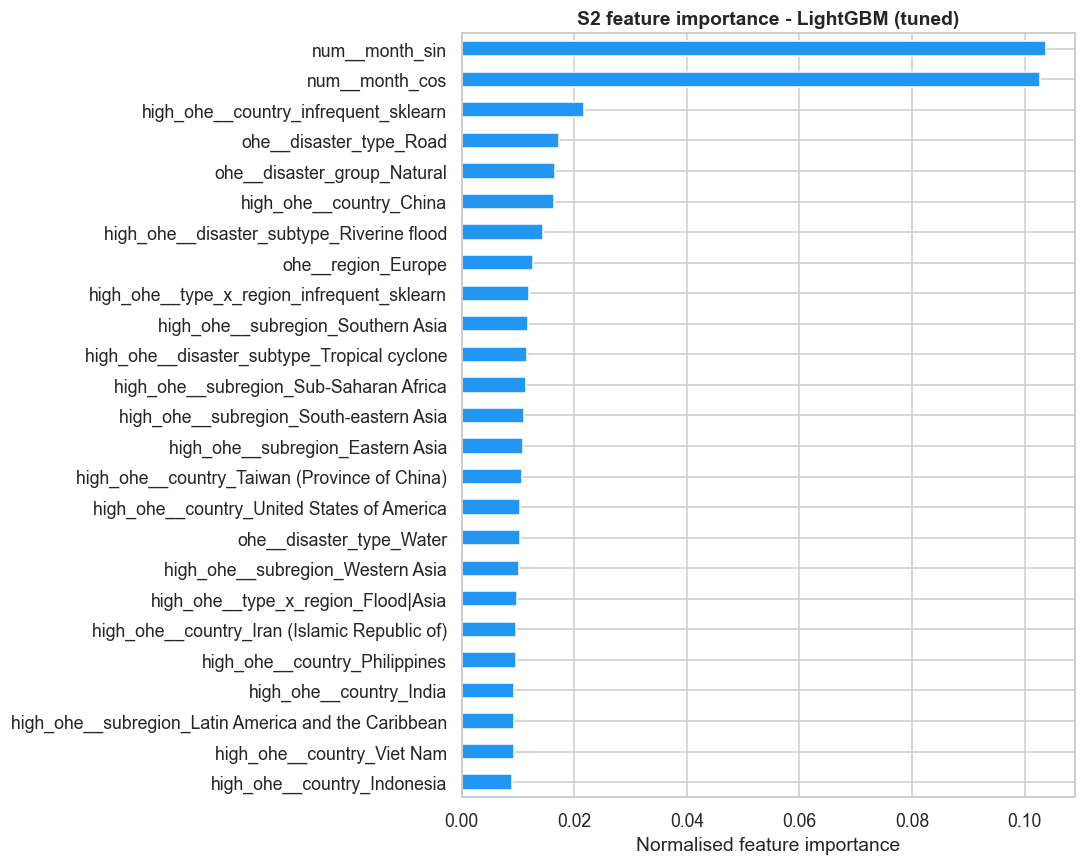

  saved F11_S2_feature_importance.png


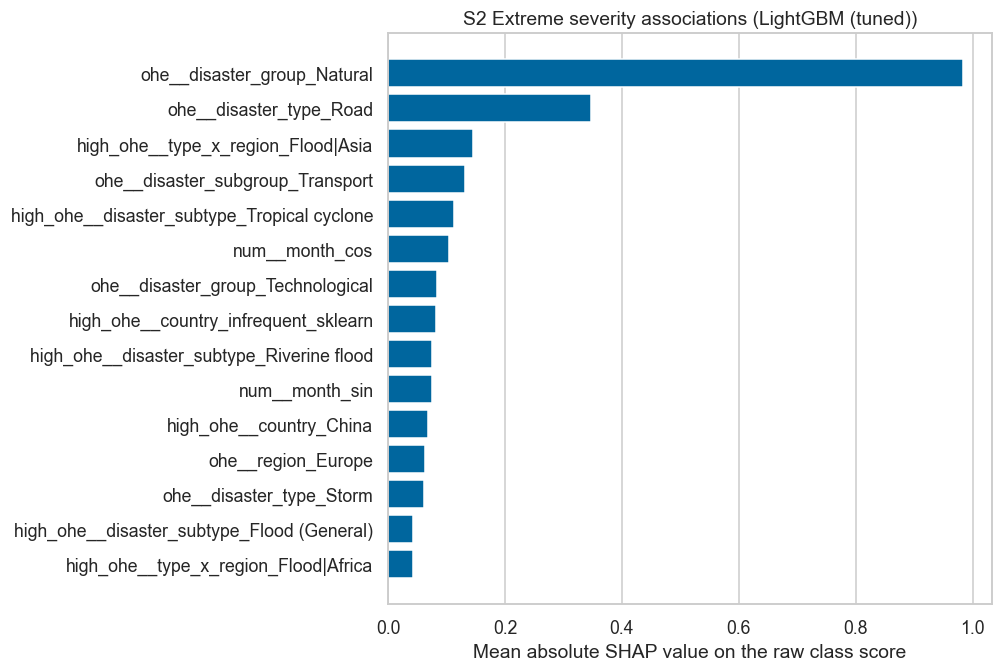

  saved F12_S2_shap.png

SHAP completed: 600 holdout observations for class Extreme.
  saved T14_S2_SHAP_importance.csv

Running shuffled-label diagnostic...



SHUFFLED-LABEL CANARY RESULTS
--------------------------------------------------
Training records: 3480
Holdout records: 2582
Number of classes: 4
Canary accuracy: 0.2727
Canary macro-F1: 0.245
Expected random-prior accuracy: 0.2619
Holdout majority-class share: 0.3284


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,Task,Model,Training records,Holdout records,Classes,Canary accuracy,Canary macro-F1,Expected random-prior accuracy,Holdout majority share,Interpretation
0,S2,LightGBM shuffled-label diagnostic,3480,2582,4,0.272657,0.244971,0.26191,0.328428,Diagnostic only; does not establish absence of...


  saved T14_S2_canary_diagnostic.csv

FEATURE IMPORTANCE AND CANARY DIAGNOSTICS COMPLETED
These diagnostics do not prove that the workflow is leakage-free.


In [24]:
# ============================================================
# CELL 40: FEATURE IMPORTANCE, SHAP AND LEAKAGE CANARY
# Task S2: Two-component severity classification
# ============================================================
print("=" * 75)
print("FEATURE IMPORTANCE, SHAP AND LEAKAGE CANARY")
print("=" * 75)
T = TASKS['S2']
R = RES['S2']
# ------------------------------------------------------------
# 1. Select the explanatory tree model using development scores
# ------------------------------------------------------------
tree_candidates = [
    name for name in R['fitted']
    if name in (
        'XGBoost',
        'LightGBM',
        'LightGBM (tuned)',
        'CatBoost',
        'Random Forest'
    )
]
if not tree_candidates:
    raise ValueError(
        "No fitted tree-based model is available for S2 explanation."
    )
dev_scores = R['table'].set_index('Model')['Dev Macro F1']
tree_candidates = [
    name for name in tree_candidates
    if name in dev_scores.index and np.isfinite(dev_scores[name])
]
if not tree_candidates:
    raise ValueError(
        "No tree model has a valid development macro-F1 score."
    )
selected_explanation_model = max(
    tree_candidates,
    key=lambda name: dev_scores[name]
)
pipe = R['fitted'][selected_explanation_model]
print("Selected explanatory model:", selected_explanation_model)
print("Development macro-F1:", round(
    float(dev_scores[selected_explanation_model]), 4
))
# ------------------------------------------------------------
# 2. Extract transformed feature names
# ------------------------------------------------------------
prep = pipe.named_steps['prep']
mdl = pipe.named_steps['clf']
try:
    feature_names = np.asarray(
        prep.get_feature_names_out(),
        dtype=str
    )
except Exception:
    feature_names = None
# ------------------------------------------------------------
# 3. Calculate model feature importance
# ------------------------------------------------------------
if not hasattr(mdl, 'feature_importances_'):
    raise TypeError(
        f"{selected_explanation_model} does not expose feature_importances_."
    )
importance_values = np.asarray(
    mdl.feature_importances_,
    dtype=float
)
if feature_names is None or len(feature_names) != len(importance_values):
    feature_names = np.array([
        f'feature_{i}'
        for i in range(len(importance_values))
    ])
if not np.isfinite(importance_values).all():
    raise ValueError("Non-finite feature importance values detected.")
importance_sum = importance_values.sum()
if importance_sum > 0:
    importance_values = importance_values / importance_sum
importance = pd.Series(
    importance_values,
    index=feature_names,
    name='importance'
).sort_values(ascending=False)
top_importance = importance.head(25)
print("\nTop 25 features:")
display(top_importance.to_frame())
save_table(
    top_importance.to_frame(),
    'T14_S2_feature_importance.csv'
)
# ------------------------------------------------------------
# 4. Plot feature importance
# ------------------------------------------------------------
fig, ax = plt.subplots(figsize=(10, 8))
top_importance.sort_values().plot.barh(
    ax=ax,
    color=PAL[0]
)
ax.set_title(
    f'S2 feature importance - {selected_explanation_model}',
    fontweight='bold'
)
ax.set_xlabel('Normalised feature importance')
fig.tight_layout()
savefig(
    fig,
    'S2_feature_importance'
)
# ------------------------------------------------------------
# 5. SHAP explanation on a reproducible holdout sample
# ------------------------------------------------------------
if SHAP_OK:
    y_holdout = T['y'][R['te']]
    X_holdout = T['X'].iloc[R['te']]
    if len(X_holdout) == 0:
        raise ValueError("No S2 holdout observations available for SHAP.")
    shap_n = min(
        int(P['shap_n']),
        len(X_holdout)
    )
    rng_shap = np.random.RandomState(SEED)
    shap_indices = np.sort(
        rng_shap.choice(
            len(X_holdout),
            size=shap_n,
            replace=False
        )
    )
    X_shap_raw = X_holdout.iloc[shap_indices]
    # Transform using the already fitted training pipeline
    X_shap = prep.transform(X_shap_raw)
    if hasattr(X_shap, 'toarray'):
        X_shap = X_shap.toarray()
    X_shap = np.asarray(X_shap)
    if X_shap.ndim != 2:
        raise ValueError("Unexpected transformed SHAP input dimensions.")
    if X_shap.shape[1] != len(feature_names):
        raise ValueError(
            "SHAP feature-name count does not match transformed features."
        )
    # Target class: Extreme severity (code 3)
    target_class = 3
    model_classes = np.asarray(mdl.classes_)
    class_positions = np.where(
        model_classes == target_class
    )[0]
    if len(class_positions) == 0:
        print(
            "\nSHAP skipped: the selected model did not learn "
            "the Extreme severity class."
        )
    else:
        class_position = int(class_positions[0])
        explainer = shap.TreeExplainer(mdl)
        shap_output = explainer.shap_values(X_shap)
        # Support different SHAP versions and output formats
        if hasattr(shap_output, 'values'):
            shap_values = shap_output.values
        else:
            shap_values = shap_output
        if isinstance(shap_values, list):
            shap_class = np.asarray(
                shap_values[class_position]
            )
        else:
            shap_values = np.asarray(shap_values)
            if shap_values.ndim == 3:
                if shap_values.shape[-1] == len(model_classes):
                    shap_class = shap_values[:, :, class_position]
                elif shap_values.shape[0] == len(model_classes):
                    shap_class = shap_values[class_position]
                else:
                    raise ValueError(
                        "Cannot identify the SHAP class dimension."
                    )
            elif shap_values.ndim == 2:
                if len(model_classes) == 2:
                    shap_class = shap_values
                else:
                    raise ValueError(
                        "Unexpected two-dimensional SHAP output "
                        "for a multiclass model."
                    )
            else:
                raise ValueError(
                    "Unsupported SHAP output dimensions."
                )
        if shap_class.shape != X_shap.shape:
            raise ValueError(
                f"SHAP shape mismatch: {shap_class.shape} "
                f"versus {X_shap.shape}"
            )
        if not np.isfinite(shap_class).all():
            raise ValueError("Non-finite SHAP values detected.")
        class_name = T['class_names'][target_class]
        shap_ranking = pd.Series(np.abs(shap_class).mean(axis=0), index=feature_names).nlargest(15)
        fig, ax = plt.subplots(figsize=(9, 6), layout='constrained')
        ax.barh(shap_ranking.index[::-1], shap_ranking.values[::-1], color='#00669E')
        ax.set_xlabel('Mean absolute SHAP value on the raw class score')
        ax.set_title(f'S2 Extreme severity associations ({selected_explanation_model})')
        ax.yaxis.grid(False)
        savefig(
            fig,
            'S2_shap'
        )
        print(
            f"\nSHAP completed: {shap_n} holdout observations "
            f"for class {class_name}."
        )
        save_table(
            pd.DataFrame({
                'feature': feature_names,
                'mean_absolute_SHAP': np.abs(shap_class).mean(axis=0)
            }).sort_values(
                'mean_absolute_SHAP',
                ascending=False
            ),
            'T14_S2_SHAP_importance.csv',
            idx=False
        )
else:
    print("\nSHAP unavailable: optional SHAP package is not installed.")
# ------------------------------------------------------------
# 6. Shuffled-label leakage canary
# ------------------------------------------------------------
print("\nRunning shuffled-label diagnostic...")
trc = R['tr']
tec = R['te']
X_train = T['X'].iloc[trc]
X_test = T['X'].iloc[tec]
y_train = T['y'][trc]
y_test = T['y'][tec]
K = R['K']
if len(np.unique(y_train)) < 2:
    raise ValueError(
        "Insufficient training classes for shuffled-label canary."
    )
rng_canary = np.random.RandomState(SEED + 1)
shuffled_y = rng_canary.permutation(y_train)
canary = Pipeline([
    (
        'prep',
        make_prep(
            T['spec'],
            'multiclass'
        )
    ),
    (
        'clf',
        LGBMClassifier(
            n_estimators=P['n_est'],
            random_state=SEED,
            verbose=-1,
            n_jobs=-1
        )
    )
])
canary.fit(
    X_train,
    shuffled_y
)
canary_predictions = canary.predict(X_test)
canary_accuracy = accuracy_score(
    y_test,
    canary_predictions
)
canary_macro_f1 = f1_score(
    y_test,
    canary_predictions,
    labels=np.arange(K),
    average='macro',
    zero_division=0
)
# Expected accuracy from independent random predictions
# using the training and evaluation class proportions
train_prior = np.bincount(
    shuffled_y,
    minlength=K
) / len(shuffled_y)
test_prior = np.bincount(
    y_test,
    minlength=K
) / len(y_test)
expected_random_prior_accuracy = float(
    np.dot(train_prior, test_prior)
)
majority_share = float(
    test_prior.max()
)
print("\nSHUFFLED-LABEL CANARY RESULTS")
print("-" * 50)
print("Training records:", len(trc))
print("Holdout records:", len(tec))
print("Number of classes:", K)
print("Canary accuracy:", round(canary_accuracy, 4))
print("Canary macro-F1:", round(canary_macro_f1, 4))
print(
    "Expected random-prior accuracy:",
    round(expected_random_prior_accuracy, 4)
)
print(
    "Holdout majority-class share:",
    round(majority_share, 4)
)
# ------------------------------------------------------------
# 7. Save diagnostic results
# ------------------------------------------------------------
CANARY_RESULTS = pd.DataFrame([{
    'Task': 'S2',
    'Model': 'LightGBM shuffled-label diagnostic',
    'Training records': len(trc),
    'Holdout records': len(tec),
    'Classes': K,
    'Canary accuracy': canary_accuracy,
    'Canary macro-F1': canary_macro_f1,
    'Expected random-prior accuracy': expected_random_prior_accuracy,
    'Holdout majority share': majority_share,
    'Interpretation': (
        'Diagnostic only; does not establish absence of leakage.'
    )
}])
display(CANARY_RESULTS)
save_table(
    CANARY_RESULTS,
    'T14_S2_canary_diagnostic.csv',
    idx=False
)
print("\n" + "=" * 75)
print("FEATURE IMPORTANCE AND CANARY DIAGNOSTICS COMPLETED")
print("These diagnostics do not prove that the workflow is leakage-free.")
print("=" * 75)

## 17 · Exports, independent re-computation and reproducibility

In [25]:
# ============================================================
# CELL 42: EXPORTS, SPLIT MANIFESTS AND REPRODUCIBILITY
# ============================================================

print("=" * 80)
print("REPRODUCIBILITY AND AUDIT EXPORTS")
print("=" * 80)

# ------------------------------------------------------------
# 1. Ensure output directories exist
# ------------------------------------------------------------

for directory in DIRS.values():
    os.makedirs(directory, exist_ok=True)


# ------------------------------------------------------------
# 2. Export excluded records and exclusion summaries
# ------------------------------------------------------------

excl = pd.DataFrame(
    EXCLUSIONS,
    columns=['task', 'stage', 'dis_no', 'reason']
)

record_lookup = df[
    ['dis_no', 'event_id', 'start_year']
].copy()

excl = excl.merge(
    record_lookup,
    on='dis_no',
    how='left'
)

excl.to_csv(
    os.path.join(DIRS['manifests'], 'excluded_records.csv'),
    index=False
)

excl_sum = (
    excl.groupby(
        ['task', 'stage', 'reason'],
        dropna=False
    )
    .size()
    .rename('n_records')
    .reset_index()
)

display(
    excl_sum[
        ~excl_sum.reason.isin([
            'reference_period_(calibration_only)',
            'class_not_eligible'
        ])
    ].head(40)
)

save_table(
    excl_sum,
    'T15_exclusion_summary.csv',
    idx=False
)


# ------------------------------------------------------------
# 3. Export exact task-specific split manifests
# ------------------------------------------------------------

SPLIT_AUDIT = {}

for key, T in TASKS.items():

    R = RES[key]

    n = len(df)

    role = np.full(
        n,
        'not_in_cohort',
        dtype=object
    )

    task_position = np.full(
        n,
        -1,
        dtype=int
    )

    validation_block = np.full(
        n,
        -1,
        dtype=int
    )

    final_training = np.zeros(
        n,
        dtype=bool
    )

    global_rows = np.asarray(
        T['rows'],
        dtype=int
    )

    train_global = global_rows[R['tr']]
    test_global = global_rows[R['te']]

    # Check task positions
    assert len(np.unique(global_rows)) == len(global_rows)

    assert not np.intersect1d(
        train_global,
        test_global
    ).size, f'{key}: training/holdout record overlap'

    # Check event separation
    train_events = set(
        pd.Series(T['eids'][R['tr']]).dropna()
    )

    test_events = set(
        pd.Series(T['eids'][R['te']]).dropna()
    )

    shared_events = train_events.intersection(
        test_events
    )

    assert not shared_events, (
        f'{key}: {len(shared_events)} shared events '
        'between final training and holdout.'
    )

    # Assign task membership
    role[global_rows] = np.where(
        T['years'] >= TEST_START,
        'holdout',
        'development'
    )

    task_position[global_rows] = np.arange(
        len(global_rows)
    )

    # Development validation blocks
    val_global = global_rows[R['val_idx']]

    assert len(val_global) == len(R['block'])

    validation_block[val_global] = R['block']

    # Final model training membership
    final_training[train_global] = True

    manifest = df[
        ['dis_no', 'event_id', 'start_year']
    ].copy()

    manifest.insert(
        0,
        'df_row_position',
        np.arange(n)
    )

    manifest['task_position'] = task_position
    manifest['role'] = role
    manifest['dev_validation_block'] = validation_block
    manifest['in_final_training_set'] = final_training

    manifest['in_task_cohort'] = (
        task_position >= 0
    )

    manifest.to_csv(
        os.path.join(
            DIRS['manifests'],
            f'split_manifest_{key}.csv'
        ),
        index=False
    )

    SPLIT_AUDIT[key] = {

        'cohort_records': len(global_rows),
        'training_records': len(train_global),
        'holdout_records': len(test_global),
        'training_events': len(train_events),
        'holdout_events': len(test_events),
        'shared_events': len(shared_events),
        'validation_records': len(val_global)

    }


display(
    pd.DataFrame(SPLIT_AUDIT).T
)


# ------------------------------------------------------------
# 4. Export feature dictionary
# ------------------------------------------------------------

fd = []


def addf(f, grp, role, why):

    fd.append({

        'feature': f,
        'group': grp,
        'role': role,

        'derived_from': ','.join(
            sorted(DERIVED_FROM.get(f, {f}))
        ),

        'rationale': why

    })


# Task A primary features
for f in (
    PRIM_A['num'] +
    PRIM_A['low'] +
    PRIM_A['high']
):

    addf(
        f,
        'context (administrative/seasonal)',
        'primary Task A',
        'Contextual descriptor; excludes disaster-type target information.'
    )


# Severity and regression primary features
for f in (
    PRIM_B['num'] +
    PRIM_B['low'] +
    PRIM_B['high']
):

    addf(
        f,
        'context and event descriptors',
        'primary S2, S3 and regression',
        'Recorded event descriptor; target-specific exclusions are enforced.'
    )


# Sensitivity groups
for group_name, group_cols in GROUP_COLS.items():

    for f in (
        group_cols.get('num', []) +
        group_cols.get('low', []) +
        group_cols.get('high', [])
    ):

        addf(
            f,
            f'sensitivity: {group_name}',
            'sensitivity only',
            'Availability at prediction time is not established.'
        )


# Historical features
for prefix in [
    'hcA_*',
    'hsA_*',
    'hc_*',
    'hct_*',
    'ht_*',
    'hst_*'
]:

    addf(
        prefix,
        'outcome-based historical features',
        'retrospective sensitivity only',
        'Constructed from eligible training records; not part of primary models.'
    )


feat_dict = pd.DataFrame(fd).drop_duplicates()

feat_dict.to_csv(
    os.path.join(
        DIRS['reproducibility'],
        'feature_dictionary.csv'
    ),
    index=False
)

display(feat_dict.head(15))


# ------------------------------------------------------------
# 5. Export exact task-specific historical feature states
# ------------------------------------------------------------

HISTORY_EXPORTS = {}

for key, T in TASKS.items():

    R = RES[key]

    print(f'\nExporting historical features: {key}')

    # Exact final training and holdout rows
    fit_global = np.asarray(
        T['rows'][R['tr']],
        dtype=int
    )

    app_global = np.asarray(
        T['rows'][R['te']],
        dtype=int
    )

    dfit = df.iloc[fit_global].copy()
    dapp = df.iloc[app_global].copy()

    # Check event separation
    fit_events = set(
        dfit.event_id.dropna()
    )

    app_events = set(
        dapp.event_id.dropna()
    )

    overlap = fit_events.intersection(
        app_events
    )

    if overlap:
        raise AssertionError(
            f'{key}: shared events detected in history export.'
        )

    # Select the appropriate historical feature specification
    if key == 'A':

        history_kind = 'A'

        history_specs = [

            (['country'], IND_COLS, 'hcA'),

            (['subregion'], IND_COLS, 'hsA')

        ]

    else:

        history_kind = 'B'

        history_specs = [

            (['country'], LOGS, 'hc'),

            (
                ['country', 'disaster_type'],
                LOGS,
                'hct'
            ),

            (['disaster_type'], LOGS, 'ht'),

            (
                ['subregion', 'disaster_type'],
                LOGS,
                'hst'
            )

        ]

    # --------------------------------------------------------
    # Reconstruct the exact historical feature matrices
    # --------------------------------------------------------

    Hf, Ha = hist_frames(
        df,
        fit_global,
        app_global,
        history_kind
    )

    Hf = Hf.reset_index(drop=True)
    Ha = Ha.reset_index(drop=True)

    assert len(Hf) == len(fit_global)
    assert len(Ha) == len(app_global)

    assert list(Hf.columns) == list(Ha.columns)

    # --------------------------------------------------------
    # Export training history features
    # --------------------------------------------------------

    fit_ids = df.iloc[fit_global][
        ['dis_no', 'event_id', 'start_year']
    ].reset_index(drop=True)

    fit_ids.insert(
        0,
        'df_row_position',
        fit_global
    )

    fit_history_export = pd.concat(
        [fit_ids, Hf],
        axis=1
    )

    fit_file = f'history_features_train_{key}.csv'

    fit_history_export.to_csv(
        os.path.join(
            DIRS['reproducibility'],
            fit_file
        ),
        index=False
    )

    # --------------------------------------------------------
    # Export holdout history features
    # --------------------------------------------------------

    app_ids = df.iloc[app_global][
        ['dis_no', 'event_id', 'start_year']
    ].reset_index(drop=True)

    app_ids.insert(
        0,
        'df_row_position',
        app_global
    )

    app_history_export = pd.concat(
        [app_ids, Ha],
        axis=1
    )

    app_file = f'history_features_holdout_{key}.csv'

    app_history_export.to_csv(
        os.path.join(
            DIRS['reproducibility'],
            app_file
        ),
        index=False
    )

    # --------------------------------------------------------
    # Export the exact source records used to construct history
    # --------------------------------------------------------

    source_columns = [
        'dis_no',
        'event_id',
        'start_year'
    ]

    for keys, values, prefix in history_specs:

        source_columns += (
            keys + values
        )

    source_columns = list(
        dict.fromkeys(source_columns)
    )

    fit_source = dfit[
        source_columns
    ].copy()

    fit_source.insert(
        0,
        'df_row_position',
        fit_global
    )

    source_file = f'history_fit_source_{key}.csv'

    fit_source.to_csv(
        os.path.join(
            DIRS['reproducibility'],
            source_file
        ),
        index=False
    )

    # --------------------------------------------------------
    # Save exact history specification
    # --------------------------------------------------------

    history_metadata = {

        'task': key,

        'history_kind': history_kind,

        'construction': (
            'Strictly earlier calendar years; '
            'same disaster event excluded.'
        ),

        'application_source': (
            'Final training partition only; '
            'holdout outcomes are not used.'
        ),

        'training_records': len(fit_global),

        'holdout_records': len(app_global),

        'training_year_min': int(dfit.start_year.min()),

        'training_year_max': int(dfit.start_year.max()),

        'holdout_year_min': int(dapp.start_year.min()),

        'holdout_year_max': int(dapp.start_year.max()),

        'training_unique_events': len(fit_events),

        'holdout_unique_events': len(app_events),

        'shared_events': len(overlap),

        'training_missing_event_ids': int(dfit.event_id.isna().sum()),

        'holdout_missing_event_ids': int(dapp.event_id.isna().sum()),

        'feature_specs': [

            {

                'keys': keys,

                'values': values,

                'prefix': prefix

            }

            for keys, values, prefix in history_specs

        ],

        'feature_columns': list(Hf.columns),

        'files': {

            'training_features': fit_file,

            'holdout_features': app_file,

            'training_source': source_file

        }

    }

    meta_file = f'history_specification_{key}.json'

    with open(
        os.path.join(
            DIRS['reproducibility'],
            meta_file
        ),
        'w',
        encoding='utf-8'
    ) as f:

        json.dump(
            history_metadata,
            f,
            indent=2,
            default=str
        )

    HISTORY_EXPORTS[key] = {

        'training_features': fit_file,

        'holdout_features': app_file,

        'training_source': source_file,

        'specification': meta_file

    }

    print(
        f'  Training: {len(Hf):,} | '
        f'Holdout: {len(Ha):,} | '
        f'History features: {Hf.shape[1]}'
    )


# ------------------------------------------------------------
# 6. Export Task A historical indicator mapping
# ------------------------------------------------------------

indicator_map = dict(
    zip(
        IND_COLS,
        TOP_TYPES
    )
)

with open(
    os.path.join(
        DIRS['reproducibility'],
        'history_indicator_map.json'
    ),
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        indicator_map,
        f,
        indent=2,
        default=str
    )


# ------------------------------------------------------------
# 7. Export severity calibration specification
# ------------------------------------------------------------

severity_state = {

    key: cal.to_dict()

    for key, cal in CAL.items()

}

with open(
    os.path.join(
        DIRS['reproducibility'],
        'severity_calibration.json'
    ),
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        severity_state,
        f,
        indent=2,
        default=str
    )


# ------------------------------------------------------------
# 8. Record software environment
# ------------------------------------------------------------

packages = {}

package_names = [

    'numpy',
    'pandas',
    'scikit-learn',
    'xgboost',
    'lightgbm',
    'catboost',
    'matplotlib',
    'seaborn',
    'joblib',
    'openpyxl',
    'shap',
    'scipy',
    'ipython',
    'ipykernel',
    'nbformat',
    'nbclient'

]

for package in package_names:

    try:

        packages[package] = metadata.version(
            package
        )

    except metadata.PackageNotFoundError:

        packages[package] = 'not installed'


# ------------------------------------------------------------
# 9. Export complete run configuration
# ------------------------------------------------------------

cfg = {

    'notebook_version': NOTEBOOK_VERSION,

    'profile': PROFILE,

    'profile_settings': P,

    'random_seed': SEED,

    'dataset_sha256': DATA_SHA256,

    'n_records': len(df),

    'n_unique_events': int(df.event_id.nunique()),

    'reference_end': REF_END,

    'development_end': TRAIN_END,

    'holdout_start': TEST_START,

    'cv_folds_all': CV_FOLDS_ALL,

    'cv_folds_severity': CV_FOLDS_SEV,

    'minimum_development_class': MIN_DEV_CLASS,

    'minimum_first_window_class': MIN_FIRST_WINDOW,

    'retained_classes_A': list(CLASSES_A),

    'severity_specifications': SEV_SPECS,

    'task_split_audit': SPLIT_AUDIT,

    'historical_feature_exports': HISTORY_EXPORTS,

    'selected_models': {

        key: RES[key].get('best')

        for key in TASKS

    },

    'voting_members': {

        key: RES[key].get('vote_members', [])

        for key in TASKS

    },

    'stacking_members': {

        key: RES[key].get('stack_members', [])

        for key in TASKS

    },

    'python_version': sys.version,

    'platform': platform.platform(),
    'protocol_comparison': 'Untuned LightGBM; temporal versus random event groups',
    'outcome_holdout_years': {
        key: sorted(int(year) for year in np.unique(TASKS[key]['years'][RES[key]['te']]))
        for key in TASKS
    },

    'packages': packages,

    'executed': datetime.datetime.now().isoformat(
        timespec='seconds'
    )

}


with open(
    os.path.join(
        DIRS['reproducibility'],
        'configuration.json'
    ),
    'w',
    encoding='utf-8'
) as f:

    json.dump(
        cfg,
        f,
        indent=2,
        default=str
    )


# ------------------------------------------------------------
# 10. Final export verification
# ------------------------------------------------------------

required_files = [

    'feature_dictionary.csv',

    'history_indicator_map.json',

    'severity_calibration.json',

    'configuration.json'

]

for filename in required_files:

    path = os.path.join(
        DIRS['reproducibility'],
        filename
    )

    assert os.path.exists(path), (
        f'Missing reproducibility export: {filename}'
    )


for key in TASKS:

    for filename in HISTORY_EXPORTS[key].values():

        path = os.path.join(
            DIRS['reproducibility'],
            filename
        )

        assert os.path.exists(path), (
            f'Missing history artifact: {filename}'
        )


print("\n" + "=" * 80)
print("REPRODUCIBILITY EXPORTS COMPLETED")
print("=" * 80)

print("Tasks exported:", len(TASKS))

print(
    "Task-specific historical feature exports:",
    len(HISTORY_EXPORTS)
)

print(
    "Dataset SHA-256:",
    DATA_SHA256
)

print(
    "Execution profile:",
    PROFILE
)

print(
    "Reproducibility directory:",
    DIRS['reproducibility']
)

print(
    "\nNOTE: These historical features belong to the retrospective "
    "sensitivity analysis. They are not primary model predictors."
)

print("=" * 80)

REPRODUCIBILITY AND AUDIT EXPORTS


,task,stage,reason,n_records
1,A,dev_block0,shared_event_with_validation_block,2
2,A,dev_block1,shared_event_with_validation_block,1
3,A,stack_meta_block1,shared_event_with_stacking_evaluation_block,1
4,C_log_affected,dev_block1,shared_event_with_validation_block,1
5,C_log_affected,stack_meta_block1,shared_event_with_stacking_evaluation_block,1
6,C_log_deaths,dev_block0,shared_event_with_validation_block,2


  saved T15_exclusion_summary.csv


,cohort_records,training_records,holdout_records,training_events,holdout_events,shared_events,validation_records
A,16557,12031,4526,10887,3869,0,4573
S2,6062,3480,2582,3258,2407,0,1940
S3,1503,965,538,899,509,0,647
C_log_deaths,13442,9900,3542,9221,3123,0,3738
C_log_affected,12473,9041,3432,8429,3133,0,3425
C_log_damage,3238,2432,806,2140,741,0,1150


,feature,group,role,derived_from,rationale
0,month_sin,context (administrative/seasonal),primary Task A,start_month,Contextual descriptor; excludes disaster-type ...
1,month_cos,context (administrative/seasonal),primary Task A,start_month,Contextual descriptor; excludes disaster-type ...
2,region,context (administrative/seasonal),primary Task A,region,Contextual descriptor; excludes disaster-type ...
3,subregion,context (administrative/seasonal),primary Task A,subregion,Contextual descriptor; excludes disaster-type ...
4,country,context (administrative/seasonal),primary Task A,country,Contextual descriptor; excludes disaster-type ...
5,month_sin,context and event descriptors,"primary S2, S3 and regression",start_month,Recorded event descriptor; target-specific exc...
6,month_cos,context and event descriptors,"primary S2, S3 and regression",start_month,Recorded event descriptor; target-specific exc...
7,region,context and event descriptors,"primary S2, S3 and regression",region,Recorded event descriptor; target-specific exc...
8,disaster_group,context and event descriptors,"primary S2, S3 and regression",disaster_group,Recorded event descriptor; target-specific exc...
9,disaster_subgroup,context and event descriptors,"primary S2, S3 and regression",disaster_subgroup,Recorded event descriptor; target-specific exc...



Exporting historical features: A


  Training: 12,031 | Holdout: 4,526 | History features: 18

Exporting historical features: S2


  Training: 3,480 | Holdout: 2,582 | History features: 16

Exporting historical features: S3
  Training: 965 | Holdout: 538 | History features: 16

Exporting historical features: C_log_deaths


  Training: 9,900 | Holdout: 3,542 | History features: 16

Exporting historical features: C_log_affected


  Training: 9,041 | Holdout: 3,432 | History features: 16

Exporting historical features: C_log_damage


  Training: 2,432 | Holdout: 806 | History features: 16

REPRODUCIBILITY EXPORTS COMPLETED
Tasks exported: 6
Task-specific historical feature exports: 6
Dataset SHA-256: d1e873e53071fffe9264f81a40b2673b0785c6b032601ca177426d27808ce1d6
Execution profile: full
Reproducibility directory: outputs_v5_full\reproducibility

NOTE: These historical features belong to the retrospective sensitivity analysis. They are not primary model predictors.


In [26]:

# ============================================================
# CELL 43: INDEPENDENT RESULT RE-COMPUTATION AND MODEL RELOAD
#
# Verifies:
# 1. Saved prediction-file integrity and record alignment
# 2. Classification metrics and confusion matrices
# 3. Regression metrics on log and original scales
# 4. Saved probability matrices
# 5. Saved best-model artifact
# 6. Saved voting and stacking model bundles
# ============================================================

print("=" * 85)
print("INDEPENDENT RESULT VERIFICATION")
print("=" * 85)

VERIFY_RESULTS = []
n_checked = 0


# ------------------------------------------------------------
# 1. Verification helper functions
# ------------------------------------------------------------

def verify_close(actual, expected, label, atol=1e-7, rtol=1e-7):

    if not np.isfinite(actual) or not np.isfinite(expected):
        raise AssertionError(
            f"{label}: non-finite value detected."
        )

    if not np.isclose(actual, expected, atol=atol, rtol=rtol):
        raise AssertionError(
            f"{label}: expected {expected}, obtained {actual}."
        )


def verify_array(actual, expected, label, atol=1e-8, rtol=1e-8):

    actual = np.asarray(actual)
    expected = np.asarray(expected)

    if actual.shape != expected.shape:
        raise AssertionError(
            f"{label}: shape mismatch "
            f"{actual.shape} versus {expected.shape}."
        )

    if not np.isfinite(actual).all():
        raise AssertionError(
            f"{label}: non-finite values detected."
        )

    if not np.isfinite(expected).all():
        raise AssertionError(
            f"{label}: expected values contain non-finite entries."
        )

    np.testing.assert_allclose(
        actual,
        expected,
        atol=atol,
        rtol=rtol,
        err_msg=label
    )


def verify_ids(actual, expected, label):

    actual = pd.Series(actual).reset_index(drop=True)
    expected = pd.Series(expected).reset_index(drop=True)

    if len(actual) != len(expected):
        raise AssertionError(
            f"{label}: record counts differ."
        )

    a_num = pd.to_numeric(actual, errors='coerce')
    e_num = pd.to_numeric(expected, errors='coerce')

    if a_num.notna().all() and e_num.notna().all():

        if not np.allclose(
            a_num.to_numpy(dtype=float),
            e_num.to_numpy(dtype=float),
            equal_nan=True
        ):
            raise AssertionError(
                f"{label}: record identifiers do not match."
            )

    else:

        a_str = actual.astype('string').fillna('<MISSING>')
        e_str = expected.astype('string').fillna('<MISSING>')

        if not a_str.equals(e_str):
            raise AssertionError(
                f"{label}: record identifiers do not match."
            )


# ------------------------------------------------------------
# 2. Verify every task
# ------------------------------------------------------------

for key, T in TASKS.items():

    print(f"\n{'-' * 75}")
    print(f"VERIFYING TASK: {key}")
    print('-' * 75)

    R = RES[key]

    prediction_file = os.path.join(
        DIRS['predictions'],
        f'holdout_predictions_{key}.csv'
    )

    if not os.path.exists(prediction_file):
        raise FileNotFoundError(
            f"Missing prediction file: {prediction_file}"
        )

    pf = pd.read_csv(prediction_file)

    tb = R['table'].set_index('Model')

    te = R['te']
    best = R['best']
    K = R['K']

    # --------------------------------------------------------
    # 3. Verify holdout record alignment
    # --------------------------------------------------------

    expected_n = len(te)

    if len(pf) != expected_n:
        raise AssertionError(
            f"{key}: saved prediction row count "
            f"{len(pf)} != expected {expected_n}."
        )

    required_id_columns = [
        'dis_no',
        'event_id',
        'start_year',
        'y_true'
    ]

    missing_columns = [
        c for c in required_id_columns
        if c not in pf.columns
    ]

    if missing_columns:
        raise AssertionError(
            f"{key}: missing columns {missing_columns}."
        )

    verify_ids(
        pf['dis_no'],
        T['dis_no'][te],
        f'{key}: disaster record IDs'
    )

    verify_ids(
        pf['event_id'],
        T['eids'][te],
        f'{key}: event IDs'
    )

    verify_array(
        pd.to_numeric(pf['start_year']).to_numpy(),
        T['years'][te],
        f'{key}: start years',
        atol=0,
        rtol=0
    )

    print("PASSED: Holdout record alignment.")

    # --------------------------------------------------------
    # 4. Classification verification
    # --------------------------------------------------------

    if T['kind'] == 'clf':

        # FIX: NumPy array is required for array-based indexing.
        names = np.asarray(
            T['class_names'],
            dtype=object
        )

        if len(names) != K:
            raise AssertionError(
                f"{key}: class-name count does not match K."
            )

        if len(set(map(str, names))) != K:
            raise AssertionError(
                f"{key}: duplicate class labels detected."
            )

        class_to_idx = {
            str(name): i
            for i, name in enumerate(names)
        }

        yi_series = (
            pf['y_true']
            .astype('string')
            .map(class_to_idx)
        )

        if yi_series.isna().any():
            raise AssertionError(
                f"{key}: unknown class in saved true labels."
            )

        yi = yi_series.to_numpy(dtype=int)

        verify_array(
            yi,
            T['y'][te],
            f'{key}: true classification labels',
            atol=0,
            rtol=0
        )

        if best not in R['test']:
            raise AssertionError(
                f"{key}: selected model missing from test predictions."
            )

        # Verify every saved model's predictions and metrics
        for n in R['test']:

            pred_column = f'pred__{n}'

            if pred_column not in pf.columns:
                raise AssertionError(
                    f"{key}/{n}: missing saved prediction column."
                )

            pi_series = (
                pf[pred_column]
                .astype('string')
                .map(class_to_idx)
            )

            if pi_series.isna().any():
                raise AssertionError(
                    f"{key}/{n}: unknown predicted class."
                )

            pi = pi_series.to_numpy(dtype=int)

            # ------------------------------------------------
            # FIXED CLASS-LABEL INDEXING
            # ------------------------------------------------

            expected_pred = names[
                np.asarray(R['test'][n]).argmax(axis=1)
            ]

            verify_ids(
                pf[pred_column],
                expected_pred,
                f'{key}/{n}: saved versus in-memory predictions'
            )

            # Recalculate classification metrics
            acc, macro_f1, balanced_acc = clf_fast(
                yi,
                pi,
                K
            )

            verify_close(
                acc,
                tb.loc[n, 'Test Acc'],
                f'{key}/{n}: accuracy'
            )

            verify_close(
                macro_f1,
                tb.loc[n, 'Test Macro F1'],
                f'{key}/{n}: macro-F1'
            )

            verify_close(
                balanced_acc,
                tb.loc[n, 'Test Bal Acc'],
                f'{key}/{n}: balanced accuracy'
            )

            n_checked += 3

            VERIFY_RESULTS.append({

                'Task': key,
                'Model': n,
                'Check': 'Classification metrics',
                'Status': 'PASSED',
                'Records': expected_n

            })

        # ----------------------------------------------------
        # 5. Verify best-model probability matrix
        # ----------------------------------------------------

        probability_columns = [
            f'proba__{best}__{c}'
            for c in names
        ]

        missing_prob = [
            c for c in probability_columns
            if c not in pf.columns
        ]

        if missing_prob:
            raise AssertionError(
                f"{key}: missing probability columns {missing_prob}."
            )

        prob = pf[
            probability_columns
        ].to_numpy(dtype=float)

        if not np.isfinite(prob).all():
            raise AssertionError(
                f"{key}: non-finite probabilities."
            )

        if np.any(prob < -1e-10):
            raise AssertionError(
                f"{key}: negative probabilities detected."
            )

        verify_array(
            prob.sum(axis=1),
            np.ones(len(prob)),
            f'{key}: probability row sums',
            atol=1e-6
        )

        verify_array(
            prob,
            R['test'][best],
            f'{key}: saved versus in-memory probabilities',
            atol=1e-7,
            rtol=1e-7
        )

        verify_array(
            prob.argmax(axis=1),
            R['test'][best].argmax(axis=1),
            f'{key}: best-model probability predictions',
            atol=0,
            rtol=0
        )

        n_checked += 2

        # ----------------------------------------------------
        # 6. Verify confusion matrix
        # ----------------------------------------------------

        cm_recomputed = confusion_matrix(
            yi,
            pi_series.map(class_to_idx).to_numpy(dtype=int)
            if False else
            pf[f'pred__{best}'].astype('string')
            .map(class_to_idx).to_numpy(dtype=int),
            labels=np.arange(K)
        )

        verify_array(
            cm_recomputed,
            R['cm'],
            f'{key}: confusion matrix',
            atol=0,
            rtol=0
        )

        n_checked += 1

        print("PASSED: Classification metrics.")
        print("PASSED: Probability matrices.")
        print("PASSED: Confusion matrix.")

    # --------------------------------------------------------
    # 7. Regression verification
    # --------------------------------------------------------

    else:

        y_true = pd.to_numeric(
            pf['y_true'],
            errors='coerce'
        ).to_numpy(dtype=float)

        verify_array(
            y_true,
            T['y'][te],
            f'{key}: true regression outcomes'
        )

        for n in R['test']:

            pred_column = f'pred__{n}'

            if pred_column not in pf.columns:
                raise AssertionError(
                    f"{key}/{n}: missing prediction column."
                )

            predictions = pd.to_numeric(
                pf[pred_column],
                errors='coerce'
            ).to_numpy(dtype=float)

            if not np.isfinite(predictions).all():
                raise AssertionError(
                    f"{key}/{n}: non-finite predictions."
                )

            
            # Allow minor float32-to-float64 CSV serialization differences
            verify_array(
                predictions,
                R['test'][n],
                f'{key}/{n}: saved predictions',
                atol=1e-7,
                rtol=1e-6
            )
            m = reg_metrics(
                y_true,
                predictions
            )

            y_original = inv(y_true)
            p_original = inv(predictions)

            o = reg_metrics(
                y_original,
                p_original
            )

            medae_original = median_absolute_error(
                y_original,
                p_original
            )

            checks = {

                'Test RMSE (log)': m['RMSE'],

                'Test MAE (log)': m['MAE'],

                'Test R2 (log)': m['R2'],

                'Test MAE (orig)': o['MAE'],

                'Test RMSE (orig)': o['RMSE'],

                'Test MedAE (orig)': medae_original

            }

            

            
            for metric, value in checks.items():

                # Original-scale metrics can amplify tiny prediction
                # serialization differences through the expm1 transformation.
                if '(orig)' in metric:

                     verify_close(
                        value,
                        tb.loc[n, metric],
                        f'{key}/{n}: {metric}',
                        atol=1e-6,
                        rtol=1e-6
                    )

                else:

                    # Keep log-scale metric verification stricter.
                    verify_close(
                        value,
                        tb.loc[n, metric],
                        f'{key}/{n}: {metric}',
                        atol=1e-7,
                        rtol=1e-7
                    )

                    n_checked += 1

            
            VERIFY_RESULTS.append({

                'Task': key,
                'Model': n,
                'Check': 'Regression metrics',
                'Status': 'PASSED',
                'Records': expected_n

            })

        print("PASSED: Log-scale regression metrics.")
        print("PASSED: Original-scale regression metrics.")

    # --------------------------------------------------------
    # 8. Verify saved best-model artifact
    # --------------------------------------------------------

    best_filename = (
        f'best_model_{key}__'
        f'{re.sub(r"[^A-Za-z0-9]+", "_", best)}.pkl'
    )

    best_path = os.path.join(
        DIRS['models'],
        best_filename
    )

    if not os.path.exists(best_path):
        raise FileNotFoundError(
            f"{key}: missing best-model artifact: {best_path}"
        )

    saved_best = joblib.load(best_path)

    X_holdout = T['X'].iloc[te]

    if T['kind'] == 'clf':

        best_predictions = saved_best.predict_proba(
            X_holdout
        )

    else:

        best_predictions = saved_best.predict(
            X_holdout
        )

    verify_array(
        best_predictions,
        R['test'][best],
        f'{key}: saved best-model artifact'
    )

    n_checked += 1

    VERIFY_RESULTS.append({

        'Task': key,
        'Model': best,
        'Check': 'Saved best-model reload',
        'Status': 'PASSED',
        'Records': expected_n

    })

    print(f"PASSED: Saved best-model artifact ({best}).")

    # --------------------------------------------------------
    # 9. Verify voting and stacking bundles
    # --------------------------------------------------------

    ensemble_path = os.path.join(
        DIRS['models'],
        f'ensembles_{key}.pkl'
    )

    if not os.path.exists(ensemble_path):
        raise FileNotFoundError(
            f"{key}: missing ensemble bundle: {ensemble_path}"
        )

    saved_ensembles = joblib.load(
        ensemble_path
    )

    expected_ensemble_names = sorted([

        n for n in R['models']

        if n.startswith(('Soft', 'Stacking'))

    ])

    saved_ensemble_names = sorted(
        saved_ensembles.keys()
    )

    if saved_ensemble_names != expected_ensemble_names:
        raise AssertionError(
            f"{key}: ensemble bundle mismatch. "
            f"Expected {expected_ensemble_names}; "
            f"found {saved_ensemble_names}."
        )

    for n, mdl in saved_ensembles.items():

        if T['kind'] == 'clf':

            reloaded_predictions = mdl.predict_proba(
                X_holdout
            )

        else:

            reloaded_predictions = mdl.predict(
                X_holdout
            )

        verify_array(
            reloaded_predictions,
            R['test'][n],
            f'{key}/{n}: reloaded ensemble predictions'
        )

        if T['kind'] == 'clf':

            expected_labels = names[
                reloaded_predictions.argmax(axis=1)
            ]

            verify_ids(
                pf[f'pred__{n}'],
                expected_labels,
                f'{key}/{n}: ensemble CSV predictions'
            )

        else:

            verify_array(
                pf[f'pred__{n}'].to_numpy(dtype=float),
                reloaded_predictions,
                f'{key}/{n}: ensemble CSV predictions'
            )

        n_checked += 1

        VERIFY_RESULTS.append({

            'Task': key,
            'Model': n,
            'Check': 'Saved ensemble reload',
            'Status': 'PASSED',
            'Records': expected_n

        })

    print(
        f"PASSED: {len(saved_ensembles)} saved ensemble objects."
    )


# ------------------------------------------------------------
# 10. Export verification summary
# ------------------------------------------------------------

verification_table = pd.DataFrame(
    VERIFY_RESULTS
)

display(
    verification_table
)

save_table(
    verification_table,
    'T16_independent_verification.csv',
    idx=False
)

assert (
    verification_table['Status'] == 'PASSED'
).all()

assert len(verification_table) > 0

print("\n" + "=" * 85)
print("INDEPENDENT VERIFICATION COMPLETED")
print("=" * 85)

print("Tasks verified:", len(TASKS))
print("Total numerical and structural checks:", n_checked)
print("Verification records:", len(verification_table))

print(
    "Saved predictions, metrics, confusion matrices, "
    "best-model artifacts and ensemble bundles were checked."
)

print(
    "\nNOTE: Model reload checks are serialization round-trip "
    "checks within this notebook execution. A separate fresh-process "
    "test is still required for full environment-independent reproducibility."
)

print(
    "These checks do not prove the absence of every possible leakage path."
)

print("=" * 85)


INDEPENDENT RESULT VERIFICATION

---------------------------------------------------------------------------
VERIFYING TASK: A
---------------------------------------------------------------------------
PASSED: Holdout record alignment.
PASSED: Classification metrics.
PASSED: Probability matrices.
PASSED: Confusion matrix.


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


PASSED: Saved best-model artifact (LightGBM (tuned)).


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


... (12 outputs left out)

C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(
C:\Users\Jarvice\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\sklearn\utils\validation.py:2691: UserWarning: X does not have valid feature names, but LGBMRegressor was fitted with feature names
  warnings.warn(


PASSED: 2 saved ensemble objects.


,Task,Model,Check,Status,Records
0,A,Logistic Regression,Classification metrics,PASSED,4526
1,A,Random Forest,Classification metrics,PASSED,4526
2,A,XGBoost,Classification metrics,PASSED,4526
3,A,LightGBM,Classification metrics,PASSED,4526
4,A,CatBoost,Classification metrics,PASSED,4526
5,A,LightGBM (tuned),Classification metrics,PASSED,4526
6,A,Soft Voting (top-3),Classification metrics,PASSED,4526
7,A,Stacking (chronological meta-learner),Classification metrics,PASSED,4526
8,A,LightGBM (tuned),Saved best-model reload,PASSED,4526
9,A,Soft Voting (top-3),Saved ensemble reload,PASSED,4526


  saved T16_independent_verification.csv

INDEPENDENT VERIFICATION COMPLETED
Tasks verified: 6
Total numerical and structural checks: 171
Verification records: 66
Saved predictions, metrics, confusion matrices, best-model artifacts and ensemble bundles were checked.

NOTE: Model reload checks are serialization round-trip checks within this notebook execution. A separate fresh-process test is still required for full environment-independent reproducibility.
These checks do not prove the absence of every possible leakage path.


## 18 · Final report, limitations and status

In [27]:
# ============================================================
# CELL 45: FINAL REPORT GENERATOR
# EM-DAT Disaster Impact Analysis — Revised v5
# ============================================================

print("=" * 92)
print("GENERATING FINAL ANALYSIS REPORT")
print("=" * 92)


# ------------------------------------------------------------
# 1. Helper functions
# ------------------------------------------------------------

def best_row(key):
    R = RES[key]
    return (
        R['table']
        .set_index('Model')
        .loc[R['best']]
    )


def safe_value(value, digits=3):

    if pd.isna(value):
        return 'NA'

    if isinstance(value, (int, float, np.integer, np.floating)):
        return f'{value:.{digits}f}'

    return str(value)


def require_columns(frame, columns, label):

    missing = [
        c for c in columns
        if c not in frame.columns
    ]

    if missing:
        raise ValueError(
            f'{label}: missing required columns {missing}'
        )


# ------------------------------------------------------------
# 2. Validate report prerequisites
# ------------------------------------------------------------

required_tasks = [
    'A',
    'S2',
    'S3',
    'C_log_deaths',
    'C_log_affected',
    'C_log_damage'
]

missing_tasks = [
    k for k in required_tasks
    if k not in RES or k not in TASKS
]

if missing_tasks:
    raise RuntimeError(
        f'Cannot generate complete report. Missing tasks: {missing_tasks}'
    )

if not os.path.isdir(DIRS['reports']):
    os.makedirs(DIRS['reports'], exist_ok=True)


# ------------------------------------------------------------
# 3. Report metadata
# ------------------------------------------------------------

L = []

L.extend([

    '=' * 92,

    'EM-DAT DISASTER IMPACT ANALYSIS',

    f'REVISED SPECIFICATION {NOTEBOOK_VERSION.upper()}',

    'FINAL ANALYSIS AND VERIFICATION REPORT',

    '=' * 92,

    f'Generated: {datetime.datetime.now().isoformat(timespec="seconds")}',

    f'Execution profile: {PROFILE.upper()}',

    f'Dataset: {os.path.basename(DATA_FILE)}',

    f'Dataset SHA-256: {DATA_SHA256}',

    f'Total event-country records: {len(df):,}',

    f'Unique disaster events: {df.event_id.nunique():,}',

    '',

    'EXECUTION STATUS',

    '-' * 70,

])

if PROFILE == 'full':

    L.append(
        'FULL PROFILE selected. Publication use remains conditional on '
        'successful completion of all checks and review of the final outputs.'
    )

else:

    L.append(
        f'{PROFILE.upper()} PROFILE selected. These results are provisional '
        'and must not be presented as final publication results. '
        'Run PROFILE = "full" using the frozen specification.'
    )


# ------------------------------------------------------------
# 4. Evaluation protocol
# ------------------------------------------------------------

L.extend([

    '',

    'EVALUATION PROTOCOL',

    '-' * 70,

    f'Severity reference period: 2000–{REF_END}',

    f'Development period: through {TRAIN_END}',

    f'Temporal split begins: {TEST_START}',
    'Each task uses its observed outcome years. S3 and adjusted damage end in 2024 for this snapshot.',

    'Final models are selected with development scores. Holdout estimates '
    'describe the fixed retrospective benchmark.',

    'Shared disaster events are purged from relevant training/evaluation '
    'partitions.',

    'Primary models use conservative contextual descriptors.',

    'Outcome-derived historical features are treated separately as '
    'retrospective sensitivity features.',

    'The analysis is retrospective. It is not a prospective forecasting '
    'experiment.',

    ''

])


# ------------------------------------------------------------
# 5. Task A, S2 and S3 classification results
# ------------------------------------------------------------

L.extend([

    '=' * 92,

    'CLASSIFICATION RESULTS',

    '=' * 92

])

for key in ['A', 'S2', 'S3']:

    R = RES[key]

    T = TASKS[key]

    r = best_row(key)

    tb = R['table'].set_index('Model')

    baseline_name = 'Majority-class baseline'

    if baseline_name not in tb.index:
        raise ValueError(
            f'{key}: majority-class baseline missing.'
        )

    baseline = tb.loc[baseline_name]

    L.extend([

        '',

        T['title'],

        '-' * 70,

        f'Retained classes: {R["K"]}',

        f'Total cohort records: {len(T["rows"]):,}',

        f'Training records: {len(R["tr"]):,}',

        f'Holdout records: {len(R["te"]):,}',

        f'Selected model: {R["best"]}',

        'Selection basis: development-period validation score.',

        '',

        'Selected model — temporal holdout:',

        f'  Accuracy: {r["Test Acc"]:.4f} '
        f'({r["Test Acc 95% CI"]})',

        f'  Macro-F1: {r["Test Macro F1"]:.4f} '
        f'({r["Test Macro F1 95% CI"]})',

        f'  Balanced accuracy: {r["Test Bal Acc"]:.4f} '
        f'({r["Test Bal Acc 95% CI"]})',

        f'  Log loss: {r["Test Log loss"]:.4f}',

        '',

        'Majority-class baseline:',

        f'  Accuracy: {baseline["Test Acc"]:.4f}',

        f'  Macro-F1: {baseline["Test Macro F1"]:.4f}',

        f'  Balanced accuracy: {baseline["Test Bal Acc"]:.4f}',

    ])

    if key in ('S2', 'S3'):

        L.extend([

            '',

            'Severity definition:',

            f'  Components: {", ".join(SEV_SPECS[key])}',

            f'  Reference records: {CAL[key].n_ref_}',

            f'  Reference period: 2000–{REF_END}',

            f'  Quartile thresholds: '
            f'{np.round(CAL[key].q_, 4).tolist()}',

            '  Interpretation: relative severity based on the '
            'specified reference population.',

        ])


# ------------------------------------------------------------
# 6. Regression results
# ------------------------------------------------------------

L.extend([

    '',

    '=' * 92,

    'REGRESSION RESULTS',

    '=' * 92

])

regression_tasks = [

    'C_log_deaths',

    'C_log_affected',

    'C_log_damage'

]

for key in regression_tasks:

    R = RES[key]

    T = TASKS[key]

    r = best_row(key)

    tb = R['table'].set_index('Model')

    L.extend([

        '',

        T['title'],

        '-' * 70,

        f'Total cohort records: {len(T["rows"]):,}',

        f'Training records: {len(R["tr"]):,}',

        f'Holdout records: {len(R["te"]):,}',

        f'Selected model: {R["best"]}',

        'Selection basis: development-period RMSE.',

        '',

        'Temporal holdout — log1p scale:',

        f'  RMSE: {r["Test RMSE (log)"]:.4f} '
        f'({r["Test RMSE (log) 95% CI"]})',

        f'  MAE: {r["Test MAE (log)"]:.4f}',

        f'  R-squared: {r["Test R2 (log)"]:.4f} '
        f'({r["Test R2 (log) 95% CI"]})',

        '',

        'Temporal holdout — original scale:',

        f'  MAE: {r["Test MAE (orig)"]:,.2f}',

        f'  Median absolute error: '
        f'{r["Test MedAE (orig)"]:,.2f}',

        f'  RMSE: {r["Test RMSE (orig)"]:,.2f}',

        '',

        'Baseline comparison:',

        f'  Median baseline log-RMSE: '
        f'{tb.loc["Median baseline", "Test RMSE (log)"]:.4f}',

        f'  Mean baseline log-RMSE: '
        f'{tb.loc["Mean baseline", "Test RMSE (log)"]:.4f}',

    ])


# ------------------------------------------------------------
# 7. Geographic validation results
# ------------------------------------------------------------


# ------------------------------------------------------------
# 7. Geographic validation results
# ------------------------------------------------------------

L.extend([

    '',

    '=' * 92,

    'GEOGRAPHIC VALIDATION',

    '=' * 92

])

if 'geo_tab' in globals() and isinstance(geo_tab, pd.DataFrame):

    if geo_tab.empty:

        L.append(
            'Geographic validation table exists but contains no results.'
        )

    else:

        required_geo_columns = ['Task', 'Setting']

        missing_geo_columns = [
            c for c in required_geo_columns
            if c not in geo_tab.columns
        ]

        if missing_geo_columns:
            raise ValueError(
                'Geographic validation table is missing columns: '
                f'{missing_geo_columns}'
            )

        # Exact column names generated by the geographic validation cell
        classification_columns = [
            'Acc [95% CI]',
            'Macro-F1 [95% CI]'
        ]

        regression_columns = [
            'RMSE (log) [95% CI]',
            'R2 (log) [95% CI]'
        ]

        for _, row in geo_tab.iterrows():

            L.extend([

                '',

                f'Task: {row["Task"]}',

                f'Setting: {row["Setting"]}',

            ])

            # Classification results
            if 'Acc [95% CI]' in geo_tab.columns:

                if pd.notna(row.get('Acc [95% CI]')):

                    L.append(
                        f'  Accuracy: {row["Acc [95% CI]"]}'
                    )

                if (
                    'Macro-F1 [95% CI]' in geo_tab.columns
                    and pd.notna(row.get('Macro-F1 [95% CI]'))
                ):

                    L.append(
                        f'  Macro-F1: {row["Macro-F1 [95% CI]"]}'
                    )

            # Regression results
            if 'RMSE (log) [95% CI]' in geo_tab.columns:

                if pd.notna(row.get('RMSE (log) [95% CI]')):

                    L.append(
                        f'  RMSE (log): {row["RMSE (log) [95% CI]"]}'
                    )

                if (
                    'R2 (log) [95% CI]' in geo_tab.columns
                    and pd.notna(row.get('R2 (log) [95% CI]'))
                ):

                    L.append(
                        f'  R-squared (log): {row["R2 (log) [95% CI]"]}'
                    )

        L.extend([

            '',

            'Geographic validation is a separate country-held-out '
            'evaluation. It should not be interpreted as independent '
            'external validation.',

            'For S2 and S3, fold-specific reference calibration produces '
            'relative severity labels within each geographic fold. '
            'These are not identical absolute thresholds across folds.',

        ])

else:

    L.append(
        'Geographic validation results are unavailable. '
        'Do not claim that country-held-out validation was completed.'
    )


# ------------------------------------------------------------
# 8. Leakage diagnostics and independent verification
# ------------------------------------------------------------

L.extend([

    '',

    '=' * 92,

    'DIAGNOSTICS AND VERIFICATION',

    '=' * 92,

])

if 'canary_accuracy' in globals():

    L.extend([

        f'S2 shuffled-label canary accuracy: '
        f'{canary_accuracy:.4f}',

        f'S2 shuffled-label canary macro-F1: '
        f'{canary_macro_f1:.4f}',

        f'Expected random-prior accuracy: '
        f'{expected_random_prior_accuracy:.4f}',

    ])

else:

    L.append(
        'Shuffled-label canary result unavailable.'
    )


if 'n_checked' in globals():

    L.append(
        f'Independent re-computation checks reported: {n_checked}'
    )

else:

    L.append(
        'Independent re-computation has not yet been executed.'
    )


if 'PERTURBATION_RESULTS' in globals():

    L.append(
        'Holdout perturbation diagnostic: '
        'see the corresponding cell execution output.'
    )


L.extend([

    '',

    'Interpretation of diagnostics:',

    'The implemented safeguards test specific, named leakage controls. '
    'Passing these tests does not prove the complete absence of leakage.',

    'The shuffled-label canary is diagnostic only and is not a formal '
    'proof of leakage-free modelling.',

])


# ------------------------------------------------------------
# 9. Confidence interval interpretation
# ------------------------------------------------------------

L.extend([

    '',

    '=' * 92,

    'UNCERTAINTY AND INTERPRETATION',

    '=' * 92,

    'Classification and regression confidence intervals use '
    'event-clustered percentile bootstrap resampling.',

    'The bootstrap treats event clusters as independent units. '
    'Temporal dependence between years and non-stationary reporting '
    'are not fully modelled.',

    'Consequently, the intervals may understate uncertainty.',

    'Development-period scores are used for model selection and '
    'should not be interpreted as unbiased final performance estimates.',

    'The temporal holdout is one assessment period, not an external '
    'independent dataset.',

])


# ------------------------------------------------------------
# 10. Publication readiness status
# ------------------------------------------------------------

L.extend([

    '',

    '=' * 92,

    'PUBLICATION READINESS',

    '=' * 92,

])

if PROFILE == 'full':

    L.append(
        'Full execution profile selected. Confirm all verification '
        'checks, outputs, and manuscript tables before publication.'
    )

else:

    L.append(
        f'The current run uses PROFILE = {PROFILE!r}. '
        'These results are not final publication results. '
        'Freeze the methodology and rerun with PROFILE = "full".'
    )


L.extend([

    '',

    'The manuscript must describe the analysis as retrospective '
    'classification and regression using recorded disaster descriptors.',

    'The results do not establish real-time forecasting capability.',

    'Country-level aggregation limits interpretation of sub-national '
    'hazard and impact variation.',

    'Results from records with observed severity or damage components '
    'may not generalise to records with missing outcomes.',

    'A separate external evaluation using independent data is required '
    'to establish broader generalisability.',

    '',

    '=' * 92,

    'END OF REPORT',

    '=' * 92

])


# ------------------------------------------------------------
# 11. Save final report
# ------------------------------------------------------------

report = '\n'.join(L)

print(report)

report_path = os.path.join(
    DIRS['reports'],
    'final_report_v5.txt'
)

with open(
    report_path,
    'w',
    encoding='utf-8'
) as f:

    f.write(report)


# ------------------------------------------------------------
# 12. Export final feature dictionary reference
# ------------------------------------------------------------

print(
    f'\nReport saved: {report_path}'
)

print(
    f'Output directory: {OUTPUT_ROOT}'
)

print(
    f'Total figures: {len(os.listdir(DIRS["figures"]))}'
)

print(
    f'Total tables: {len(os.listdir(DIRS["tables"]))}'
)

print(
    f'Total saved models: {len(os.listdir(DIRS["models"]))}'
)

tick('final report generated')

print("\nFINAL REPORT GENERATION COMPLETED.")

GENERATING FINAL ANALYSIS REPORT
EM-DAT DISASTER IMPACT ANALYSIS
REVISED SPECIFICATION V5
FINAL ANALYSIS AND VERIFICATION REPORT
Generated: 2026-11-24T19:01:38
Execution profile: FULL
Dataset: dataset.xlsx
Dataset SHA-256: d1e873e53071fffe9264f81a40b2673b0785c6b032601ca177426d27808ce1d6
Total event-country records: 16,697
Unique disaster events: 14,877

EXECUTION STATUS
----------------------------------------------------------------------
FULL PROFILE selected. Publication use remains conditional on successful completion of all checks and review of the final outputs.

EVALUATION PROTOCOL
----------------------------------------------------------------------
Severity reference period: 2000–2007
Development period: through 2017
Temporal split begins: 2018
Each task uses its observed outcome years. S3 and adjusted damage end in 2024 for this snapshot.
Final models are selected with development scores. Holdout estimates describe the fixed retrospective benchmark.
Shared disaster events ar

### Interpretation

The database records reported events and revised impacts. Start-year ordering establishes chronological separation within this snapshot. Point-in-time availability and prospective forecasting performance require different evidence. Class and outcome eligibility restrict each evaluation population. Damage reporting is sparse across regions, disaster types and years. Country-held-out severity calibration can change class labels. Confidence intervals resample disaster events and do not model dependence across years or repeat model fitting.